### *uidA* LAMP limit-of-detection (LoD): replicate aggregation and visualization

This cell loads three replicate LoD fluorescence time courses for *uidA* from `../data/`:

- `uida_lod_1.csv`, `uida_lod_2.csv`, `uida_lod_3.csv`

Each file is expected to contain three columns (in this order):
1. `sample` — sample identifier formatted as `<condition>_<replicate>` (e.g., `10^6_1`, `10^5_2`, `NTC_3`)
2. `time_min` — time in minutes
3. `fluorescence` — raw fluorescence signal

#### Processing steps
1. **Concatenation of replicates**  
   All replicate tables are read and concatenated into one long table.

2. **Parsing experimental metadata from `sample`**
   - `replicate`: extracted from the trailing `_<digit>` suffix
   - `condition`: the remaining prefix (e.g., `10^6`, `10^5`, …, `NTC`)

3. **Within-sample normalization (fold-change)**
   Fluorescence is converted to fold-change relative to the first recorded timepoint for each sample:
   \[
   \text{fold-change}(t) = \frac{F(t)}{F(t_0)}
   \]
   where \(t_0\) is the first timepoint in the time series for that `sample`.

4. **Summary statistics across replicates**
   Grouped by (`condition`, `time_min`), the following are computed on normalized fluorescence:
   - mean and standard deviation (SD)
   - median and interquartile range (IQR; 25th and 75th percentiles)

#### Outputs (figures)
Two publication-style plots are produced (DPI = 300):
1. **Mean ± SD** fluorescence fold-change over time for each condition  
2. **Median ± IQR** fluorescence fold-change over time for each condition  

Conditions are plotted in the fixed order:
`10^6`, `10^5`, `10^4`, `10^3`, `10^2`, `NTC`.

Axes:
- x-axis: Time [min] (0–60)
- y-axis: Relative fluorescence (fold-change, baseline-normalized)


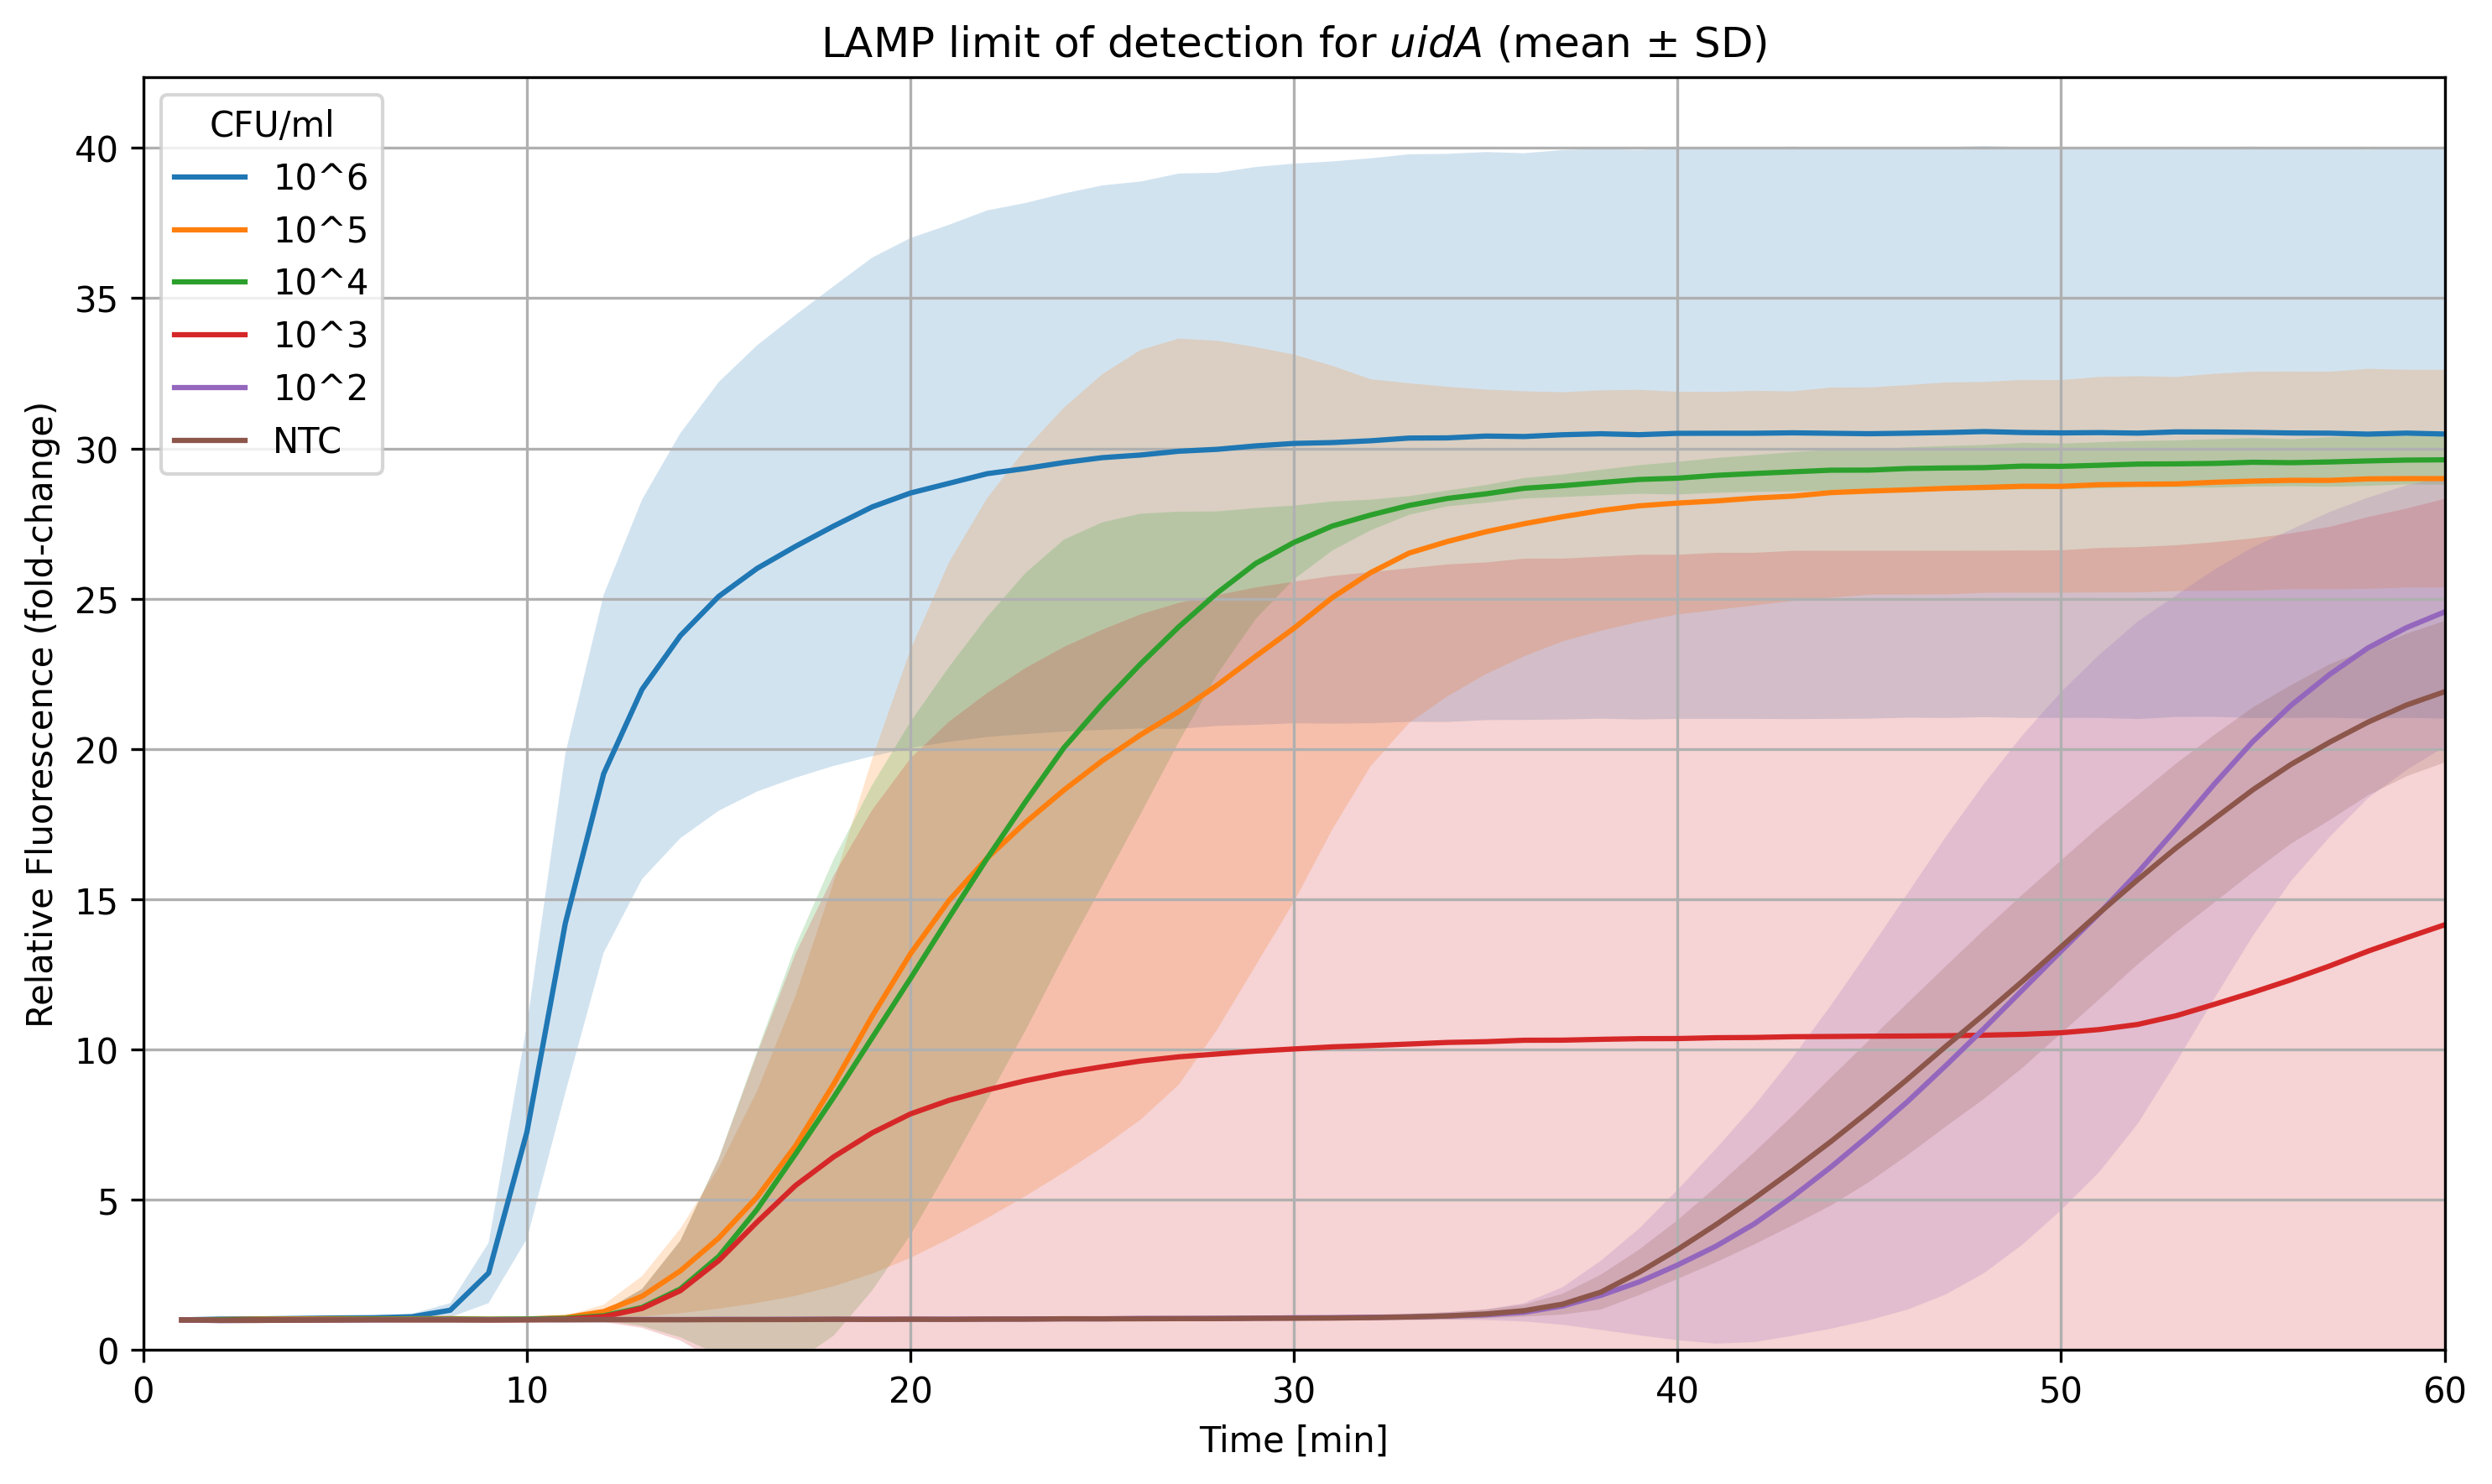

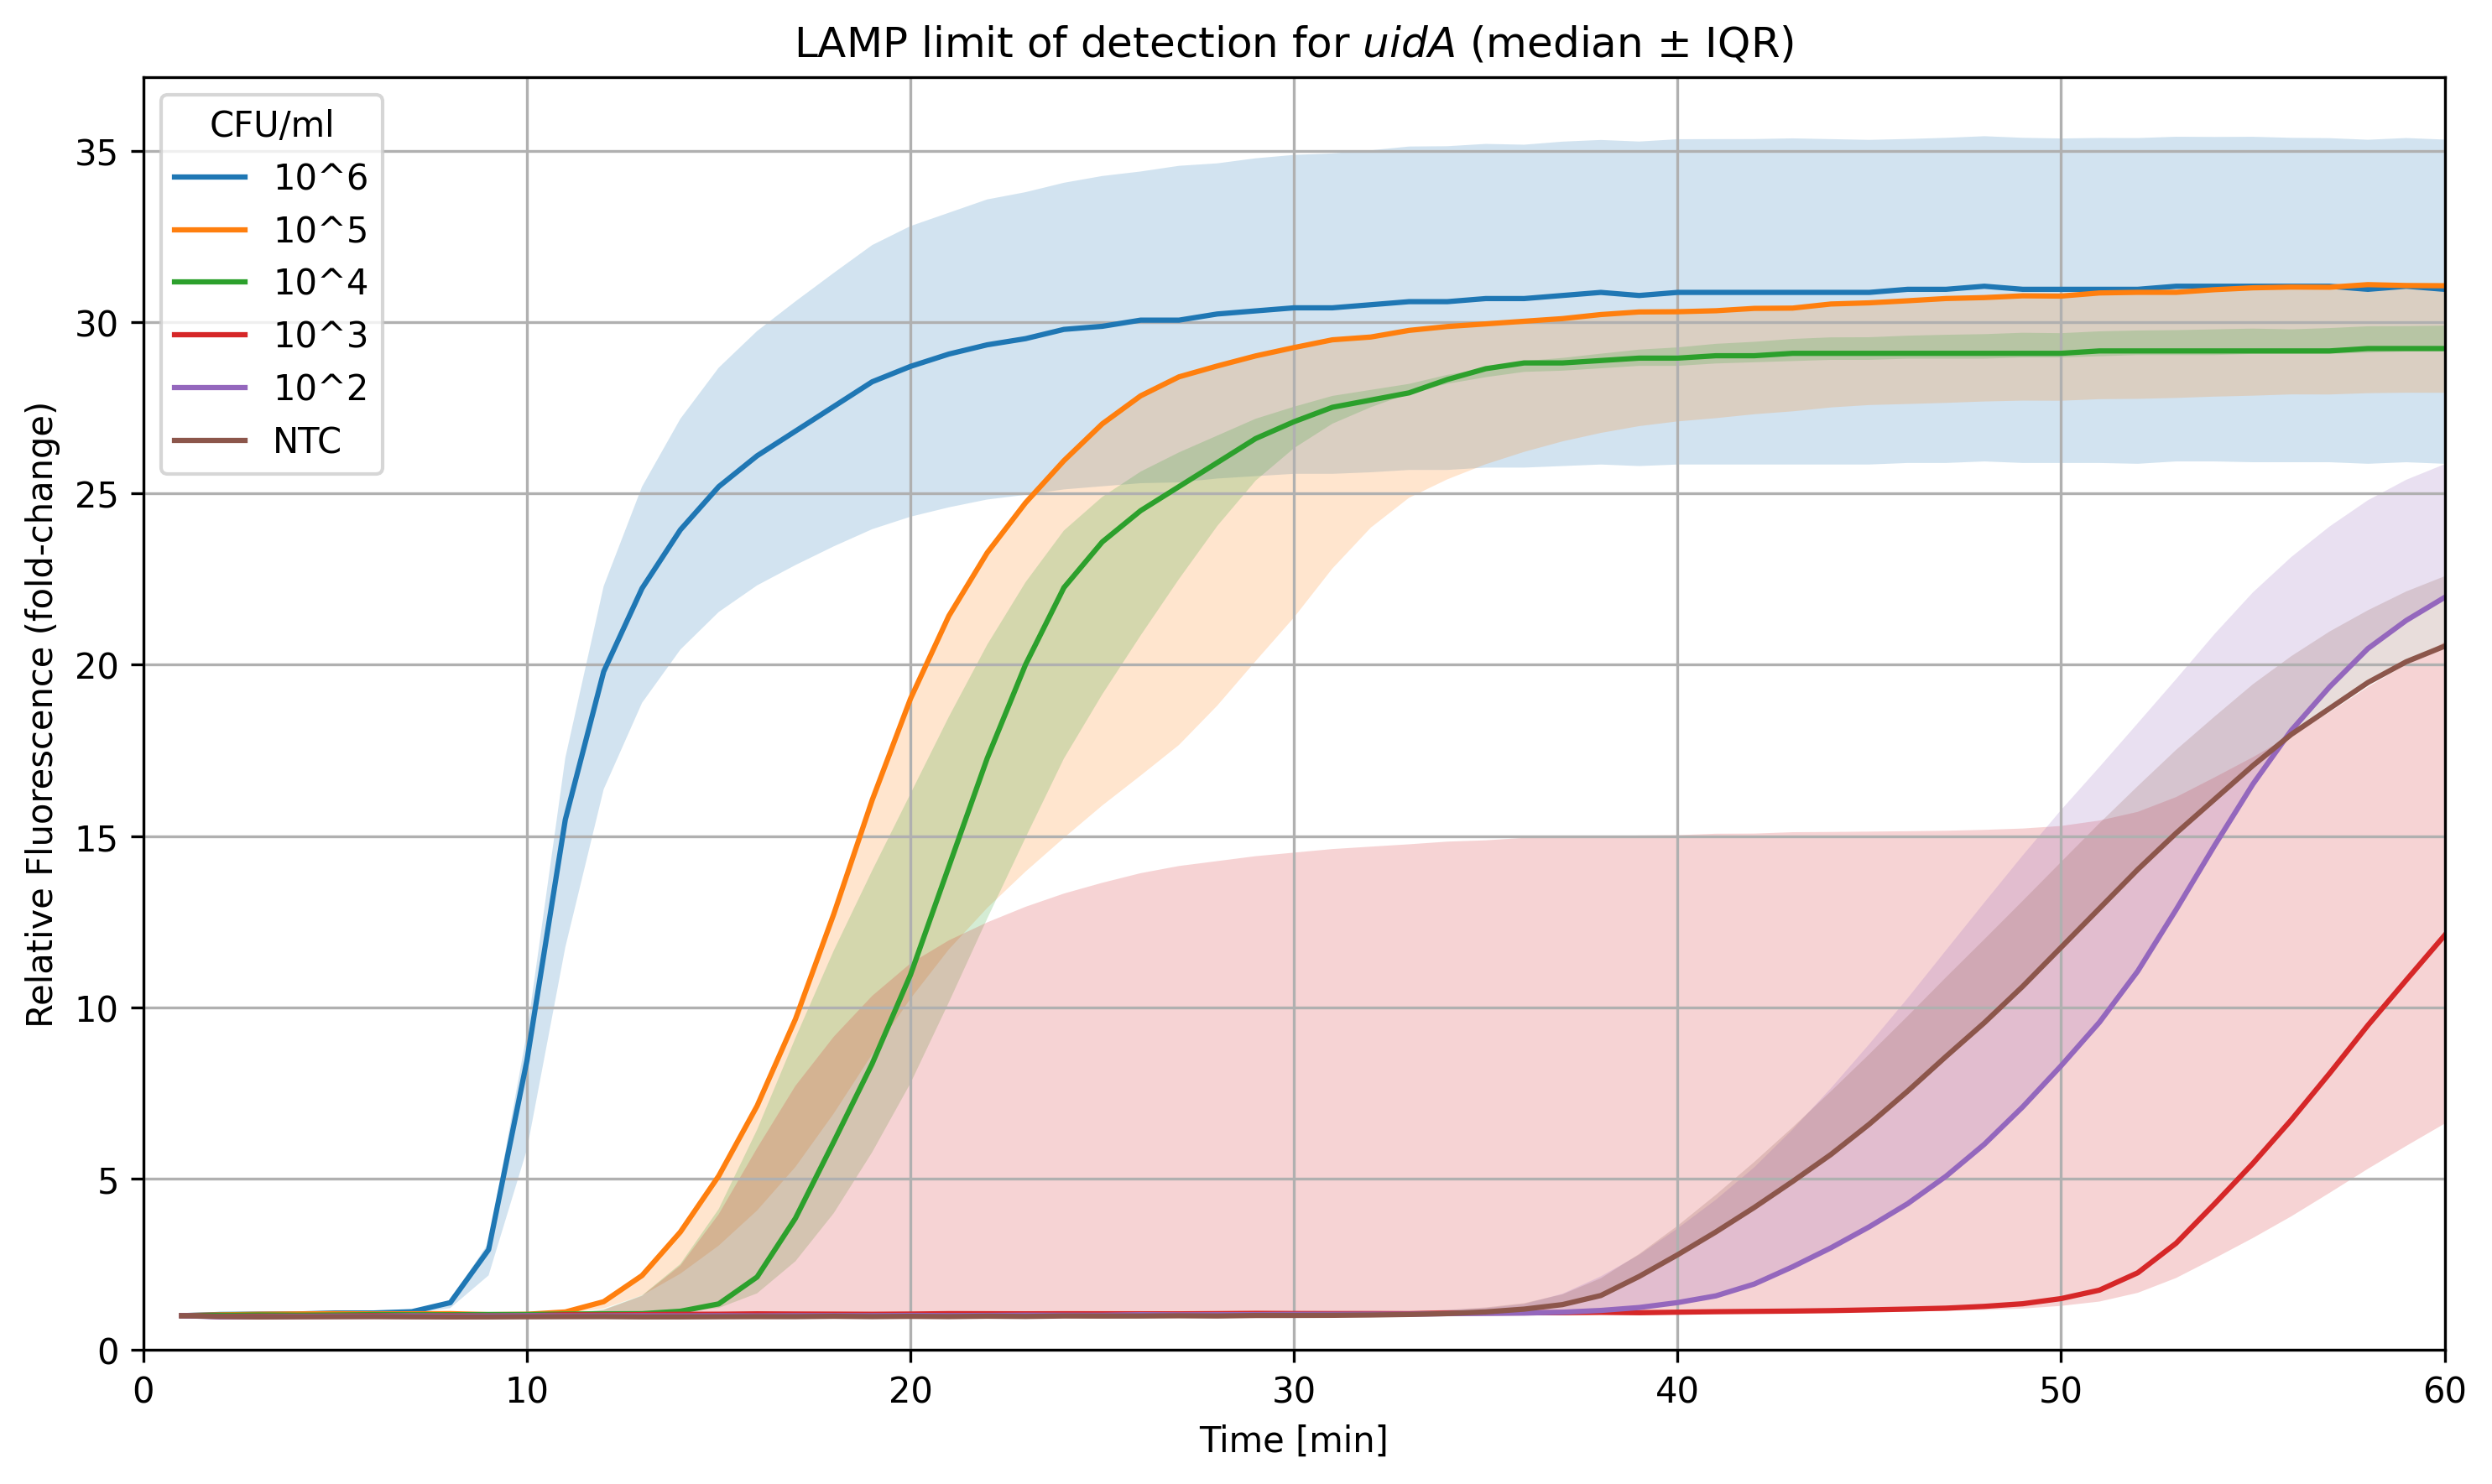

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

# High DPI for publication
mpl.rcParams['figure.dpi'] = 300

# -----------------------
# Load replicate files (relative paths)
# -----------------------

from pathlib import Path
DATA_DIR = Path("../data")  # notebook is in repo/notebook/


files = [
    DATA_DIR / "uida_lod_1.csv",
    DATA_DIR / "uida_lod_2.csv",
    DATA_DIR / "uida_lod_3.csv",
]

dfs = [pd.read_csv(f) for f in files]

# Concatenate all replicates
data = pd.concat(dfs, ignore_index=True)

# -----------------------
# Clean up column names
# -----------------------
data.columns = ["sample", "time_min", "fluorescence"]

# Extract replicate ID (_1/_2/_3) and condition (10^6, 10^5, ..., NTC)
data["replicate"] = data["sample"].str.extract(r"_(\d+)$")
data["condition"] = data["sample"].str.replace(r"_\d+$", "", regex=True)

# -----------------------
# Normalize fluorescence per sample (divide by first timepoint)
# -----------------------
baseline = data.groupby("sample")["fluorescence"].transform("first")
data["fluorescence_norm"] = data["fluorescence"] / baseline

# -----------------------
# Compute mean ± SD
# -----------------------
grouped = data.groupby(["condition", "time_min"])["fluorescence_norm"]
mean = grouped.mean().reset_index()
std = grouped.std().reset_index()

# -----------------------
# Compute median + IQR
# -----------------------
q25 = grouped.quantile(0.25).reset_index(name="q25")
q75 = grouped.quantile(0.75).reset_index(name="q75")
median = grouped.median().reset_index(name="median")

# -----------------------
# Plot mean ± SD
# -----------------------
plt.figure(figsize=(10,6))
order = ["10^6", "10^5", "10^4", "10^3", "10^2", "NTC"]

for cond in order:
    m = mean[mean["condition"] == cond]
    s = std[std["condition"] == cond]
    plt.plot(m["time_min"], m["fluorescence_norm"], label=cond)
    plt.fill_between(
        m["time_min"],
        m["fluorescence_norm"] - s["fluorescence_norm"],
        m["fluorescence_norm"] + s["fluorescence_norm"],
        alpha=0.2
    )

# Set plot limits and labels
plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("LAMP limit of detection for $\\it{uidA}$ (mean ± SD)")
plt.legend(title="CFU/ml", loc="upper left")  # Place legend in the top-left corner
plt.xlim(0, 60)  # Set x-axis to go up to 60 minutes
plt.ylim(0, None)  # Set y-axis to start at 0
plt.grid(True)  # Enable grid
plt.tight_layout()
plt.show()

# -----------------------
# Plot median + IQR
# -----------------------
plt.figure(figsize=(10,6))

for cond in order:
    m = median[median["condition"] == cond]
    q1 = q25[q25["condition"] == cond]
    q3 = q75[q75["condition"] == cond]

    plt.plot(m["time_min"], m["median"], label=cond)
    plt.fill_between(
        m["time_min"],
        q1["q25"],
        q3["q75"],
        alpha=0.2
    )

# Set plot limits and labels
plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("LAMP limit of detection for $\\it{uidA}$ (median ± IQR)")
plt.legend(title="CFU/ml", loc="upper left")  # Place legend in the top-left corner
plt.xlim(0, 60)  # Set x-axis to go up to 60 minutes
plt.ylim(0, None)  # Set y-axis to start at 0
plt.grid(True)  # Enable grid
plt.tight_layout()
plt.show()


### Corresponding analysis for *papGII* LAMP limit-of-detection (LoD): replicate aggregation and visualization

This cell loads three replicate LoD fluorescence time courses for *uidA* from `../data/`:

- `papg_lod_1.csv`, `papg_lod_2.csv`, `papg_lod_3.csv`

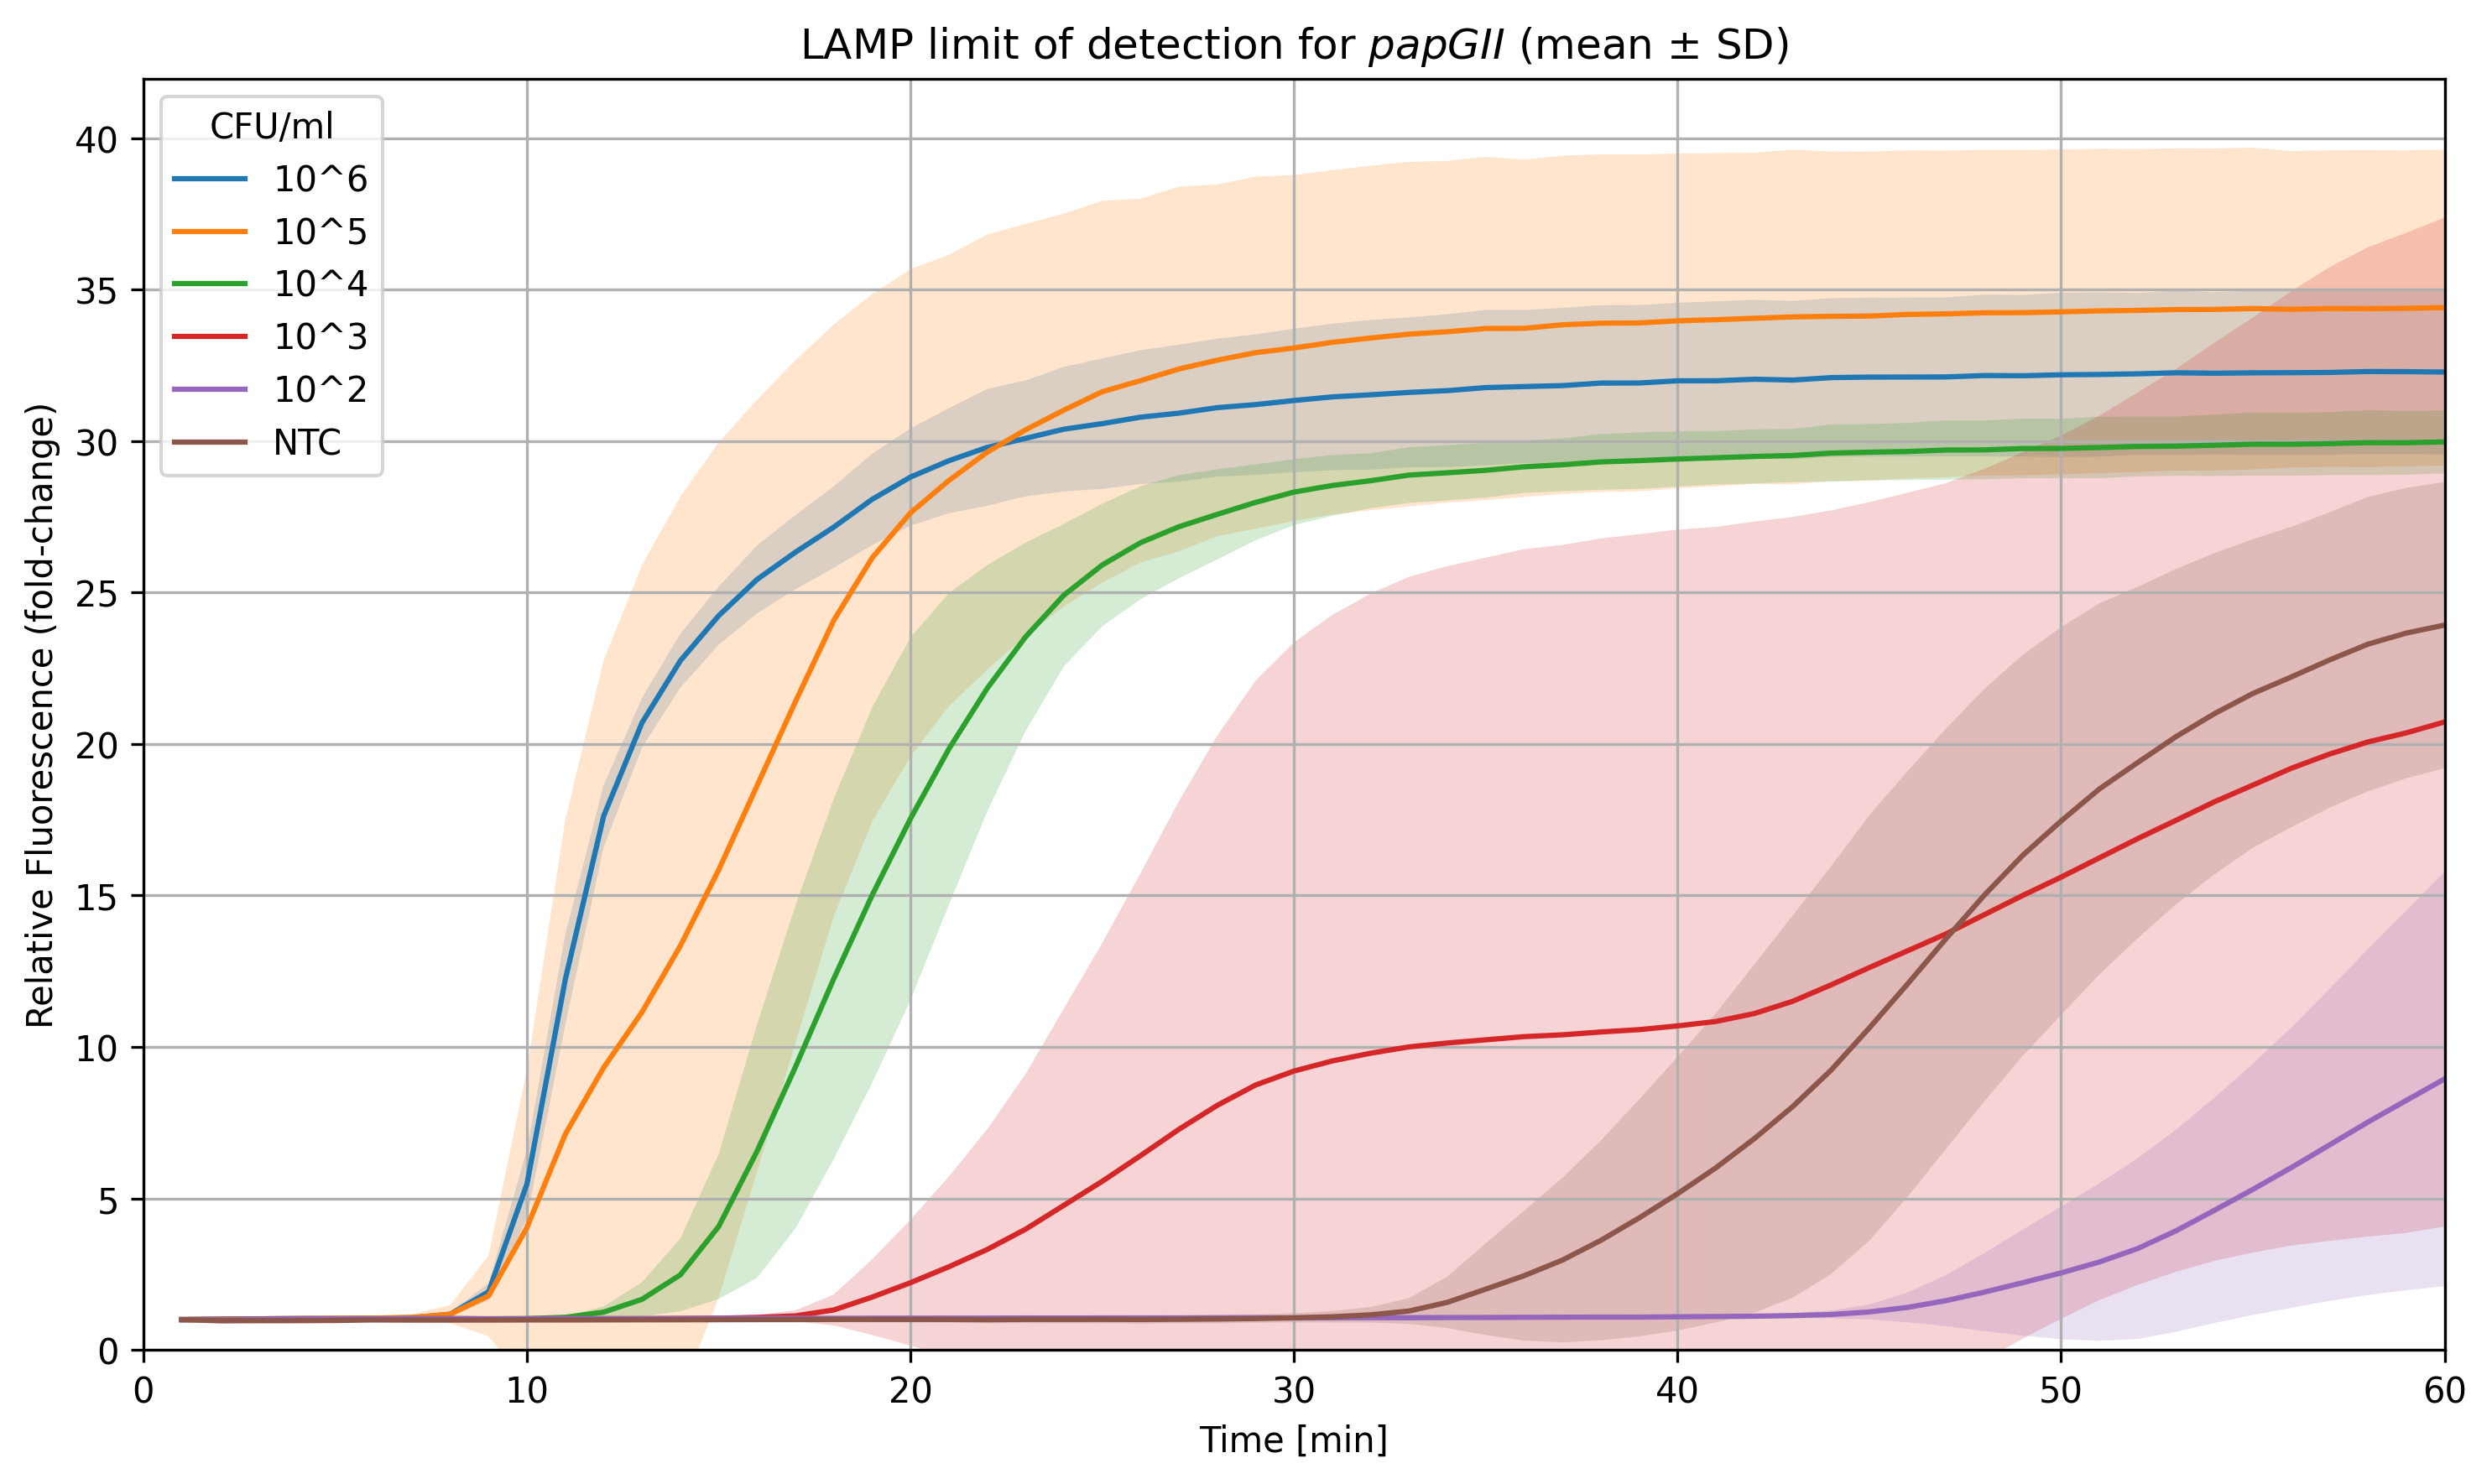

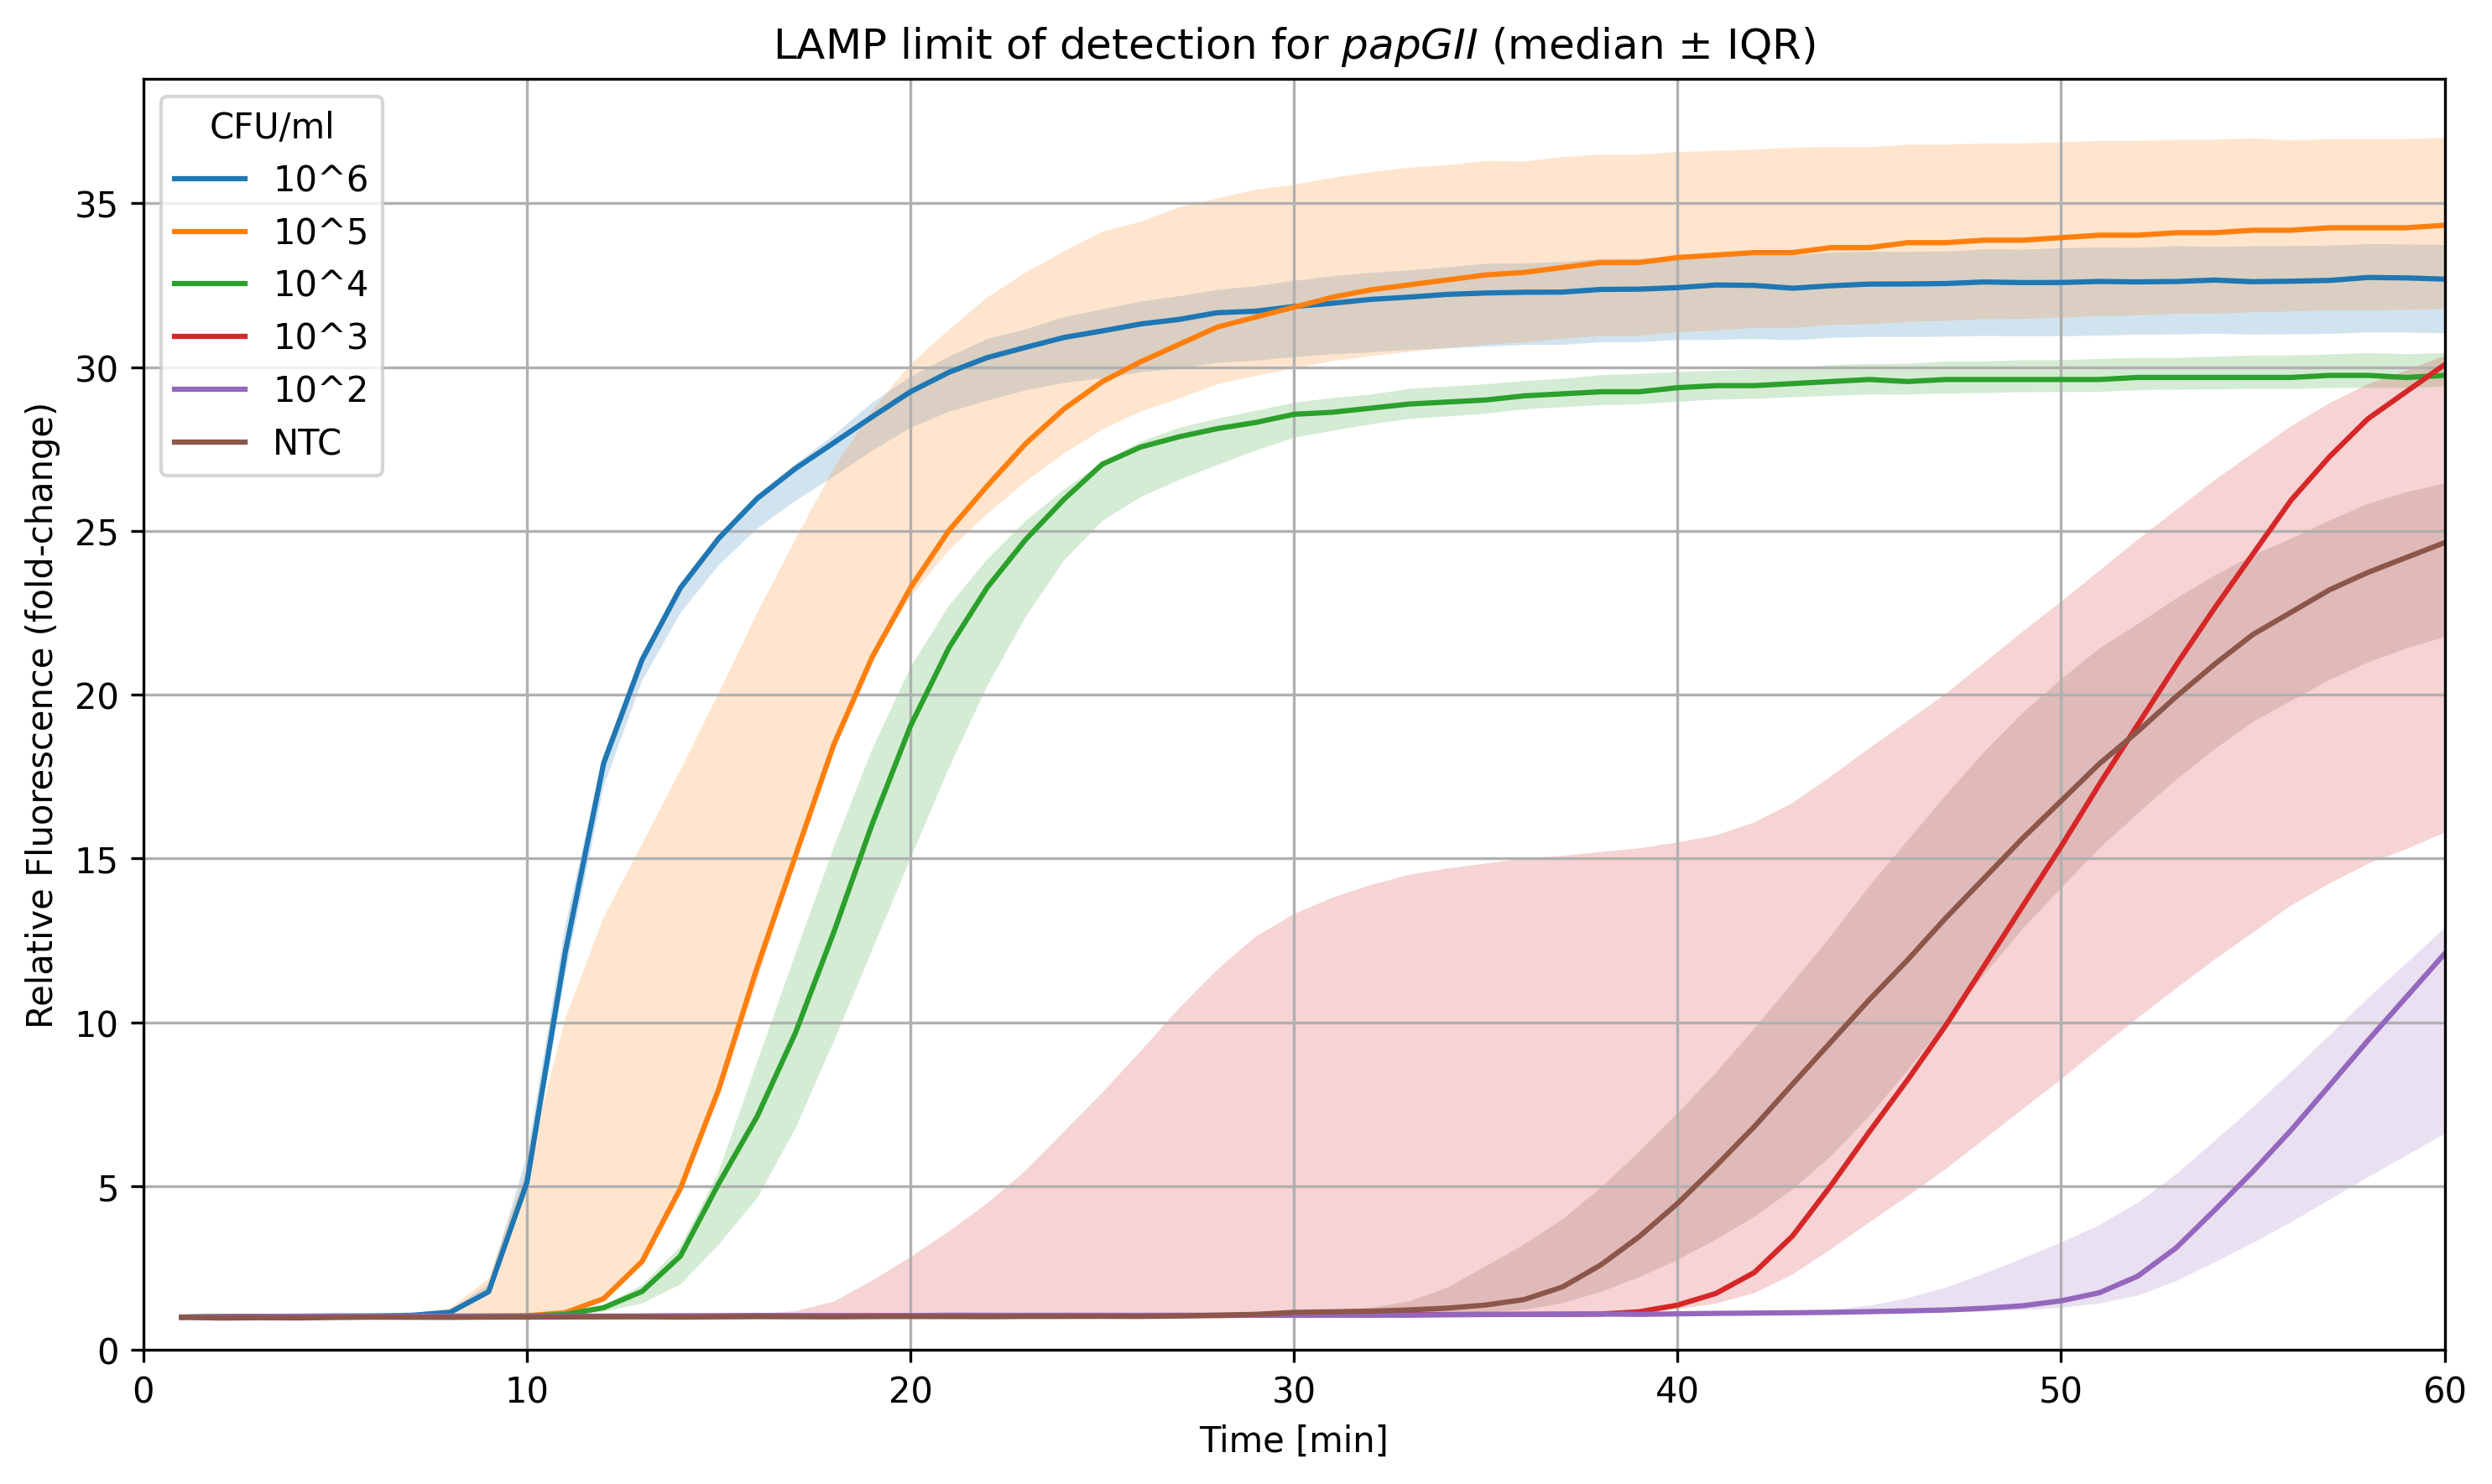

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path

# High DPI for publication
mpl.rcParams['figure.dpi'] = 300

# -----------------------
# Load replicate files (relative paths; notebook in repo/notebook/)
# -----------------------
DATA_DIR = Path("../data")

files = [
    DATA_DIR / "papg_lod_1.csv",
    DATA_DIR / "papg_lod_2.csv",
    DATA_DIR / "papg_lod_3.csv",
]

dfs = [pd.read_csv(f) for f in files]

# Concatenate all replicates
data = pd.concat(dfs, ignore_index=True)

# -----------------------
# Clean up column names
# -----------------------
data.columns = ["sample", "time_min", "fluorescence"]

# Extract replicate ID (_1/_2/_3) and condition (10^6, 10^5, ..., NTC)
data["replicate"] = data["sample"].str.extract(r"_(\d+)$")
data["condition"] = data["sample"].str.replace(r"_\d+$", "", regex=True)

# -----------------------
# Normalize fluorescence per sample (divide by first timepoint)
# -----------------------
baseline = data.groupby("sample")["fluorescence"].transform("first")
data["fluorescence_norm"] = data["fluorescence"] / baseline

# -----------------------
# Compute mean ± SD
# -----------------------
grouped = data.groupby(["condition", "time_min"])["fluorescence_norm"]
mean = grouped.mean().reset_index()
std = grouped.std().reset_index()

# -----------------------
# Compute median + IQR
# -----------------------
q25 = grouped.quantile(0.25).reset_index(name="q25")
q75 = grouped.quantile(0.75).reset_index(name="q75")
median = grouped.median().reset_index(name="median")

# -----------------------
# Plot mean ± SD
# -----------------------
plt.figure(figsize=(10,6))
order = ["10^6", "10^5", "10^4", "10^3", "10^2", "NTC"]

for cond in order:
    m = mean[mean["condition"] == cond]
    s = std[std["condition"] == cond]
    plt.plot(m["time_min"], m["fluorescence_norm"], label=cond)
    plt.fill_between(
        m["time_min"],
        m["fluorescence_norm"] - s["fluorescence_norm"],
        m["fluorescence_norm"] + s["fluorescence_norm"],
        alpha=0.2
    )

# Set plot limits and labels
plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("LAMP limit of detection for $\\it{papGII}$ (mean ± SD)")
plt.legend(title="CFU/ml", loc="upper left")  # Place legend in the top-left corner
plt.xlim(0, 60)  # Set x-axis to go up to 60 minutes
plt.ylim(0, None)  # Set y-axis to start at 0
plt.grid(True)  # Enable grid
plt.tight_layout()
plt.show()

# -----------------------
# Plot median + IQR
# -----------------------
plt.figure(figsize=(10,6))

for cond in order:
    m = median[median["condition"] == cond]
    q1 = q25[q25["condition"] == cond]
    q3 = q75[q75["condition"] == cond]

    plt.plot(m["time_min"], m["median"], label=cond)
    plt.fill_between(
        m["time_min"],
        q1["q25"],
        q3["q75"],
        alpha=0.2
    )

# Set plot limits and labels
plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("LAMP limit of detection for $\\it{papGII}$ (median ± IQR)")
plt.legend(title="CFU/ml", loc="upper left")  # Place legend in the top-left corner
plt.xlim(0, 60)  # Set x-axis to go up to 60 minutes
plt.ylim(0, None)  # Set y-axis to start at 0
plt.grid(True)  # Enable grid
plt.tight_layout()
plt.show()


### *uidA* fluorescence kinetics by culture status (normalization, summary curves, and time-to-threshold)

This cell analyzes fluorescence time courses for the *uidA* assay using the full fluorescence matrix and culture reference labels:

- Fluorescence matrix: `../data/all_measurements_uida.csv`  
  (wide format with one column per sample and a `Cycle` column)
- Reference labels: `../data/culture_results.csv`  
  (contains `sample` and `culture_result`, where `1 = culture positive`, `0 = culture negative`)

#### Data reshaping and harmonization
- Sample identifiers are stripped of whitespace to ensure exact matches between the fluorescence matrix and the culture reference table.
- The wide fluorescence matrix is converted to **long format** with columns:
  - `Cycle`, `sample`, `fluorescence`

#### Fold-change normalization (within code)
Fluorescence is converted to fold-change per sample relative to **Cycle = 1**:

\[
\text{fold-change}_{i,c} = \frac{F_{i,c}}{F_{i,1}}
\]

where \(F_{i,c}\) is fluorescence for sample \(i\) at cycle \(c\), and \(F_{i,1}\) is the baseline at cycle 1 for that sample. The normalized signal is stored as `fluorescence_norm`.

#### Time conversion
Cycles are converted to minutes using:

\[
t\_{\text{min}} = \text{Cycle} \times \text{cycle\_time}
\]

with `cycle_time = 1.0` minute per cycle.

---

## Summary plots (culture positive vs culture negative)

Samples are grouped by (`culture_result`, `time_min`) and summarized using two complementary approaches:

1. **Mean ± SD** of `fluorescence_norm` over time  
   A line plot is shown for each group (positive vs negative) with a shaded region representing ±1 SD.

2. **Median ± IQR** of `fluorescence_norm` over time  
   A line plot is shown for each group with a shaded region spanning the interquartile range (25th–75th percentile).

Axes:
- x-axis: Time [min] (0–40)
- y-axis: Relative fluorescence (fold-change)

---

## Time-to-threshold (Tt)

A time-to-threshold (Tt) is computed per sample using a fixed fold-change cutoff (`cutoff_fluo = 3.0`):

\[
Tt_i = \min \{ t : \text{fold-change}_i(t) \ge 3.0 \}
\]

- If a sample never reaches the threshold, `Tt` is recorded as missing (`NaN`).
- A histogram is plotted for culture-positive and culture-negative samples, and the number of negatives that never cross the threshold is reported on the plot.

Output:
- One histogram showing the distribution of Tt values (0–40 minutes) for positives vs negatives.


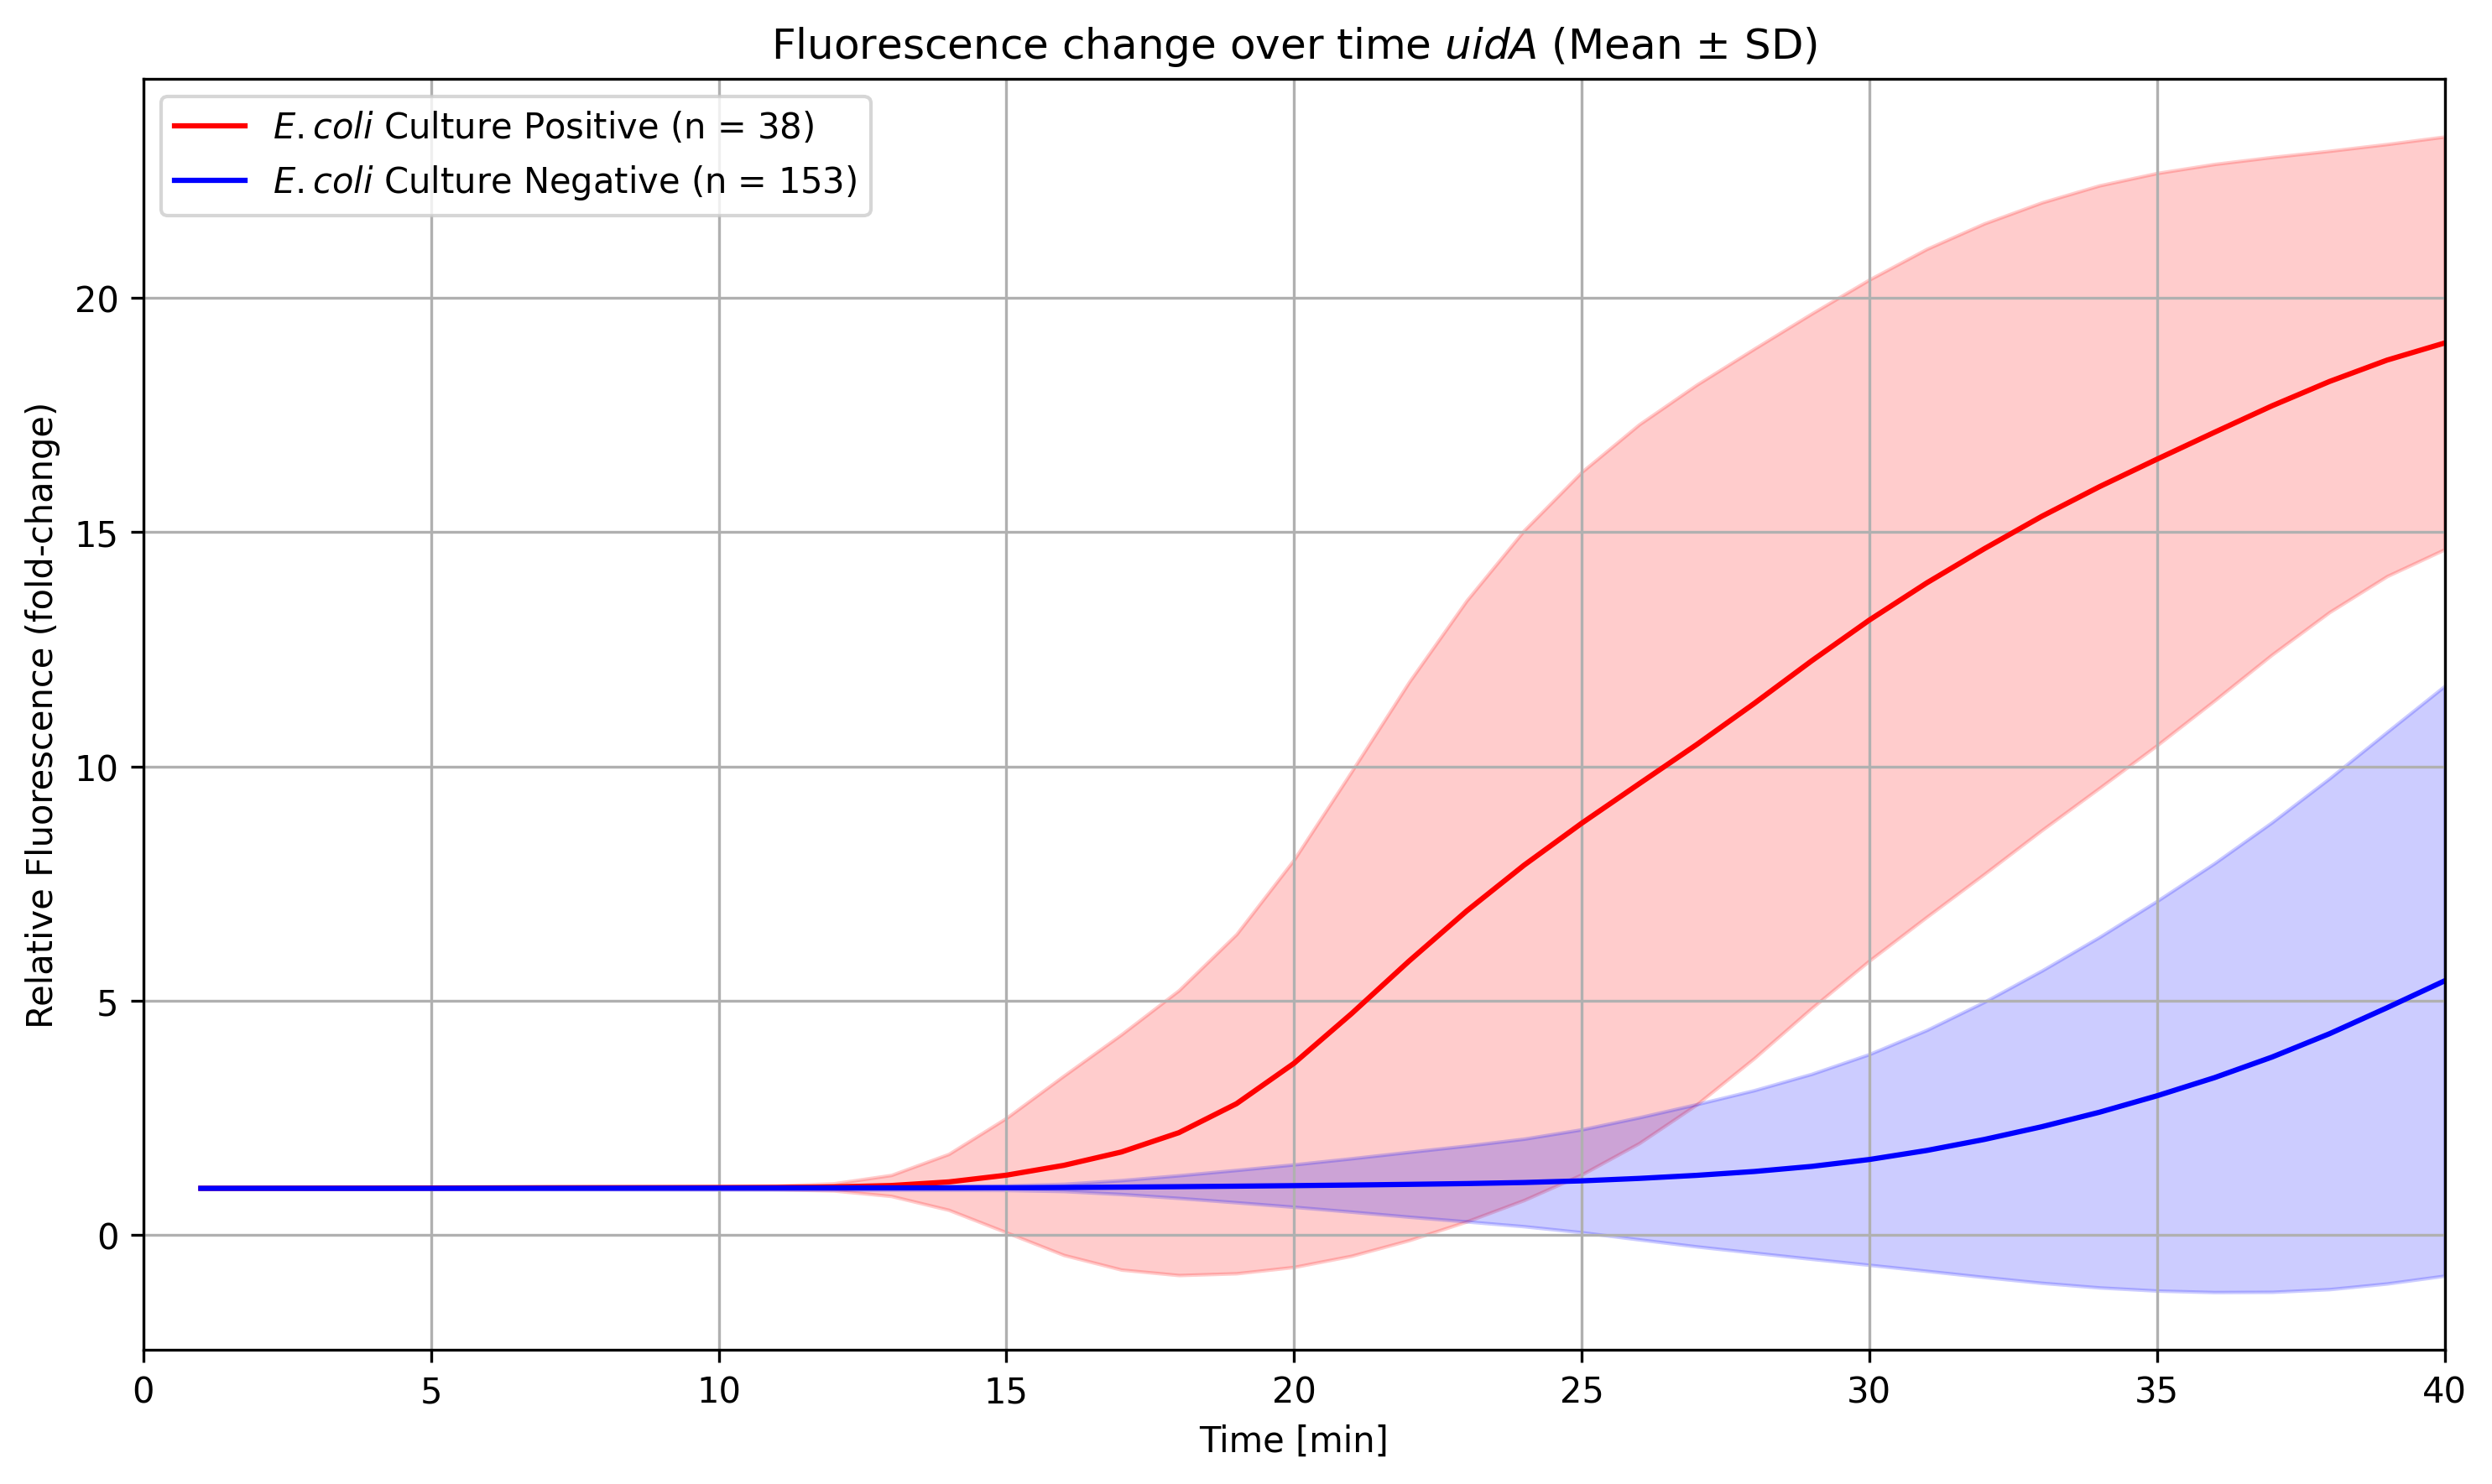

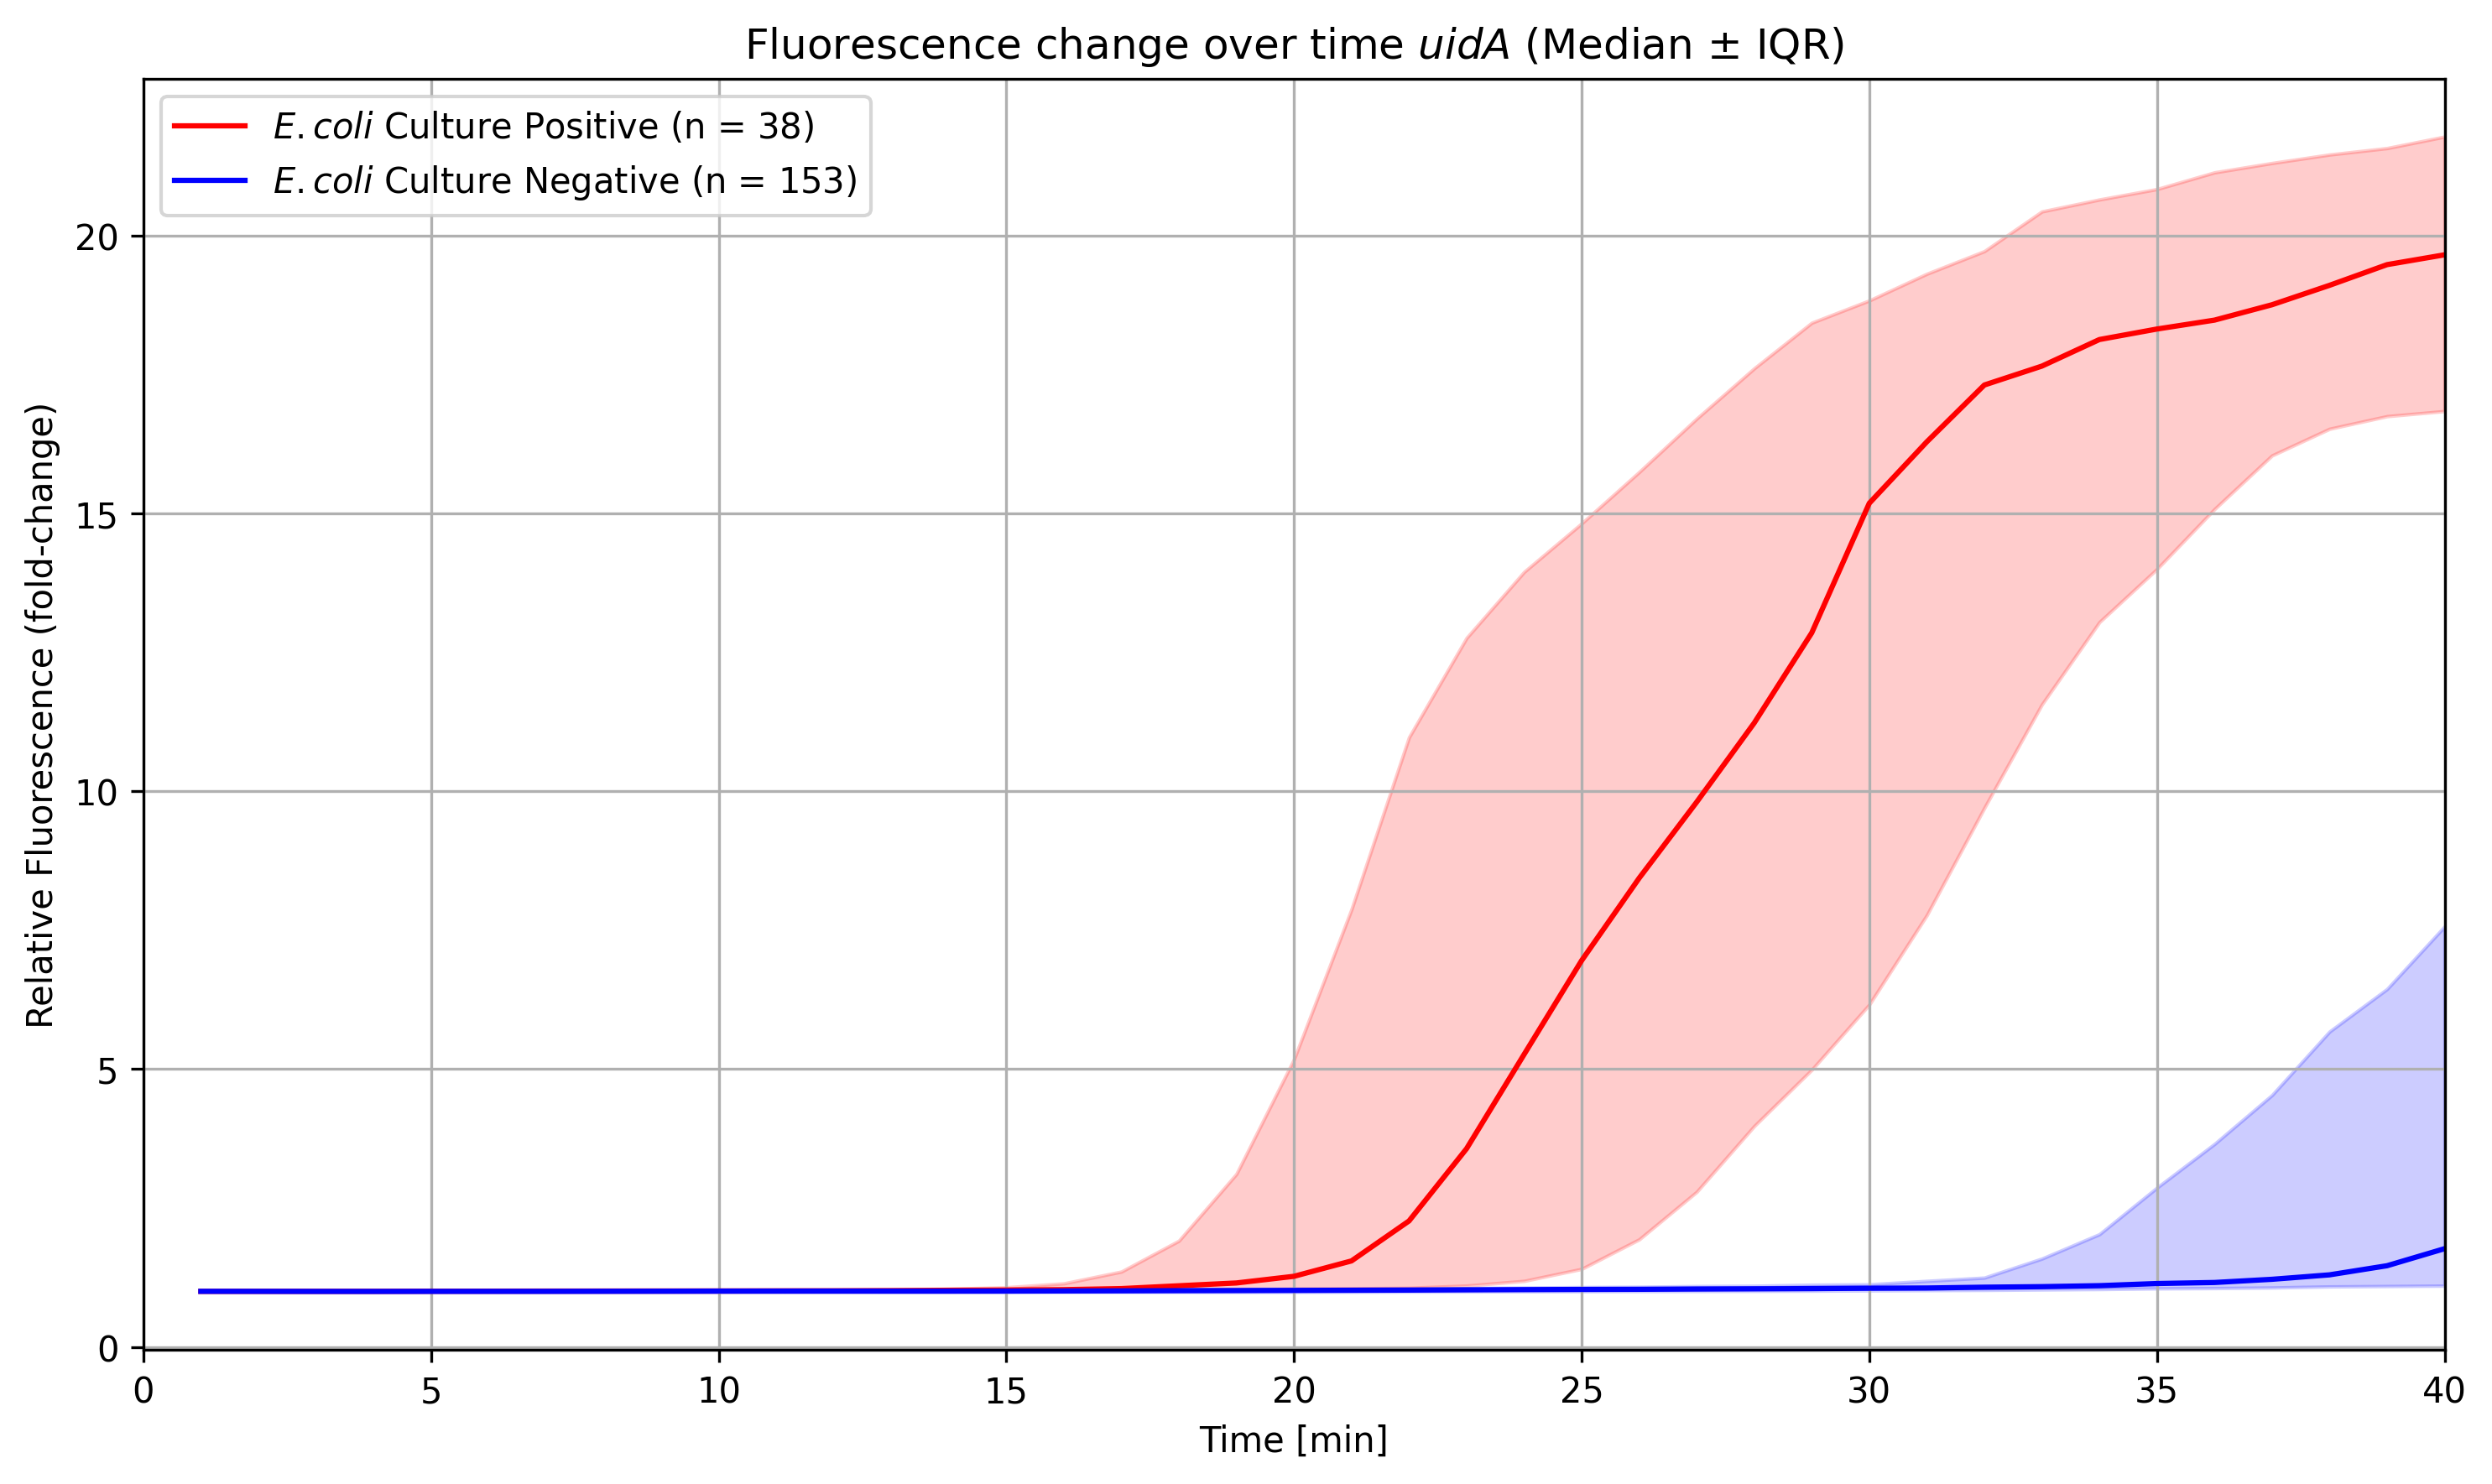

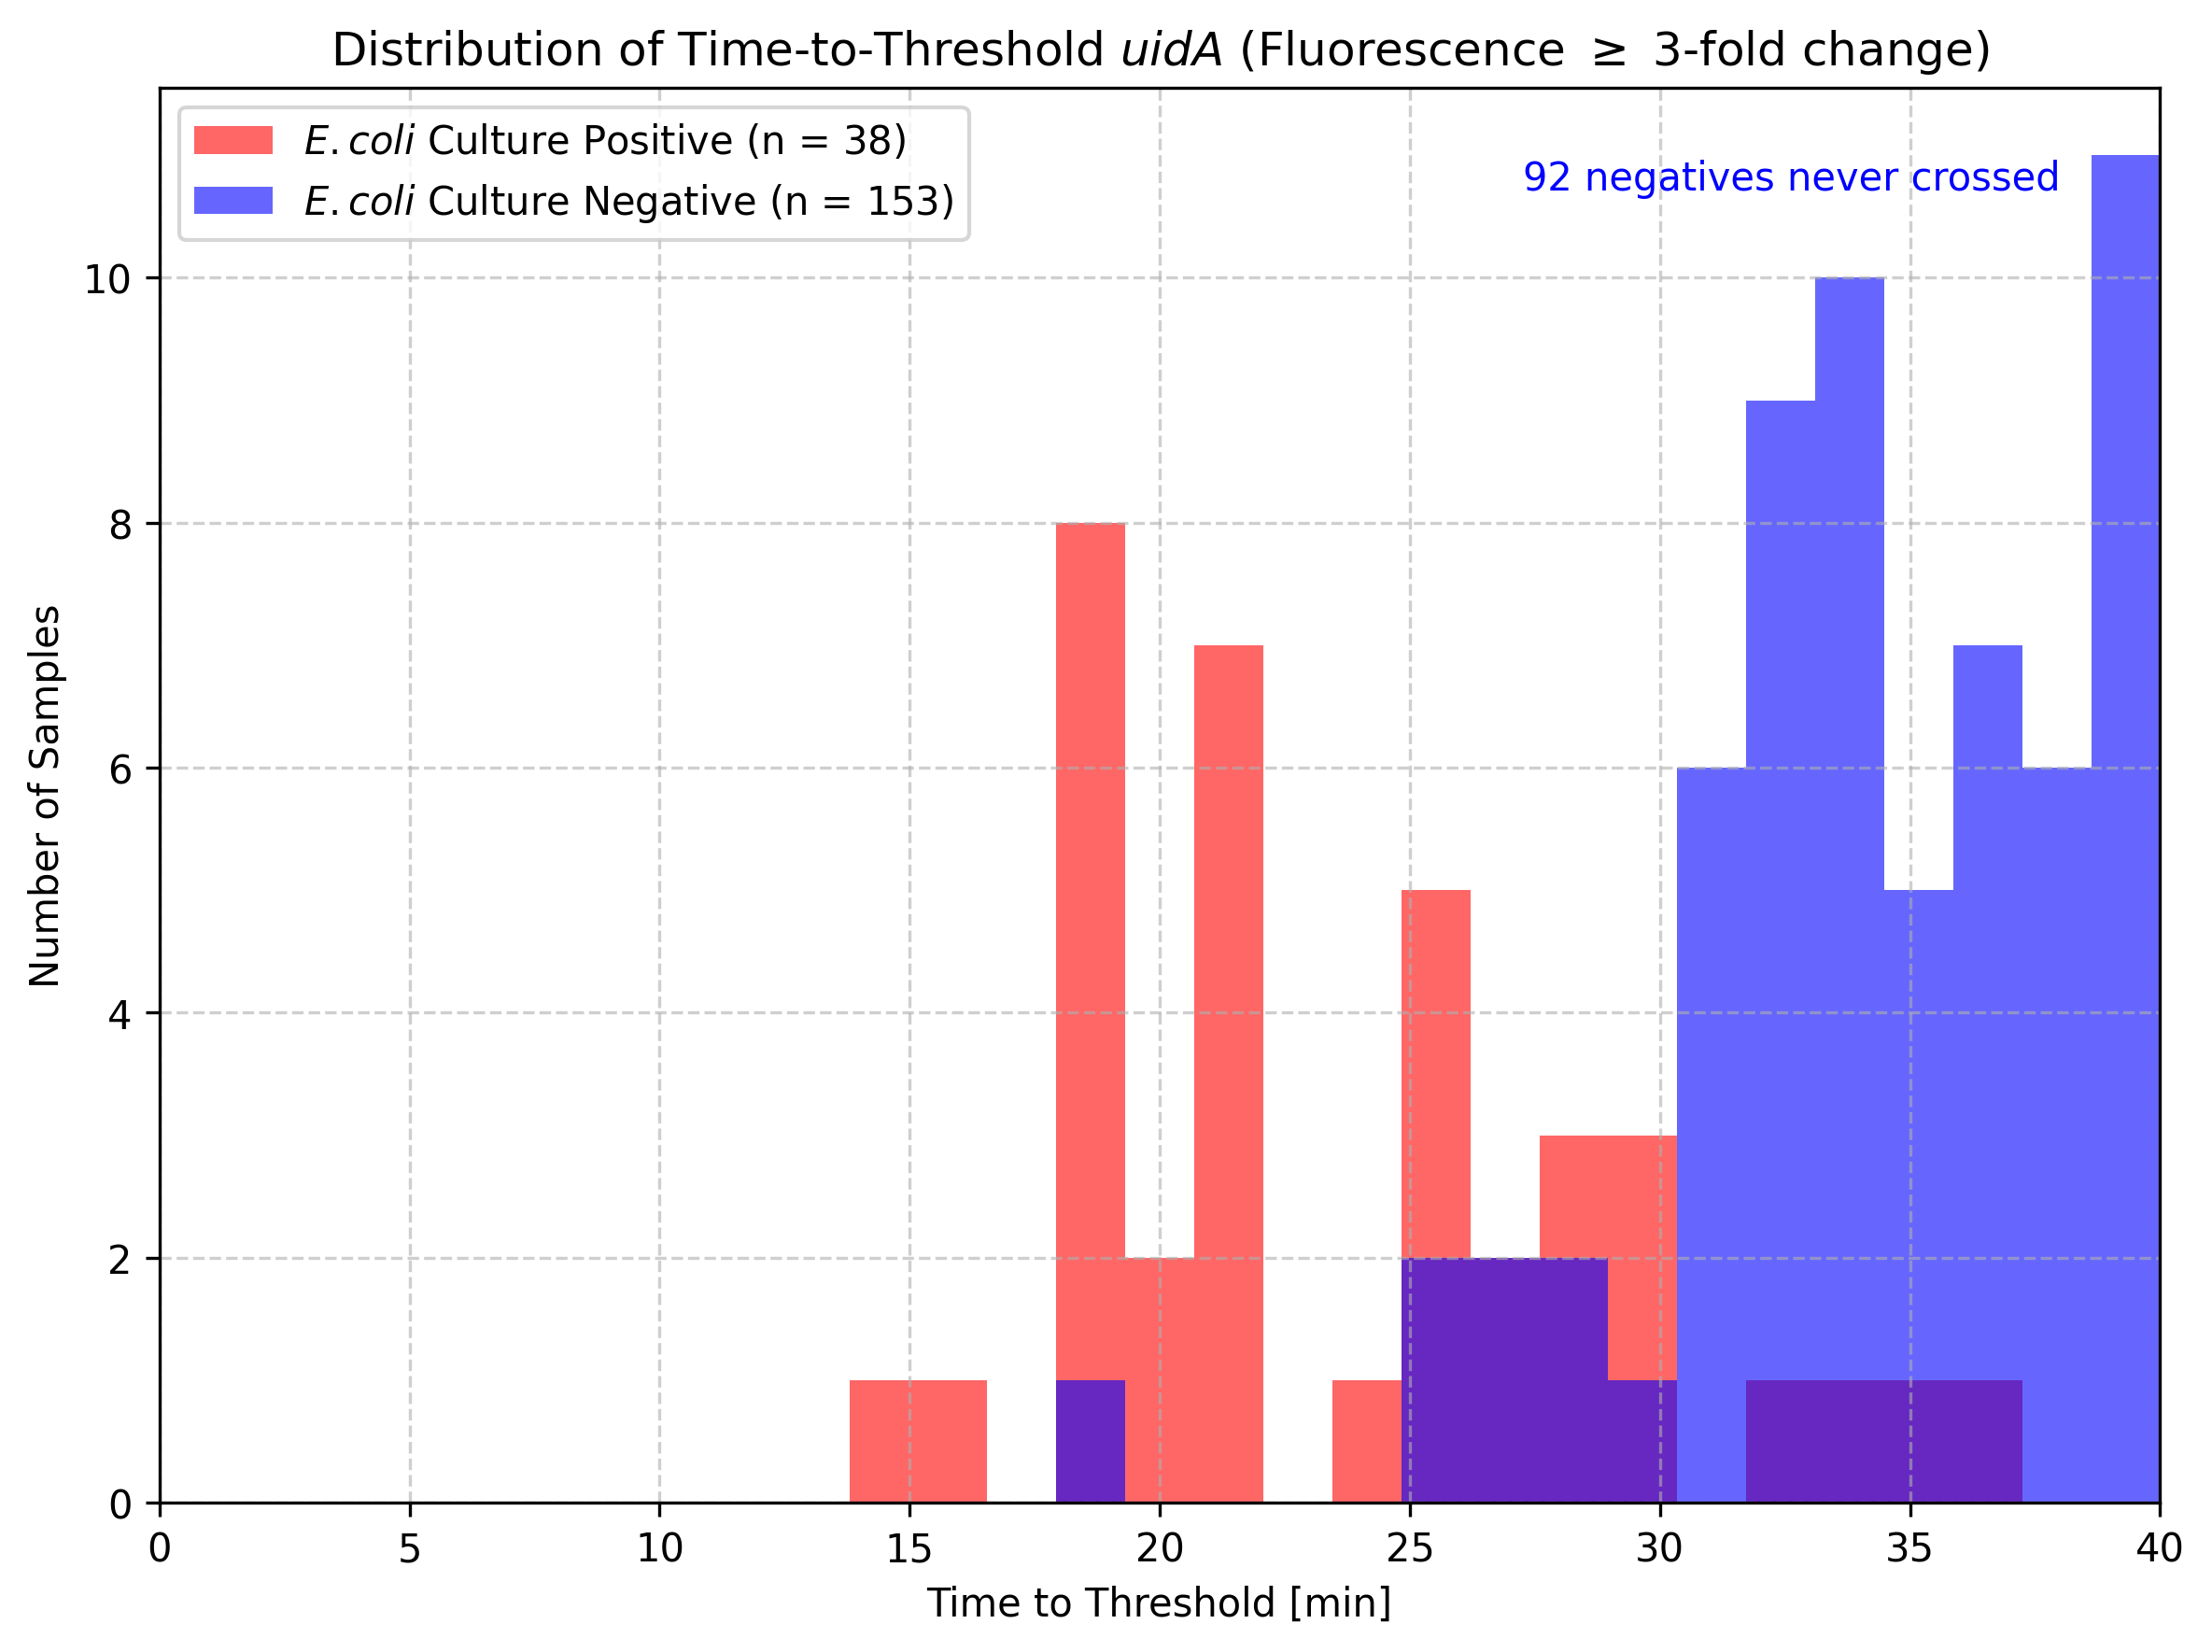

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------
# CONFIG
# -----------------------
cycle_time = 1.0  # minutes per cycle
cutoff_fluo = 3.0

# notebook is in repo/notebook/, data is in repo/data/
DATA_DIR = Path("../data")
raw_file = DATA_DIR / "all_measurements_uida.csv"
culture_file = DATA_DIR / "culture_results.csv"

# -----------------------
# Load data
# -----------------------
raw_fluo = pd.read_csv(raw_file)
culture = pd.read_csv(culture_file)

# Ensure sample IDs match
culture['sample'] = culture['sample'].astype(str).str.strip()
raw_fluo.columns = raw_fluo.columns.astype(str).str.strip()

# Melt into long format
raw_long = raw_fluo.melt(id_vars=["Cycle"], var_name="sample", value_name="fluorescence")

# -----------------------
# Normalize: convert to fold-change relative to cycle 1
# -----------------------
# get baseline per sample (fluorescence at Cycle = 1)
baseline = raw_long[raw_long["Cycle"] == 1][["sample", "fluorescence"]].rename(columns={"fluorescence": "baseline"})
raw_long = raw_long.merge(baseline, on="sample")
raw_long["fluorescence_norm"] = raw_long["fluorescence"] / raw_long["baseline"]

# Merge with culture results
raw_long = raw_long.merge(culture, on="sample")

# Convert cycles → time
raw_long["time_min"] = raw_long["Cycle"] * cycle_time

# -----------------------
# Mean ± SD plots
# -----------------------
grouped = raw_long.groupby(["culture_result", "time_min"])["fluorescence_norm"]
mean = grouped.mean().reset_index()
std = grouped.std().reset_index()

plt.figure(figsize=(10,6))
colors = {1: "red", 0: "blue"}
labels = {1: "$\\it{E. coli}$ Culture Positive (n = 38)", 0: "$\\it{E. coli}$ Culture Negative (n = 153)"}

for label in [1, 0]:
    m = mean[mean["culture_result"] == label]
    s = std[std["culture_result"] == label]

    plt.plot(m["time_min"], m["fluorescence_norm"], color=colors[label], label=labels[label])
    plt.fill_between(m["time_min"],
                     m["fluorescence_norm"] - s["fluorescence_norm"],
                     m["fluorescence_norm"] + s["fluorescence_norm"],
                     color=colors[label], alpha=0.2)

plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("Fluorescence change over time $\\it{uidA}$ (Mean ± SD)")
plt.legend()
plt.grid(True)
plt.xlim(0, 40)  # Limit x-axis to 40 minutes
plt.tight_layout()
plt.show()

# -----------------------
# Median ± IQR plots
# -----------------------
median = grouped.median().reset_index()
q25 = grouped.quantile(0.25).reset_index()
q75 = grouped.quantile(0.75).reset_index()

plt.figure(figsize=(10,6))

for label in [1, 0]:
    m = median[median["culture_result"] == label]
    q1 = q25[q25["culture_result"] == label]
    q3 = q75[q75["culture_result"] == label]

    plt.plot(m["time_min"], m["fluorescence_norm"], color=colors[label], label=labels[label])
    plt.fill_between(m["time_min"],
                     q1["fluorescence_norm"],
                     q3["fluorescence_norm"],
                     color=colors[label], alpha=0.2)

plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("Fluorescence change over time $\\it{uidA}$ (Median ± IQR)")
plt.legend()
plt.grid(True)
plt.xlim(0, 40)  # Limit x-axis to 40 minutes
plt.tight_layout()
plt.show()

# -----------------------
# Time-to-Threshold (Tt) Histogram
# -----------------------
def compute_Tt(df, cutoff):
    above = df[df["fluorescence_norm"] >= cutoff]
    if above.empty:
        return np.nan
    return above["time_min"].iloc[0]

tt_list = []
for sample, group in raw_long.groupby("sample"):
    tt = compute_Tt(group.sort_values("time_min"), cutoff_fluo)
    culture_result = group["culture_result"].iloc[0]
    tt_list.append((sample, culture_result, tt))

tt_df = pd.DataFrame(tt_list, columns=["sample", "culture_result", "time_to_threshold"])
tt_df = tt_df[tt_df["sample"] != "NTC"]   # the no-template control is not a sample

plt.figure(figsize=(8,6))
pos = tt_df[tt_df["culture_result"] == 1]["time_to_threshold"].dropna()
neg = tt_df[tt_df["culture_result"] == 0]["time_to_threshold"].dropna()

# Adjust x-axis bins to go from 0 to 40 minutes
bins = np.linspace(0, 40, 30)

plt.hist(pos, bins=bins, alpha=0.6, color="red", label="$\\it{E. coli}$ Culture Positive (n = 38)")
plt.hist(neg, bins=bins, alpha=0.6, color="blue", label="$\\it{E. coli}$ Culture Negative (n = 153)")

# Display number of negative samples that did not cross the threshold
num_uncrossed = tt_df[(tt_df["culture_result"] == 0) & (tt_df["time_to_threshold"].isna())].shape[0]
if num_uncrossed > 0:
    plt.text(0.5, 0.95, f"{num_uncrossed} negatives did not cross\nthe threshold within 40 min",
             ha="center", va="top", transform=plt.gca().transAxes, fontsize=10, color="blue")

# Set x-axis and y-axis labels
plt.xlabel("Time to Threshold [min]")
plt.ylabel("Number of Samples")

# Set the title
plt.title("Distribution of Time-to-Threshold $\\it{uidA}$ (Fluorescence $\geq$ 3-fold change)")

# Add grid, legend, and tight layout
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Set the x-axis to go from 0 to 40 minutes
plt.xlim(0, 40)

# Apply tight layout for better spacing
plt.tight_layout()
plt.show()


### Corresponding analysis for *papGII* fluorescence kinetics by culture status (normalization, summary curves, and time-to-threshold)

This cell analyzes fluorescence time courses for the *uidA* assay using the full fluorescence matrix and culture reference labels:

- Fluorescence matrix: `../data/all_measurements_papg.csv`  
  (wide format with one column per sample and a `Cycle` column)
- Reference labels: `../data/papg_results.csv`  
  (contains `sample` and `papg_result`, where `1 = papGII WGS positive`, `0 = papGII WGS negative`)

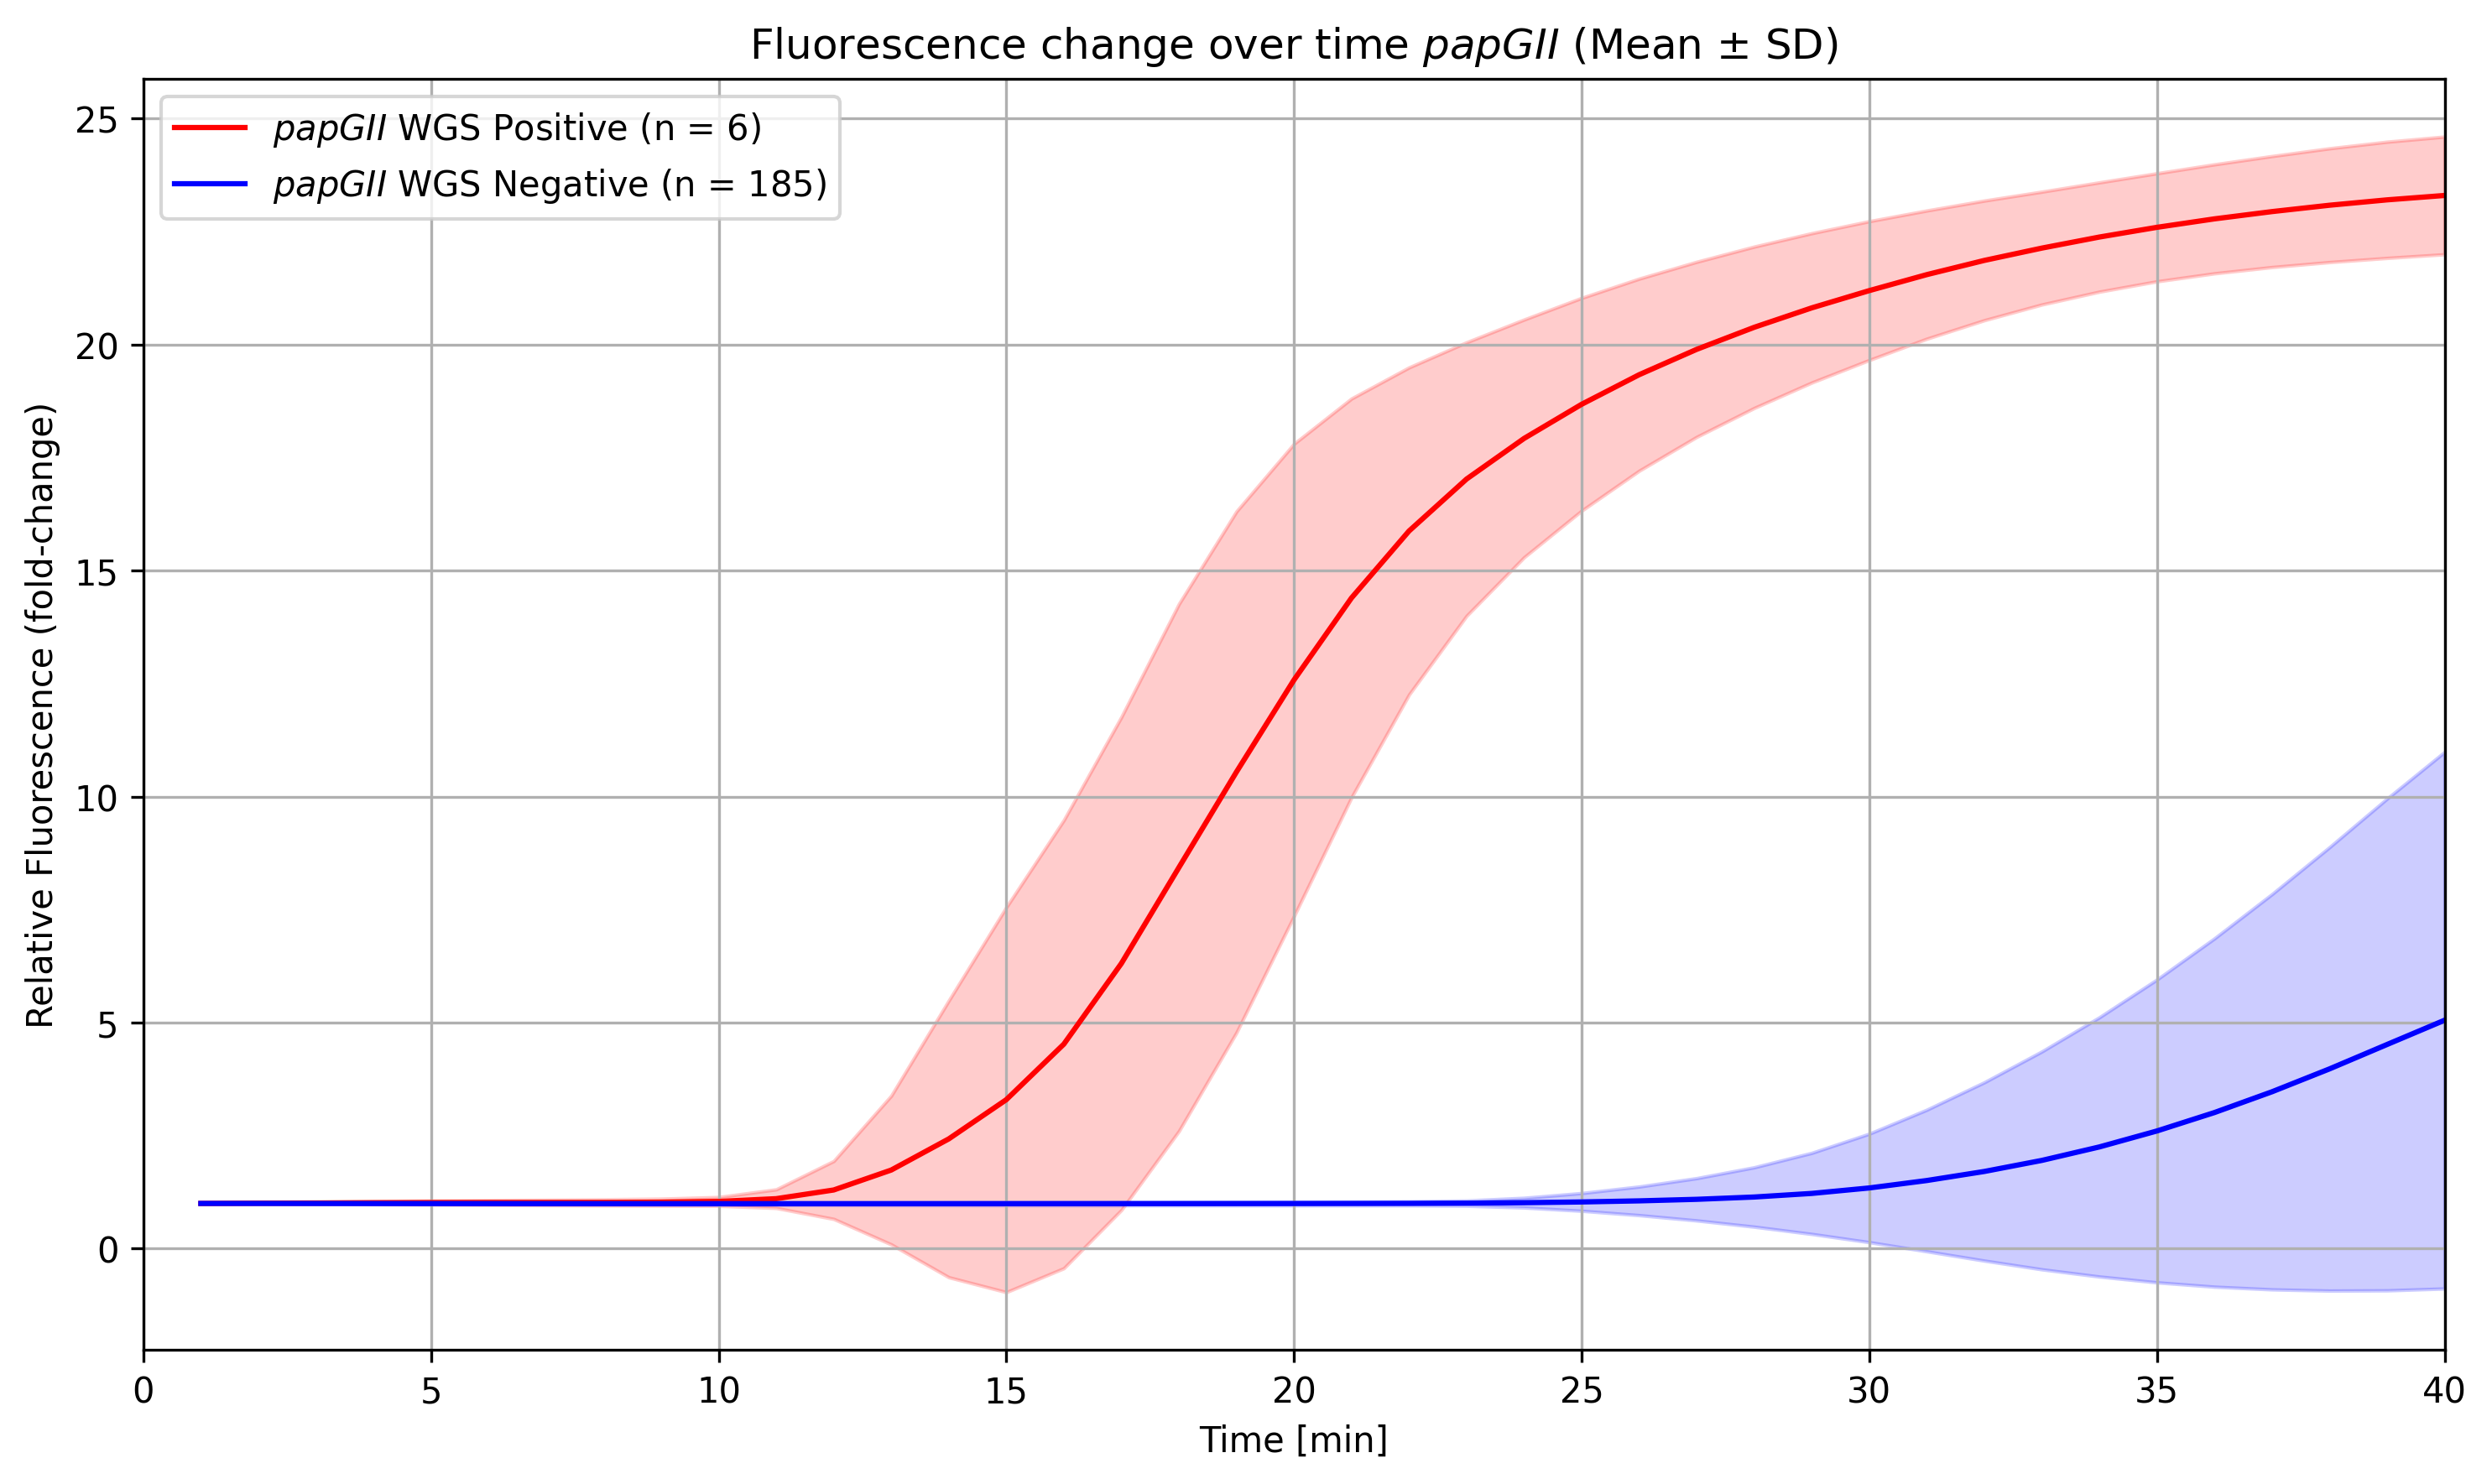

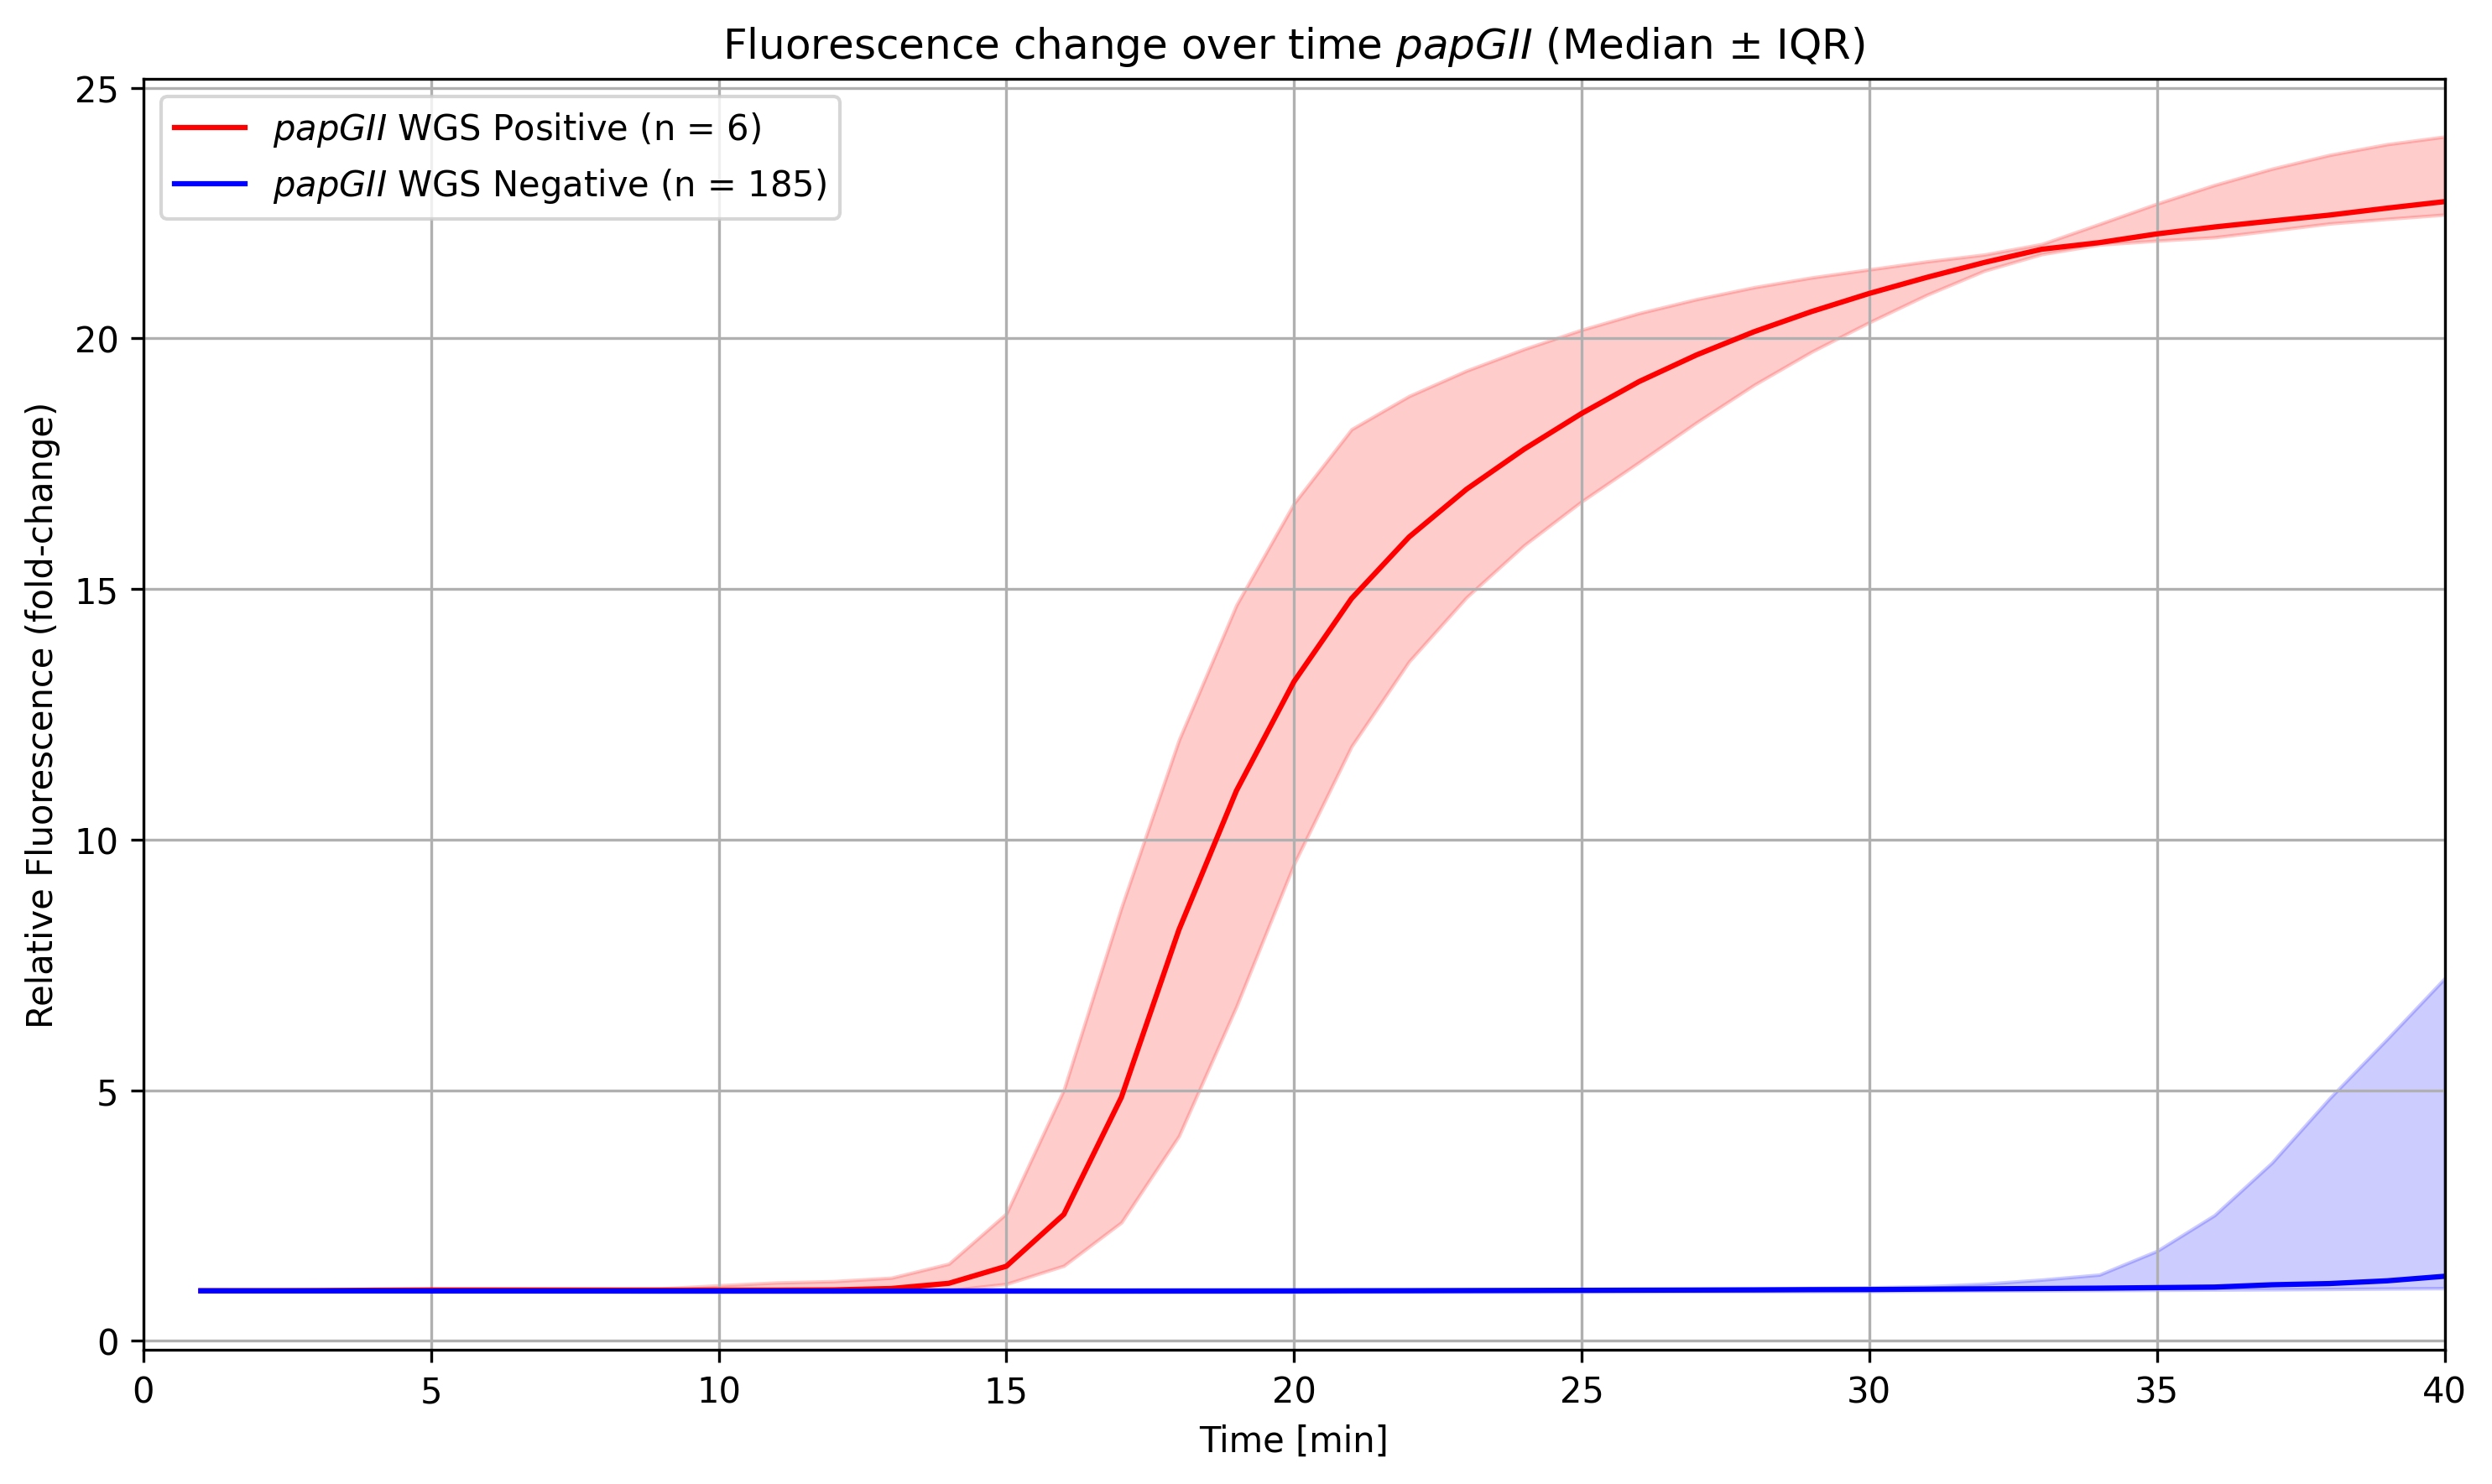

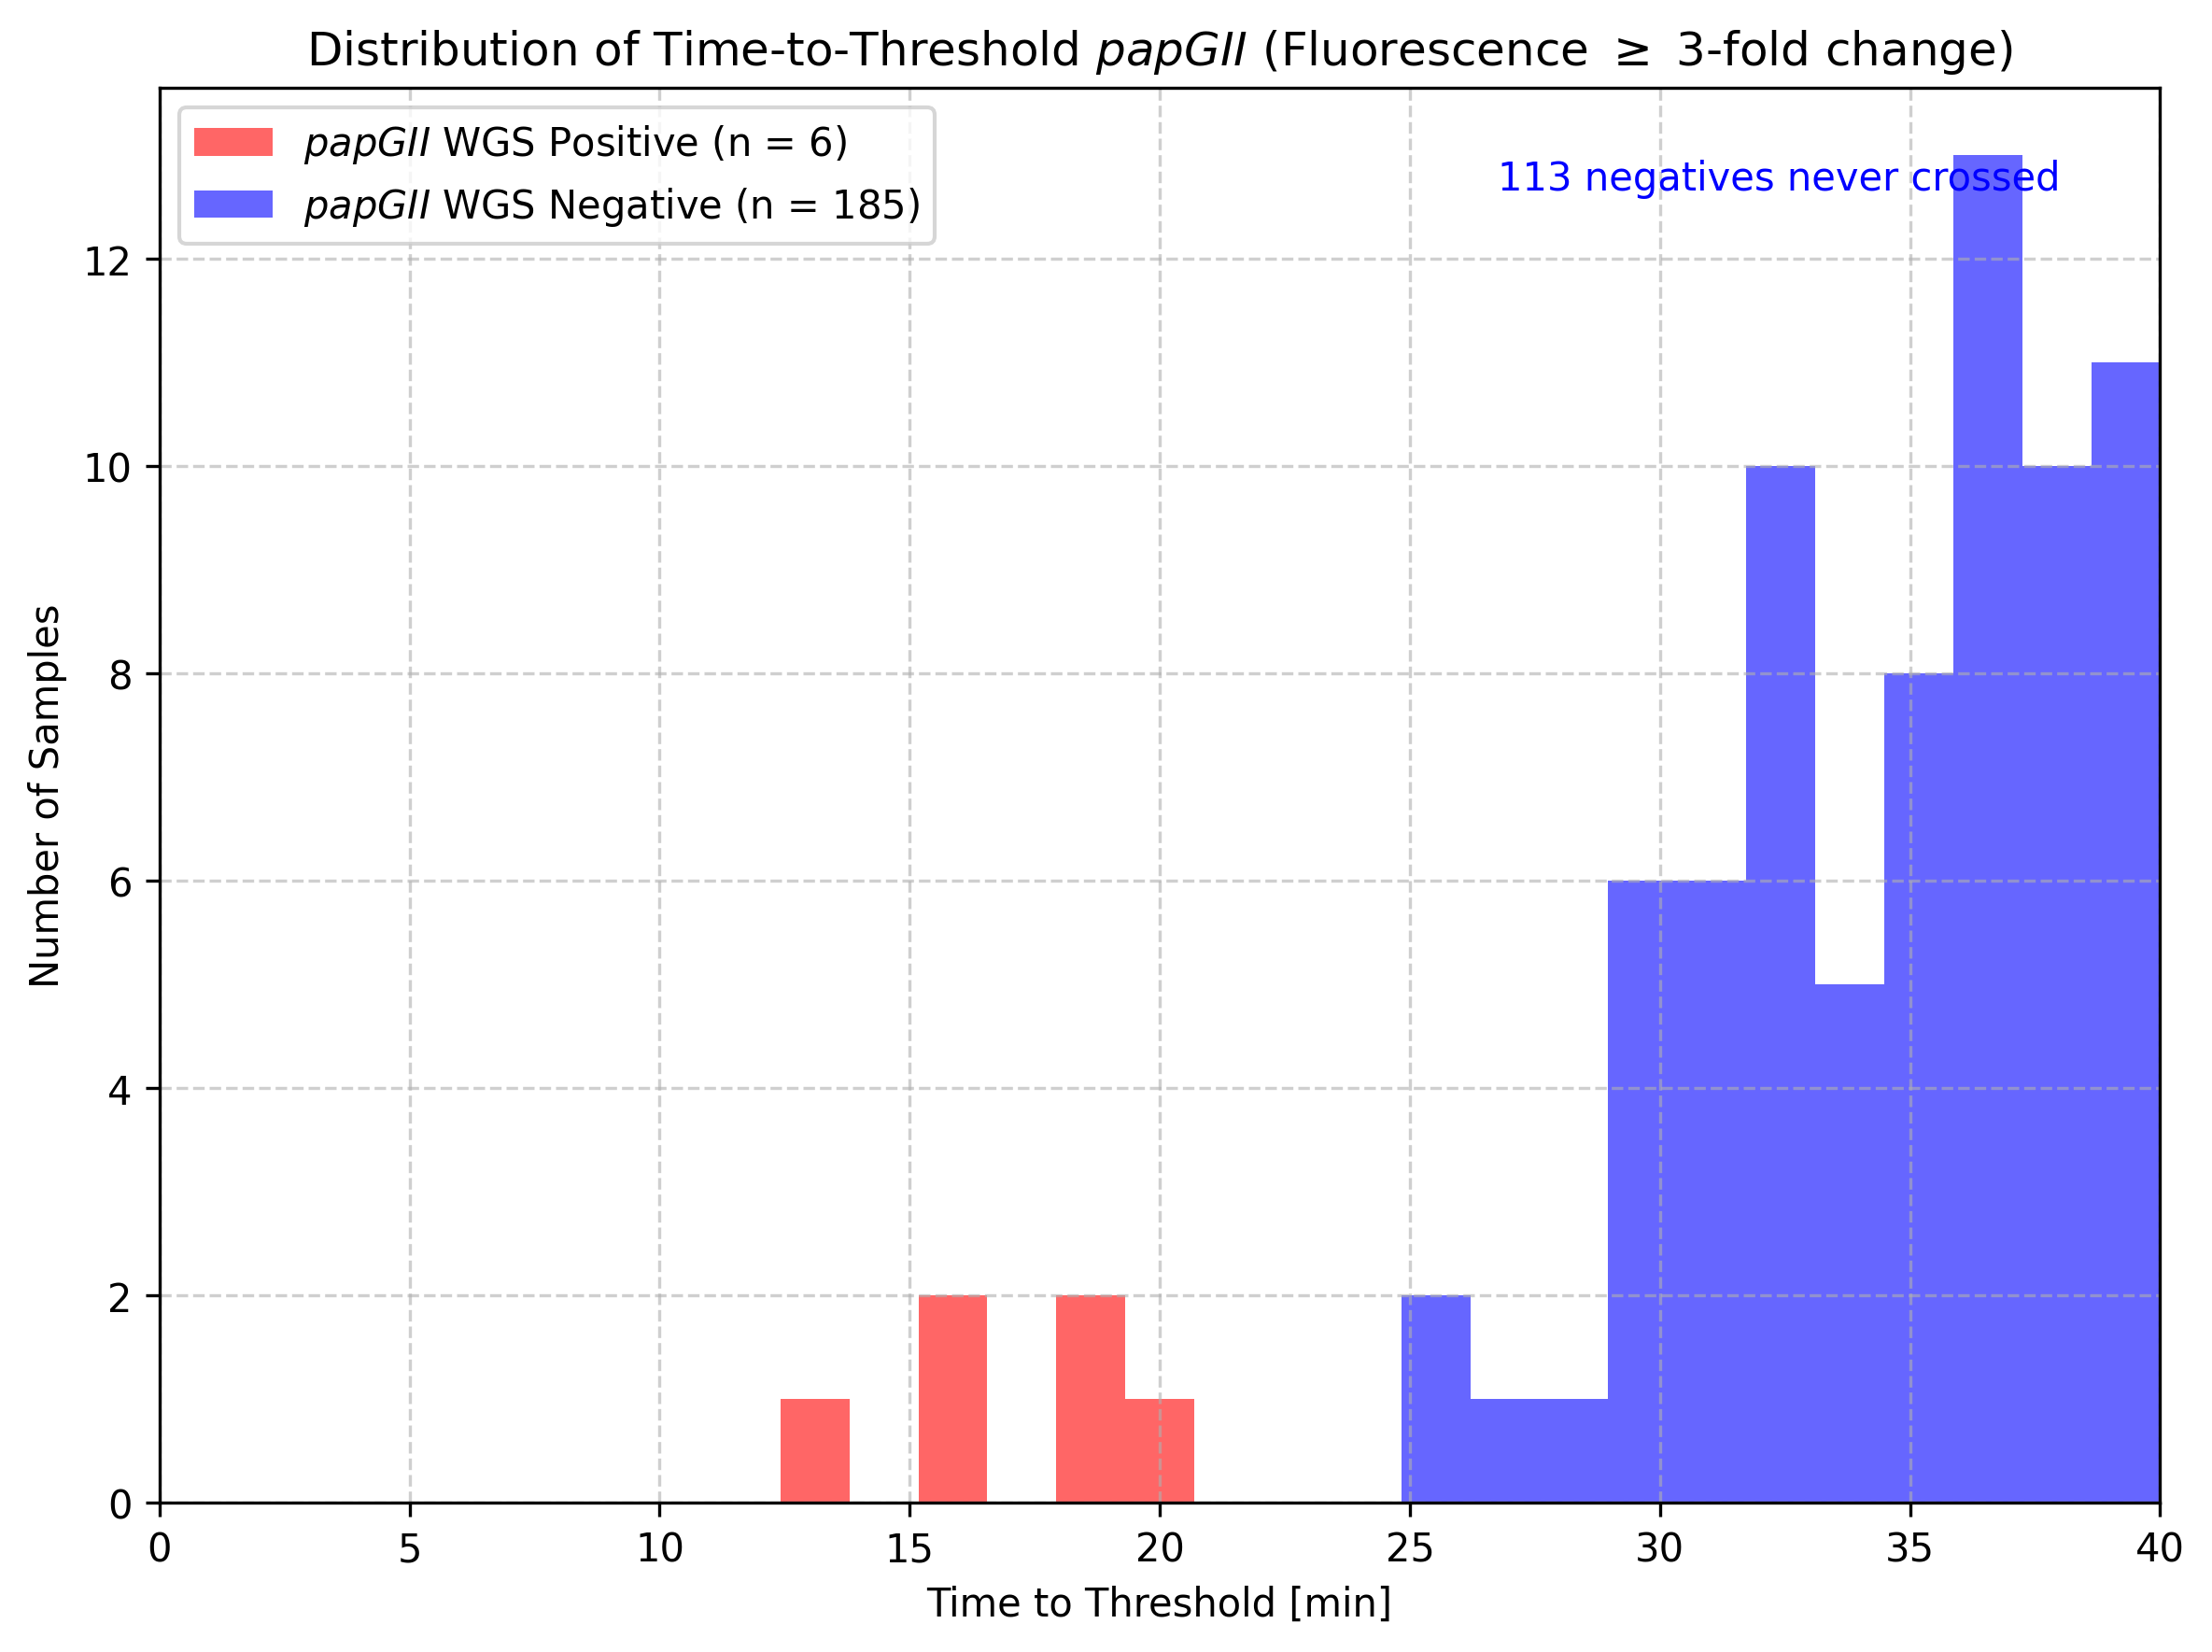

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------
# CONFIG
# -----------------------
cycle_time = 1.0  # minutes per cycle
cutoff_fluo = 3.0

# notebook is in repo/notebook/, data is in repo/data/
DATA_DIR = Path("../data")
raw_file = DATA_DIR / "all_measurements_papg.csv"
culture_file = DATA_DIR / "papg_results.csv"

# -----------------------
# Load data
# -----------------------
raw_fluo = pd.read_csv(raw_file)
culture = pd.read_csv(culture_file)

# Ensure sample IDs match
culture['sample'] = culture['sample'].astype(str).str.strip()
raw_fluo.columns = raw_fluo.columns.astype(str).str.strip()

# Melt into long format
raw_long = raw_fluo.melt(id_vars=["Cycle"], var_name="sample", value_name="fluorescence")

# -----------------------
# Normalize: convert to fold-change relative to cycle 1
# -----------------------
# get baseline per sample (fluorescence at Cycle = 1)
baseline = raw_long[raw_long["Cycle"] == 1][["sample", "fluorescence"]].rename(columns={"fluorescence": "baseline"})
raw_long = raw_long.merge(baseline, on="sample")
raw_long["fluorescence_norm"] = raw_long["fluorescence"] / raw_long["baseline"]

# Merge with culture results
raw_long = raw_long.merge(culture, on="sample")

# Convert cycles → time
raw_long["time_min"] = raw_long["Cycle"] * cycle_time

# -----------------------
# Mean ± SD plots
# -----------------------
grouped = raw_long.groupby(["culture_result", "time_min"])["fluorescence_norm"]
mean = grouped.mean().reset_index()
std = grouped.std().reset_index()

plt.figure(figsize=(10,6))
colors = {1: "red", 0: "blue"}
labels = {1: "$\\it{papGII}$ WGS Positive (n = 6)", 0: "$\\it{papGII}$ WGS Negative (n = 185)"}

for label in [1, 0]:
    m = mean[mean["culture_result"] == label]
    s = std[std["culture_result"] == label]

    plt.plot(m["time_min"], m["fluorescence_norm"], color=colors[label], label=labels[label])
    plt.fill_between(m["time_min"],
                     m["fluorescence_norm"] - s["fluorescence_norm"],
                     m["fluorescence_norm"] + s["fluorescence_norm"],
                     color=colors[label], alpha=0.2)

plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("Fluorescence change over time $\\it{papGII}$ (Mean ± SD)")
plt.legend()
plt.grid(True)
plt.xlim(0, 40)  # Limit x-axis to 40 minutes
plt.tight_layout()
plt.show()

# -----------------------
# Median ± IQR plots
# -----------------------
median = grouped.median().reset_index()
q25 = grouped.quantile(0.25).reset_index()
q75 = grouped.quantile(0.75).reset_index()

plt.figure(figsize=(10,6))

for label in [1, 0]:
    m = median[median["culture_result"] == label]
    q1 = q25[q25["culture_result"] == label]
    q3 = q75[q75["culture_result"] == label]

    plt.plot(m["time_min"], m["fluorescence_norm"], color=colors[label], label=labels[label])
    plt.fill_between(m["time_min"],
                     q1["fluorescence_norm"],
                     q3["fluorescence_norm"],
                     color=colors[label], alpha=0.2)

plt.xlabel("Time [min]")
plt.ylabel("Relative Fluorescence (fold-change)")
plt.title("Fluorescence change over time $\\it{papGII}$ (Median ± IQR)")
plt.legend()
plt.grid(True)
plt.xlim(0, 40)  # Limit x-axis to 40 minutes
plt.tight_layout()
plt.show()

# -----------------------
# Time-to-Threshold (Tt) Histogram
# -----------------------
def compute_Tt(df, cutoff):
    above = df[df["fluorescence_norm"] >= cutoff]
    if above.empty:
        return np.nan
    return above["time_min"].iloc[0]

tt_list = []
for sample, group in raw_long.groupby("sample"):
    tt = compute_Tt(group.sort_values("time_min"), cutoff_fluo)
    culture_result = group["culture_result"].iloc[0]
    tt_list.append((sample, culture_result, tt))

tt_df = pd.DataFrame(tt_list, columns=["sample", "culture_result", "time_to_threshold"])
tt_df = tt_df[tt_df["sample"] != "NTC"]   # the no-template control is not a sample

plt.figure(figsize=(8,6))
pos = tt_df[tt_df["culture_result"] == 1]["time_to_threshold"].dropna()
neg = tt_df[tt_df["culture_result"] == 0]["time_to_threshold"].dropna()

# Adjust x-axis bins to go from 0 to 40 minutes
bins = np.linspace(0, 40, 30)

plt.hist(pos, bins=bins, alpha=0.6, color="red", label="$\\it{papGII}$ WGS Positive (n = 6)")
plt.hist(neg, bins=bins, alpha=0.6, color="blue", label="$\\it{papGII}$ WGS Negative (n = 185)")

# Display number of negative samples that did not cross the threshold
num_uncrossed = tt_df[(tt_df["culture_result"] == 0) & (tt_df["time_to_threshold"].isna())].shape[0]
if num_uncrossed > 0:
    plt.text(0.5, 0.95, f"{num_uncrossed} negatives did not cross\nthe threshold within 40 min",
             ha="center", va="top", transform=plt.gca().transAxes, fontsize=10, color="blue")

# Set x-axis and y-axis labels
plt.xlabel("Time to Threshold [min]")
plt.ylabel("Number of Samples")

# Set the title
plt.title("Distribution of Time-to-Threshold $\\it{papGII}$ (Fluorescence $\geq$ 3-fold change)")

# Add grid, legend, and tight layout
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)

# Set the x-axis to go from 0 to 40 minutes
plt.xlim(0, 40)

# Apply tight layout for better spacing
plt.tight_layout()
plt.show()


### *uidA* diagnostic performance: Youden index optimization, ROC/AUC, and fixed-threshold metrics

This cell quantifies diagnostic performance of the *uidA* LAMP assay relative to culture using **cycle/time cutoffs** and **fluorescence (fold-change) thresholds**.

#### Input files
- Raw fluorescence matrix (wide format): `../data/all_measurements_uida.csv`  
  - `Cycle` column plus one column per sample (sample IDs must match the reference file)
- Culture reference labels: `../data/culture_results.csv`  
  - required columns: `sample`, `culture_result` (`1` = culture positive, `0` = culture negative)

#### Preprocessing
1. **Wide → long reshape**  
   The fluorescence matrix is melted to long format with columns: `Cycle`, `sample`, `fluorescence`.

2. **Fold-change normalization (within code)**  
   For each sample, raw fluorescence is normalized to fold-change relative to Cycle 1:
   \[
   \text{fold-change}_{i,c} = \frac{F_{i,c}}{F_{i,1}}
   \]
   After normalization, the fold-change values replace the `fluorescence` column and are used throughout the analysis.

3. **Merge with reference labels**  
   Normalized fluorescence is merged with `culture_results.csv` on `sample`.

---

## Classification rule

For a given cycle cutoff \(C\) and fluorescence threshold \(\tau\) (fold-change), each sample is summarized by:
\[
S_i(C) = \max_{c \le C}(\text{fold-change}_{i,c})
\]

Prediction:
- **positive** if \(S_i(C) \ge \tau\)
- **negative** otherwise

---

## Metrics computed (per \((C,\tau)\) pair)

From TP, TN, FP, FN counts, the following are calculated:
- Sensitivity (recall): \( \frac{TP}{TP + FN} \)
- Specificity: \( \frac{TN}{TN + FP} \)
- Precision: \( \frac{TP}{TP + FP} \)
- Accuracy: \( \frac{TP + TN}{TP + TN + FP + FN} \)
- F1-score: \( \frac{2TP}{2TP + FP + FN} \)
- **Youden index**: \( \text{Sensitivity} + \text{Specificity} - 1 \)

All metrics are computed using `metrics_fixed()`.

---

## Analyses performed

### 1) Cycle/time sweep at fixed fluorescence threshold
- Fixed fluorescence threshold: `fixed_fluo = 3.0` fold-change
- Cycles are swept across all available values in the dataset.
- A results table (`results_time_df`) is generated containing Youden index and other metrics versus time:
  - `time_min = Cycle × cycle_time` with `cycle_time = 1.0 min`

**Output plot:** Metrics vs time (Youden, sensitivity, specificity, precision).  
The optimal timepoint is identified as the time with maximum Youden index (`best_time`) and marked on the plot.

### 2) ROC curve and AUC at the optimal time
At `best_time`, each sample is scored using the maximum fold-change up to that timepoint and used as a continuous decision score for ROC analysis.
- ROC curve computed with `sklearn.metrics.roc_curve`
- AUC computed with `sklearn.metrics.auc`

**Output plot:** ROC curve annotated with AUC; the point corresponding to \(\tau = 3.0\) at `best_time` is highlighted.

### 3) Fluorescence threshold sweep at a fixed cycle
- Fixed cycle for sweep: `fixed_cycle = 30`
- Fluorescence thresholds are swept across the observed range of fold-change values (200 evenly spaced values).
- A results table (`results_fluo_df`) is generated containing Youden index and other metrics versus threshold.

**Output plot:** Metrics vs fluorescence threshold (Youden, sensitivity, specificity, precision).  
The fixed threshold \(\tau = 3.0\) is indicated.

### 4) Threshold range that maximizes Youden at fixed cycle
At `fixed_cycle = 30`, the maximum Youden index is identified and the range of fluorescence thresholds achieving that maximum is reported:
- `fluo_min`–`fluo_max`

### 5) Grid search over cycles and thresholds
A complete grid of \((\text{cycle}, \text{fluorescence threshold})\) combinations is evaluated and stored in `results_df`. This enables querying optimal thresholds at any cycle.

As an example, the notebook reports the fluorescence threshold range yielding maximum Youden at:
- `cycle = 39` (`fluo_min_39`–`fluo_max_39`)

### 6) Fixed-threshold performance at cycles 30 and 39
Finally, diagnostic performance is reported at a fixed threshold:
- \(\tau = 3.0\) fold-change
- cycles: 30 and 39

For each cycle, the cell prints Youden index, sensitivity, specificity, precision, accuracy, F1-score, and TP/TN/FP/FN.

---
**Key fixed parameters in this cell**
- `cycle_time = 1.0` min per cycle
- `fixed_fluo = 3.0` fold-change
- fluorescence sweep evaluated at `fixed_cycle = 30`
- fixed-threshold performance reported at cycles `30` and `39`


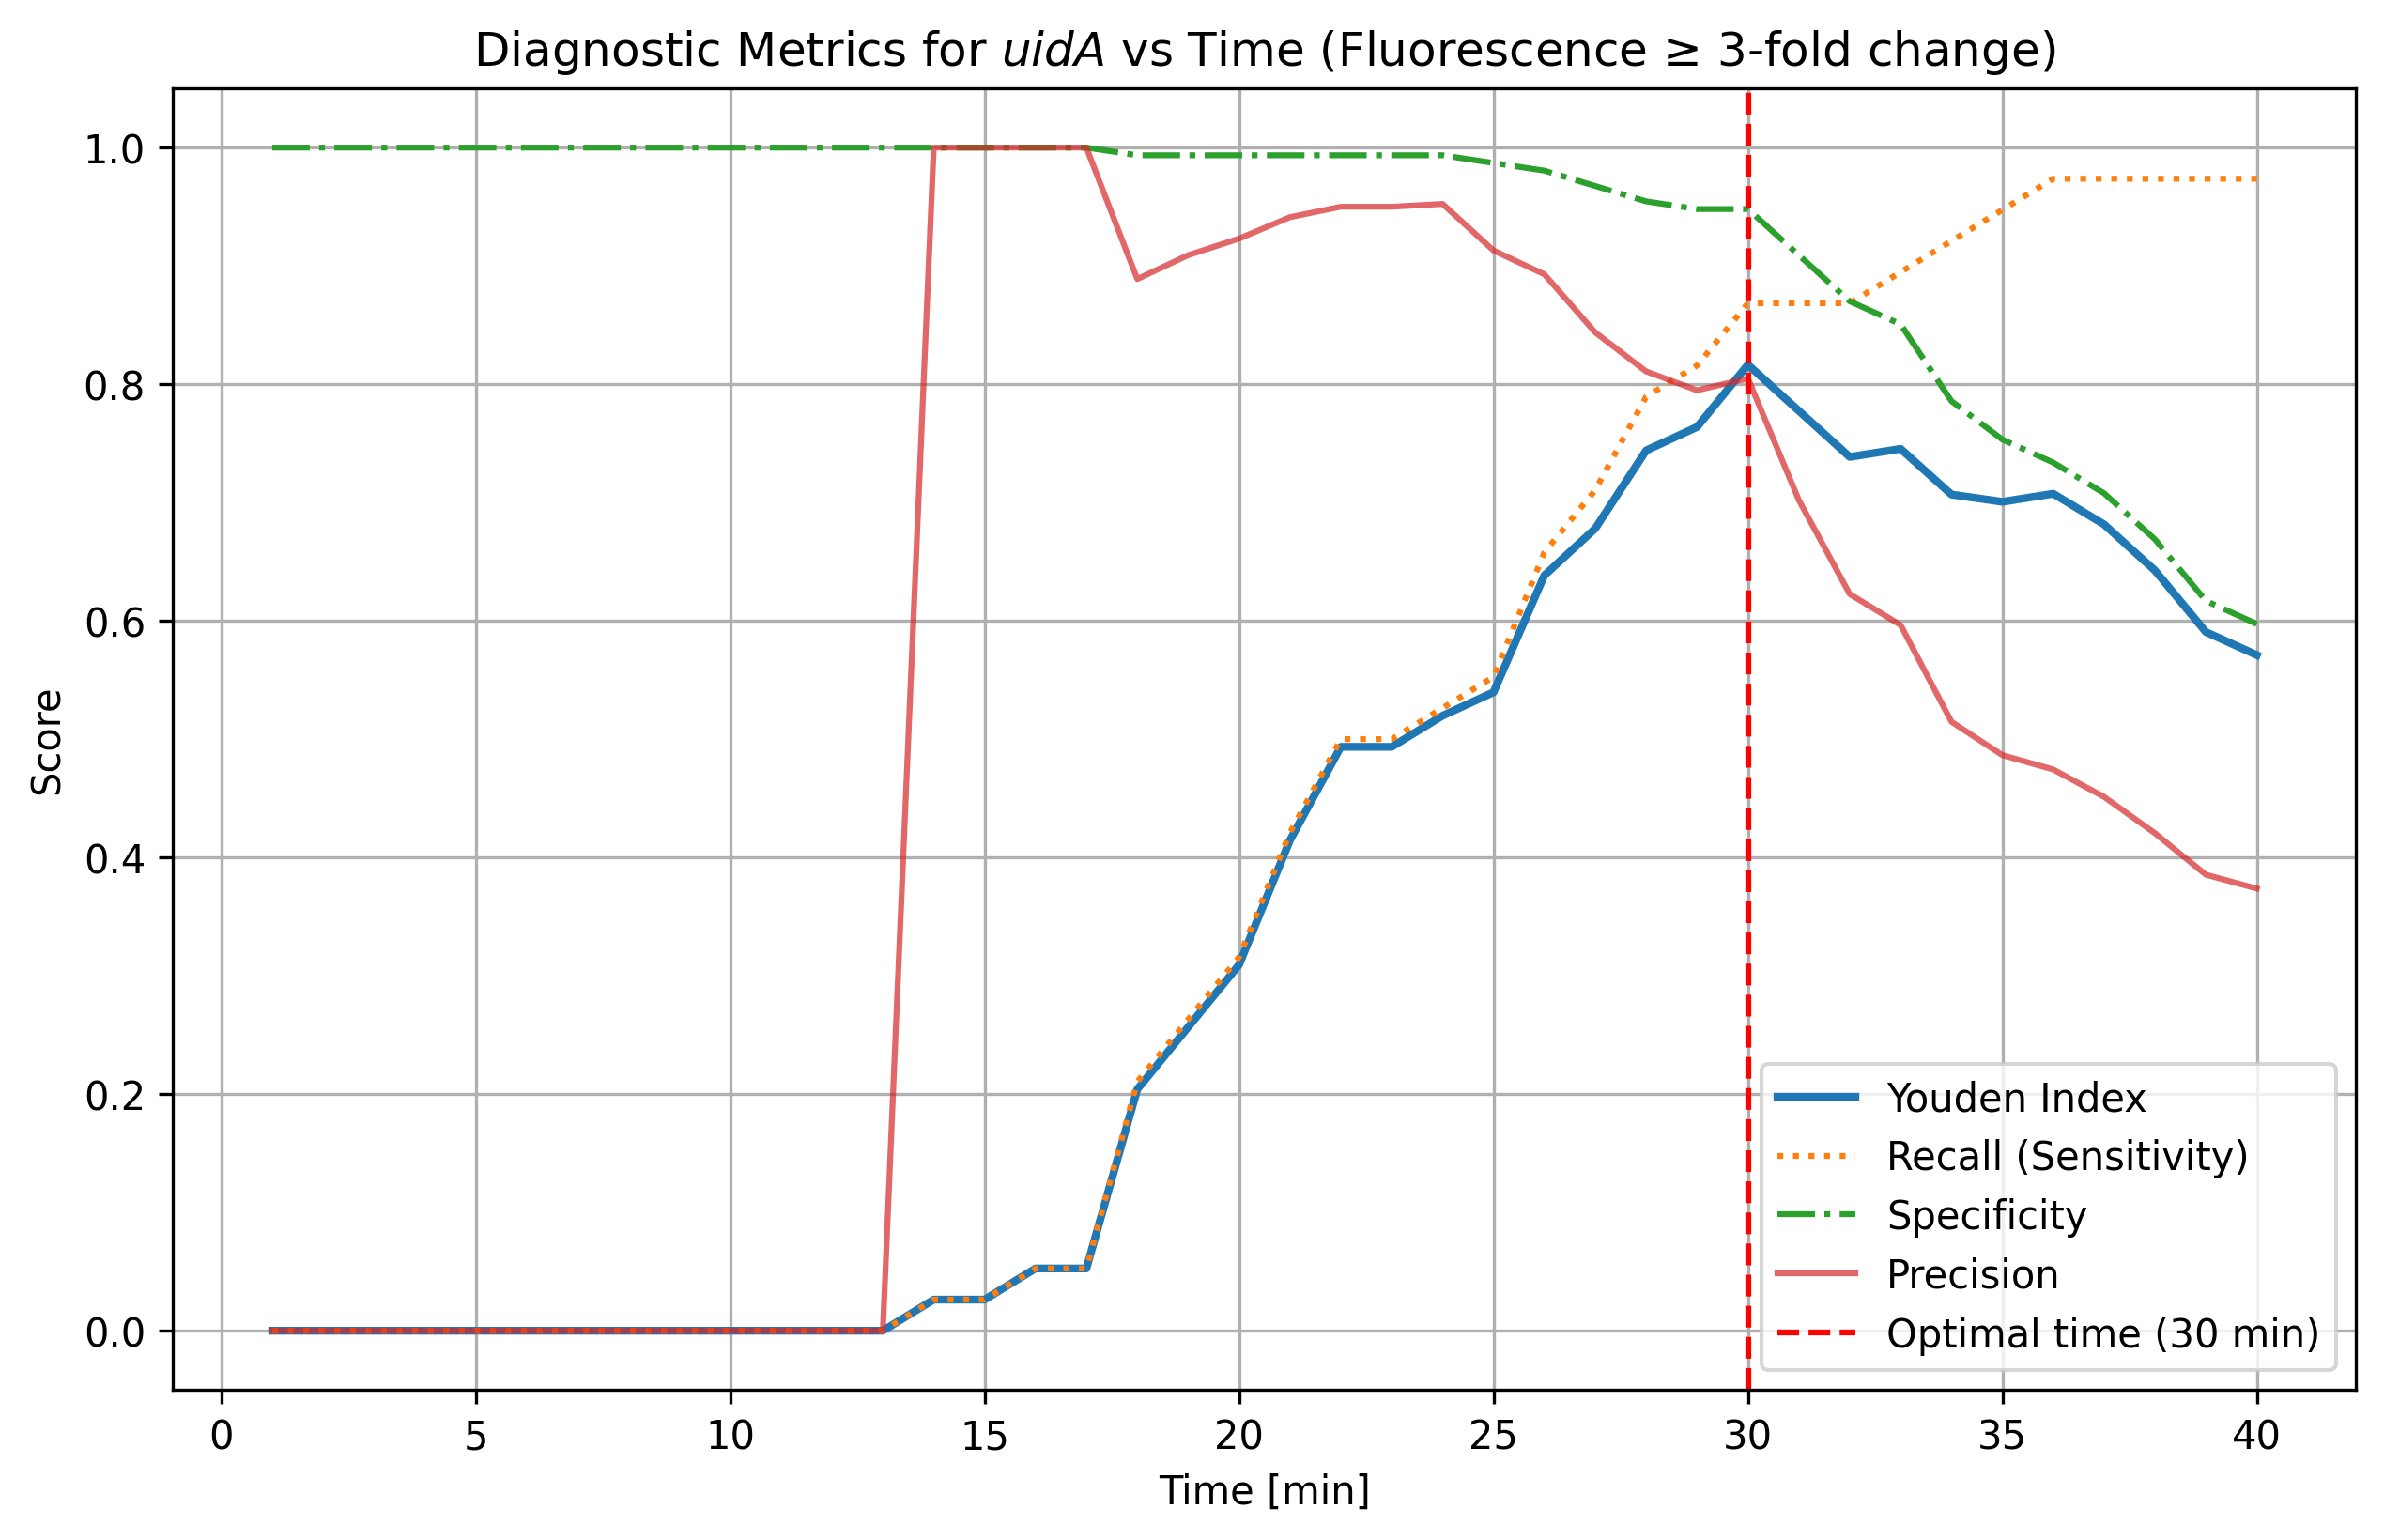

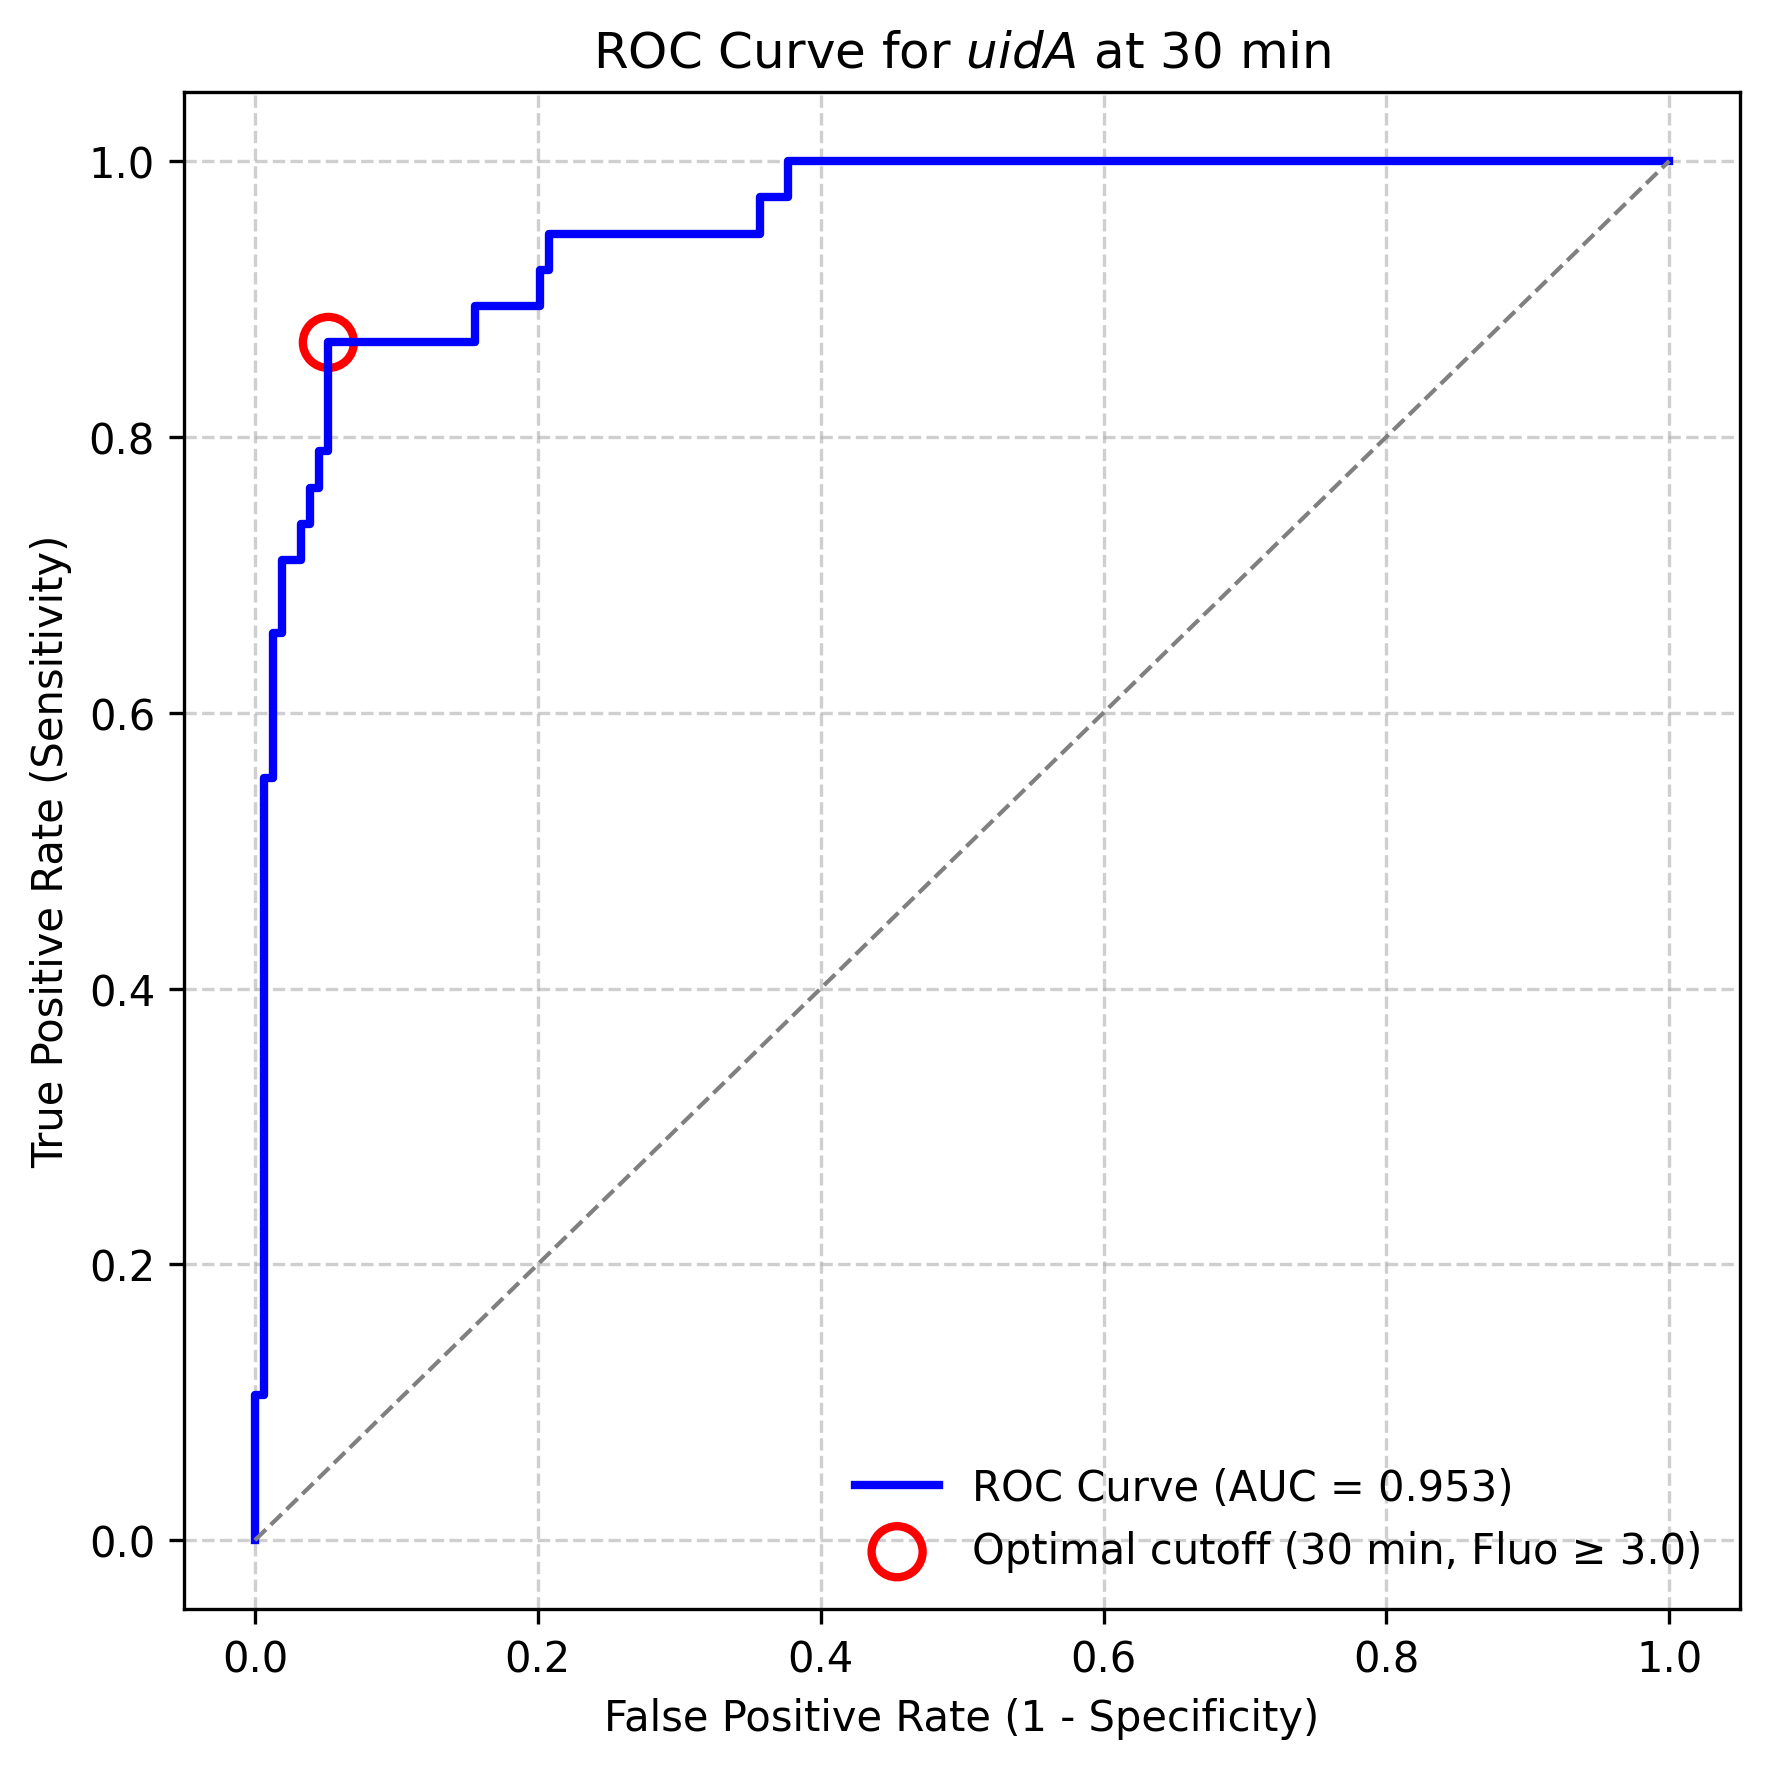

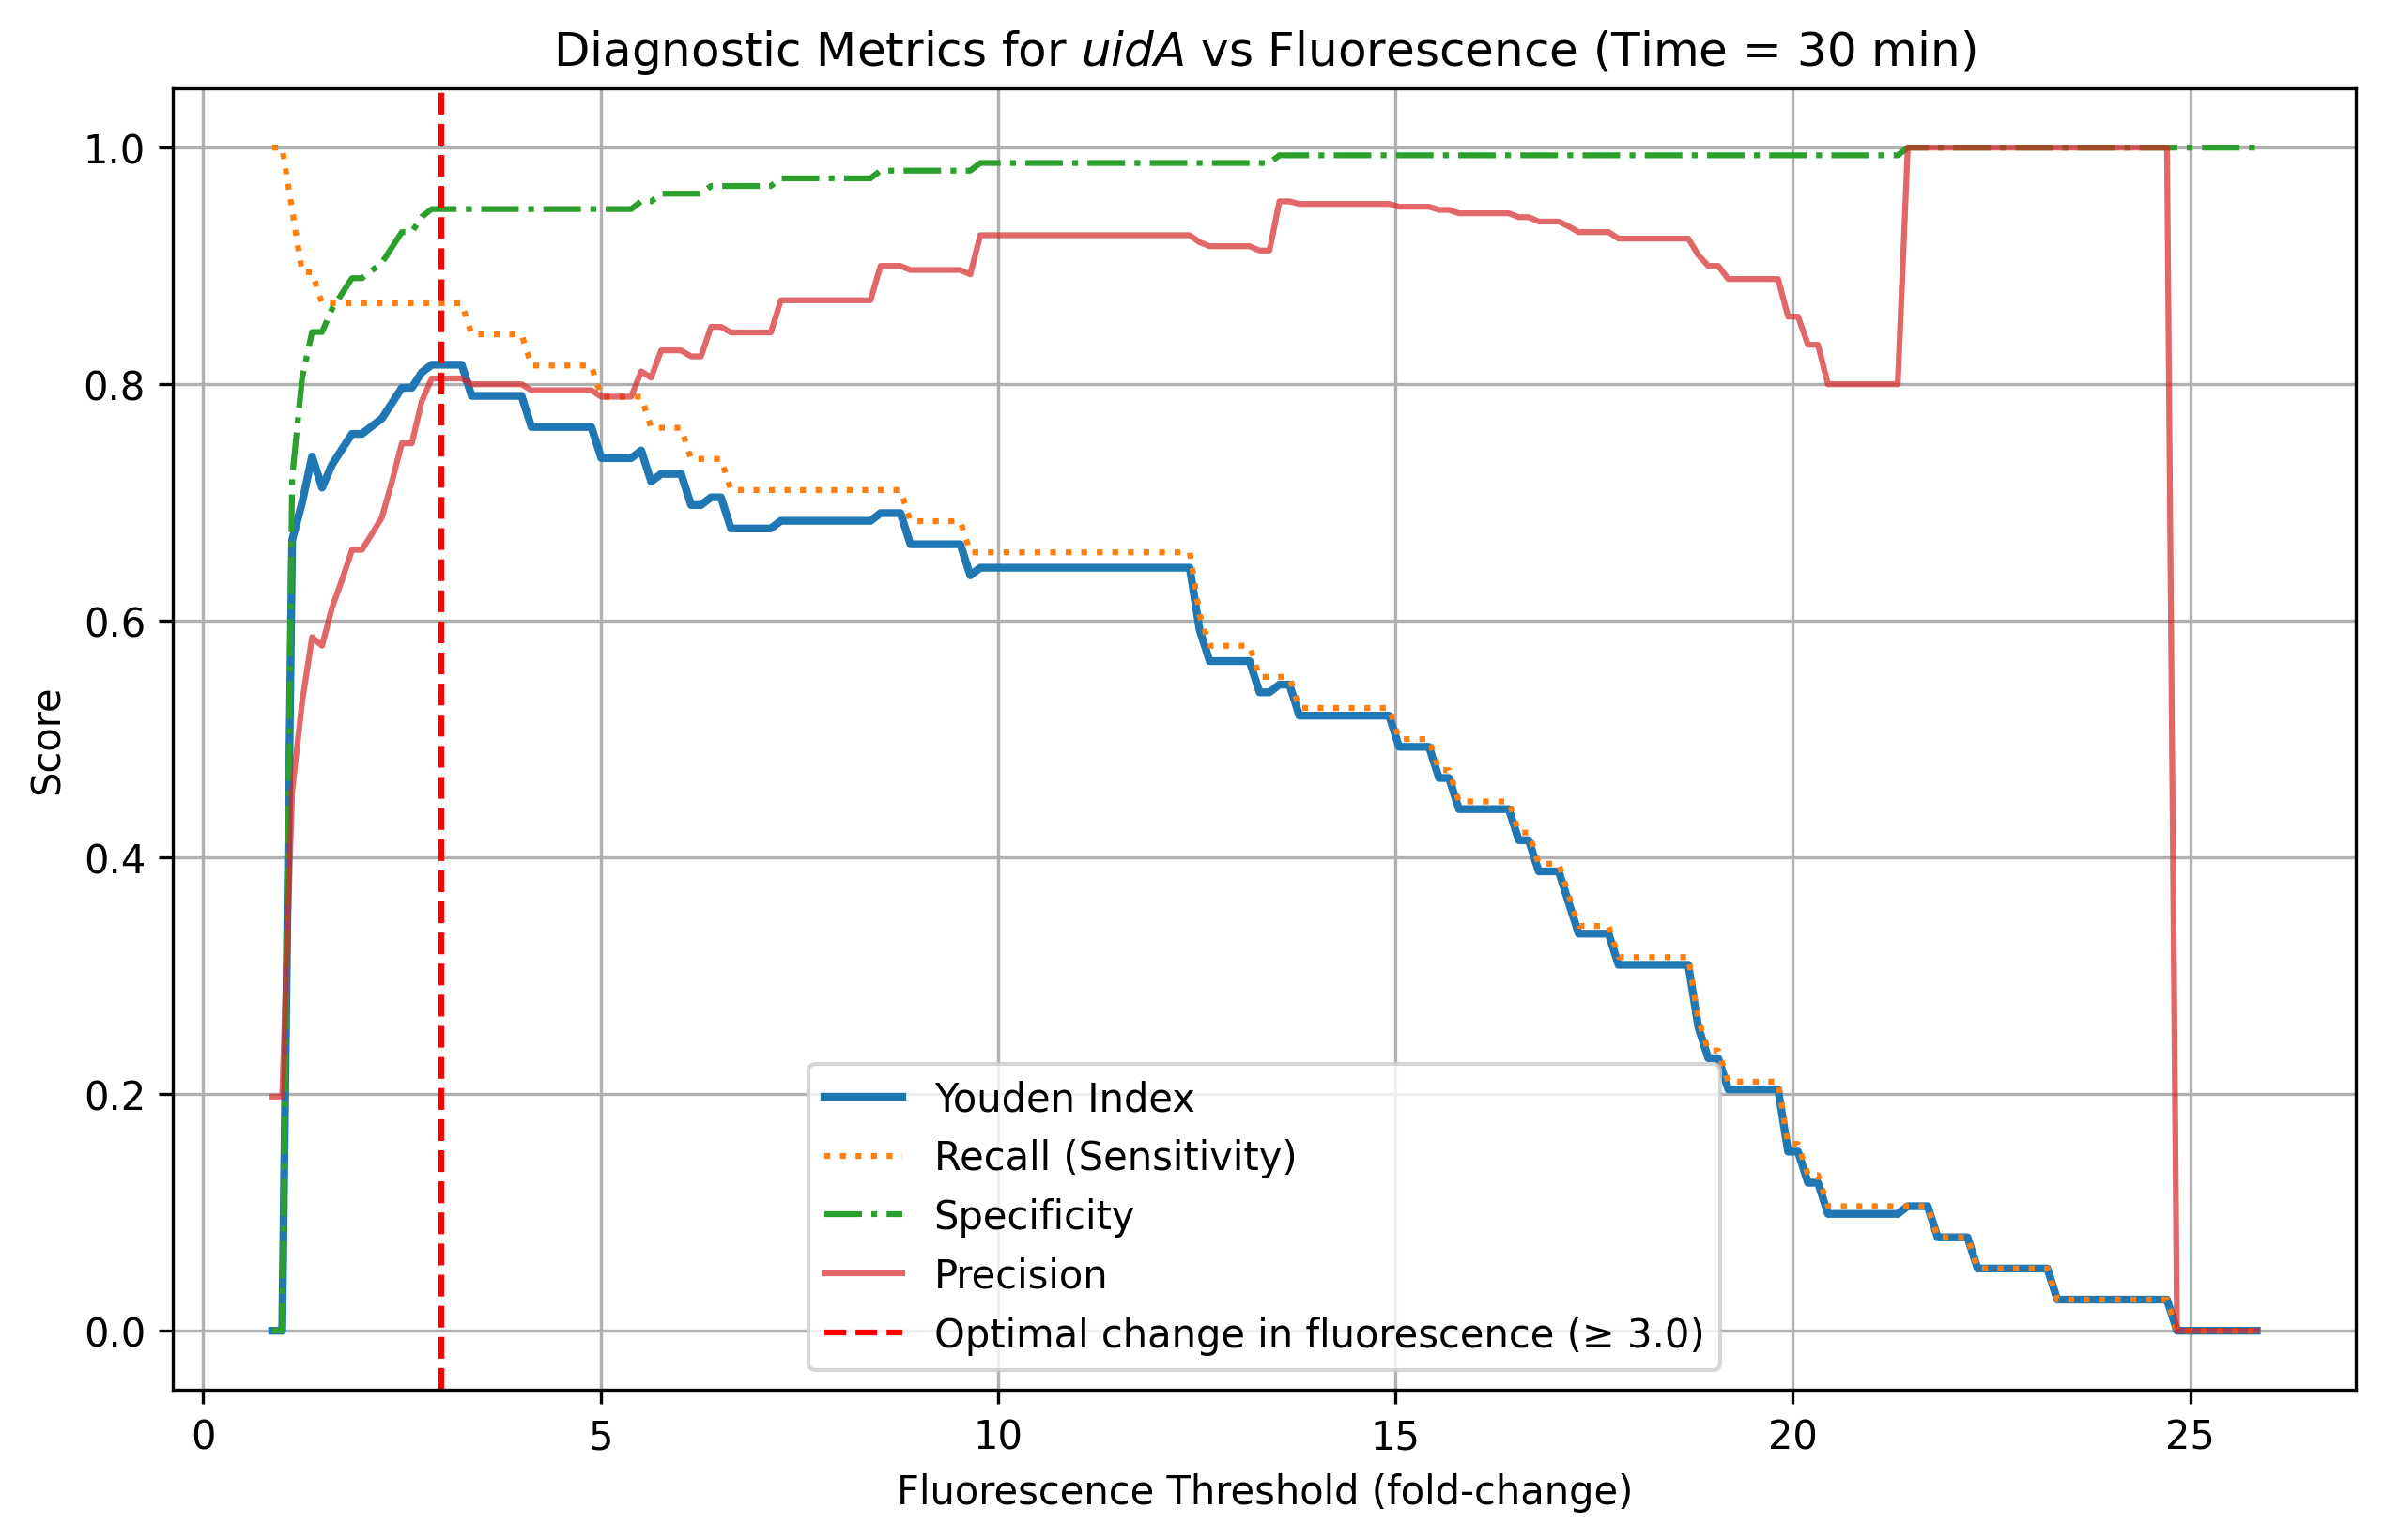

At cycle 30, Youden max = 0.816
Fluorescence thresholds yielding this max Youden: 2.877 – 3.253

At cycle 39, Youden max = 0.817
Fluorescence thresholds yielding this max Youden: 11.408 – 11.408

Metrics at cycle = 30, fluorescence = 3.0
Youden Index     = 0.816
Sensitivity      = 0.868
Specificity      = 0.948
Precision        = 0.805
Accuracy         = 0.932
F1-score         = 0.835
TP=33, TN=146, FP=8, FN=5

Metrics at cycle = 39, fluorescence = 3.0
Youden Index     = 0.591
Sensitivity      = 0.974
Specificity      = 0.617
Precision        = 0.385
Accuracy         = 0.688
F1-score         = 0.552
TP=37, TN=95, FP=59, FN=1


In [6]:
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_curve, auc
from pathlib import Path

# set global DPI for all figures
mpl.rcParams['figure.dpi'] = 300

# -----------------------
# Load the data
# -----------------------
DATA_DIR = Path("../data")

# RAW input (was youden_uida_2.csv before)
fluorescence = pd.read_csv(DATA_DIR / "all_measurements_uida.csv")
culture = pd.read_csv(DATA_DIR / "culture_results.csv")

# Ensure sample names match
culture['sample'] = culture['sample'].astype(str).str.strip()
fluorescence.columns = fluorescence.columns.astype(str).str.strip()

# Reshape fluorescence data to long format
fluorescence_long = fluorescence.melt(
    id_vars=["Cycle"],
    var_name="sample",
    value_name="fluorescence"
)

# Normalize within code (fold-change relative to Cycle = 1)
baseline = (
    fluorescence_long[fluorescence_long["Cycle"] == 1][["sample", "fluorescence"]]
    .rename(columns={"fluorescence": "baseline"})
)
fluorescence_long = fluorescence_long.merge(baseline, on="sample", how="left")
fluorescence_long["fluorescence"] = fluorescence_long["fluorescence"] / fluorescence_long["baseline"]

# Merge with culture results
data = fluorescence_long.merge(culture, on="sample")

# -----------------------
# CONFIG
# -----------------------
cycle_time = 1.0   # minutes per cycle
fixed_fluo = 3.0
fixed_cycle = 30   # for fluorescence sweep

# -----------------------
# Helper: compute metrics
# -----------------------
def metrics_fixed(df, cycle_thresh, fluo_thresh):
    subset = df[df["Cycle"] <= cycle_thresh]
    agg = subset.groupby("sample")["fluorescence"].max().reset_index()
    agg = agg.merge(culture, on="sample")

    agg["pred"] = (agg["fluorescence"] >= fluo_thresh).astype(int)

    tp = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 1))
    tn = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 0))
    fp = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 1))
    fn = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 0))

    sensitivity = tp / (tp + fn) if (tp+fn) > 0 else 0.0   # recall
    specificity = tn / (tn + fp) if (tn+fp) > 0 else 0.0
    precision   = tp / (tp + fp) if (tp+fp) > 0 else 0.0
    accuracy    = (tp + tn) / (tp + tn + fp + fn) if (tp+tn+fp+fn) > 0 else 0.0
    f1          = (2 * tp) / (2 * tp + fp + fn) if (2*tp + fp + fn) > 0 else 0.0
    youden      = sensitivity + specificity - 1

    return youden, sensitivity, specificity, precision, accuracy, f1, tp, tn, fp, fn

# -----------------------
# Sweep cycles at fixed fluorescence
# -----------------------
cycles = np.sort(fluorescence["Cycle"].unique())
results_time = []

for cyc in cycles:
    y, sens, spec, prec, acc, f1, tp, tn, fp, fn = metrics_fixed(data, cyc, fixed_fluo)
    results_time.append((cyc*cycle_time, y, sens, spec, prec, acc, f1, tp, tn, fp, fn))

results_time_df = pd.DataFrame(
    results_time,
    columns=["time_min", "youden", "sensitivity", "specificity", "precision", "accuracy", "f1_score", "TP", "TN", "FP", "FN"]
)

# Best by Youden
best_time = results_time_df.sort_values("youden", ascending=False).iloc[0]["time_min"]

# -----------------------
# Plot metrics vs time (Precision instead of Balanced Accuracy)
# -----------------------
plt.figure(figsize=(10,6))
plt.plot(results_time_df["time_min"], results_time_df["youden"], label="Youden Index", linewidth=2)
plt.plot(results_time_df["time_min"], results_time_df["sensitivity"], label="Recall (Sensitivity)", linestyle=":")
plt.plot(results_time_df["time_min"], results_time_df["specificity"], label="Specificity", linestyle="-.")
plt.plot(results_time_df["time_min"], results_time_df["precision"], label="Precision", linestyle="-", alpha=0.7)

plt.axvline(best_time, color="red", linestyle="--", label=f"Optimal time ({best_time:.0f} min)")

plt.xlabel("Time [min]")
plt.ylabel("Score")
plt.title("Diagnostic Metrics for $\\it{uidA}$ vs Time (Fluorescence ≥ 3-fold change)")
plt.legend()
plt.grid(True)
plt.show()

# -----------------------
# ROC curve + AUC at best time
# -----------------------
subset = data[data["Cycle"] <= best_time/cycle_time]
agg = subset.groupby("sample")["fluorescence"].max().reset_index()
agg = agg.merge(culture, on="sample")

y_true = agg["culture_result"].values
y_score = agg["fluorescence"].values

fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color="blue", lw=2, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", color="gray", lw=1)

# mark cutoff point at fixed fluorescence = 3.0
row_best = results_time_df.loc[results_time_df["time_min"] == best_time].iloc[0]
fpr_fixed = 1 - row_best["specificity"]
tpr_fixed = row_best["sensitivity"]
plt.scatter(fpr_fixed, tpr_fixed, s=150, facecolors='none', edgecolors='red', linewidths=2,
            label=f"Optimal cutoff ({best_time:.0f} min, Fluo ≥ {fixed_fluo})")

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve for $\\it{uidA}$ at 30 min")
plt.legend(frameon=False)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# -----------------------
# Sweep fluorescence at fixed cycle
# -----------------------
fluos = np.linspace(
    fluorescence_long["fluorescence"].min(),
    fluorescence_long["fluorescence"].max(),
    200
)

results_fluo = []
for fluo in fluos:
    y, sens, spec, prec, acc, f1, tp, tn, fp, fn = metrics_fixed(data, fixed_cycle, fluo)
    results_fluo.append((fluo, y, sens, spec, prec, acc, f1, tp, tn, fp, fn))

results_fluo_df = pd.DataFrame(
    results_fluo,
    columns=["fluorescence_thresh", "youden", "sensitivity", "specificity", "precision", "accuracy", "f1_score", "TP", "TN", "FP", "FN"]
)

# Best by Youden at fixed cycle
best_fluo = results_fluo_df.sort_values("youden", ascending=False).iloc[0]["fluorescence_thresh"]

# -----------------------
# Plot metrics vs fluorescence (Precision instead of Balanced Accuracy)
# -----------------------
plt.figure(figsize=(10,6))
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["youden"], label="Youden Index", linewidth=2)
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["sensitivity"], label="Recall (Sensitivity)", linestyle=":")
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["specificity"], label="Specificity", linestyle="-.")
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["precision"], label="Precision", linestyle="-", alpha=0.7)

plt.axvline(fixed_fluo, color="red", linestyle="--", label="Optimal change in fluorescence (≥ 3.0)")

plt.xlabel("Fluorescence Threshold (fold-change)")
plt.ylabel("Score")
plt.title("Diagnostic Metrics for $\\it{uidA}$ vs Fluorescence (Time = 30 min)")
plt.legend()
plt.grid(True)
plt.show()

# -----------------------
# Find fluorescence range at fixed cycle = 30 that yields max Youden
# -----------------------
max_youden = results_fluo_df["youden"].max()
subset_max = results_fluo_df[results_fluo_df["youden"] == max_youden]

fluo_min = subset_max["fluorescence_thresh"].min()
fluo_max = subset_max["fluorescence_thresh"].max()

print(f"At cycle {fixed_cycle}, Youden max = {max_youden:.3f}")
print(f"Fluorescence thresholds yielding this max Youden: {fluo_min:.3f} – {fluo_max:.3f}")

# -----------------------
# Build results_df (cycle × fluorescence threshold grid)
# -----------------------
results = []
for cyc in cycles:
    for fluo in fluos:
        y, sens, spec, prec, acc, f1, tp, tn, fp, fn = metrics_fixed(data, cyc, fluo)
        results.append((cyc, fluo, y, sens, spec, prec, acc, f1, tp, tn, fp, fn))

results_df = pd.DataFrame(
    results,
    columns=[
        "cycle", "fluorescence_thresh", "youden",
        "sensitivity", "specificity", "precision", "accuracy", "f1_score",
        "TP", "TN", "FP", "FN"
    ]
)

# -----------------------
# Fluorescence range at cycle = 39
# -----------------------
fixed_cycle = 39
subset_39 = results_df[results_df["cycle"] == fixed_cycle]
max_youden_39 = subset_39["youden"].max()
fluo_min_39 = subset_39.loc[subset_39["youden"] == max_youden_39, "fluorescence_thresh"].min()
fluo_max_39 = subset_39.loc[subset_39["youden"] == max_youden_39, "fluorescence_thresh"].max()

print(f"\nAt cycle {fixed_cycle}, Youden max = {max_youden_39:.3f}")
print(f"Fluorescence thresholds yielding this max Youden: {fluo_min_39:.3f} – {fluo_max_39:.3f}")

# -----------------------
# Metrics at cycle 30 and 39, fluorescence = 3.0
# -----------------------
fluo_3 = 3.0

for cyc in [30, 39]:
    y, sens, spec, prec, acc, f1, tp, tn, fp, fn = metrics_fixed(data, cyc, fluo_3)

    print(f"\nMetrics at cycle = {cyc}, fluorescence = {fluo_3:.1f}")
    print(f"Youden Index     = {y:.3f}")
    print(f"Sensitivity      = {sens:.3f}")
    print(f"Specificity      = {spec:.3f}")
    print(f"Precision        = {prec:.3f}")
    print(f"Accuracy         = {acc:.3f}")
    print(f"F1-score         = {f1:.3f}")
    print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}")


### Corresponding analysis for *papGII* diagnostic performance: Youden index optimization, ROC/AUC, and fixed-threshold metrics

This cell quantifies diagnostic performance of the *uidA* LAMP assay relative to culture using **cycle/time cutoffs** and **fluorescence (fold-change) thresholds**.

#### Input files
- Raw fluorescence matrix (wide format): `../data/all_measurements_papg.csv`  
  - `Cycle` column plus one column per sample (sample IDs must match the reference file)
- Culture reference labels: `../data/papg_results.csv`  
  - required columns: `sample`, `papg_result` (`1` = papGII WGS positive, `0` = papGII WGS negative)


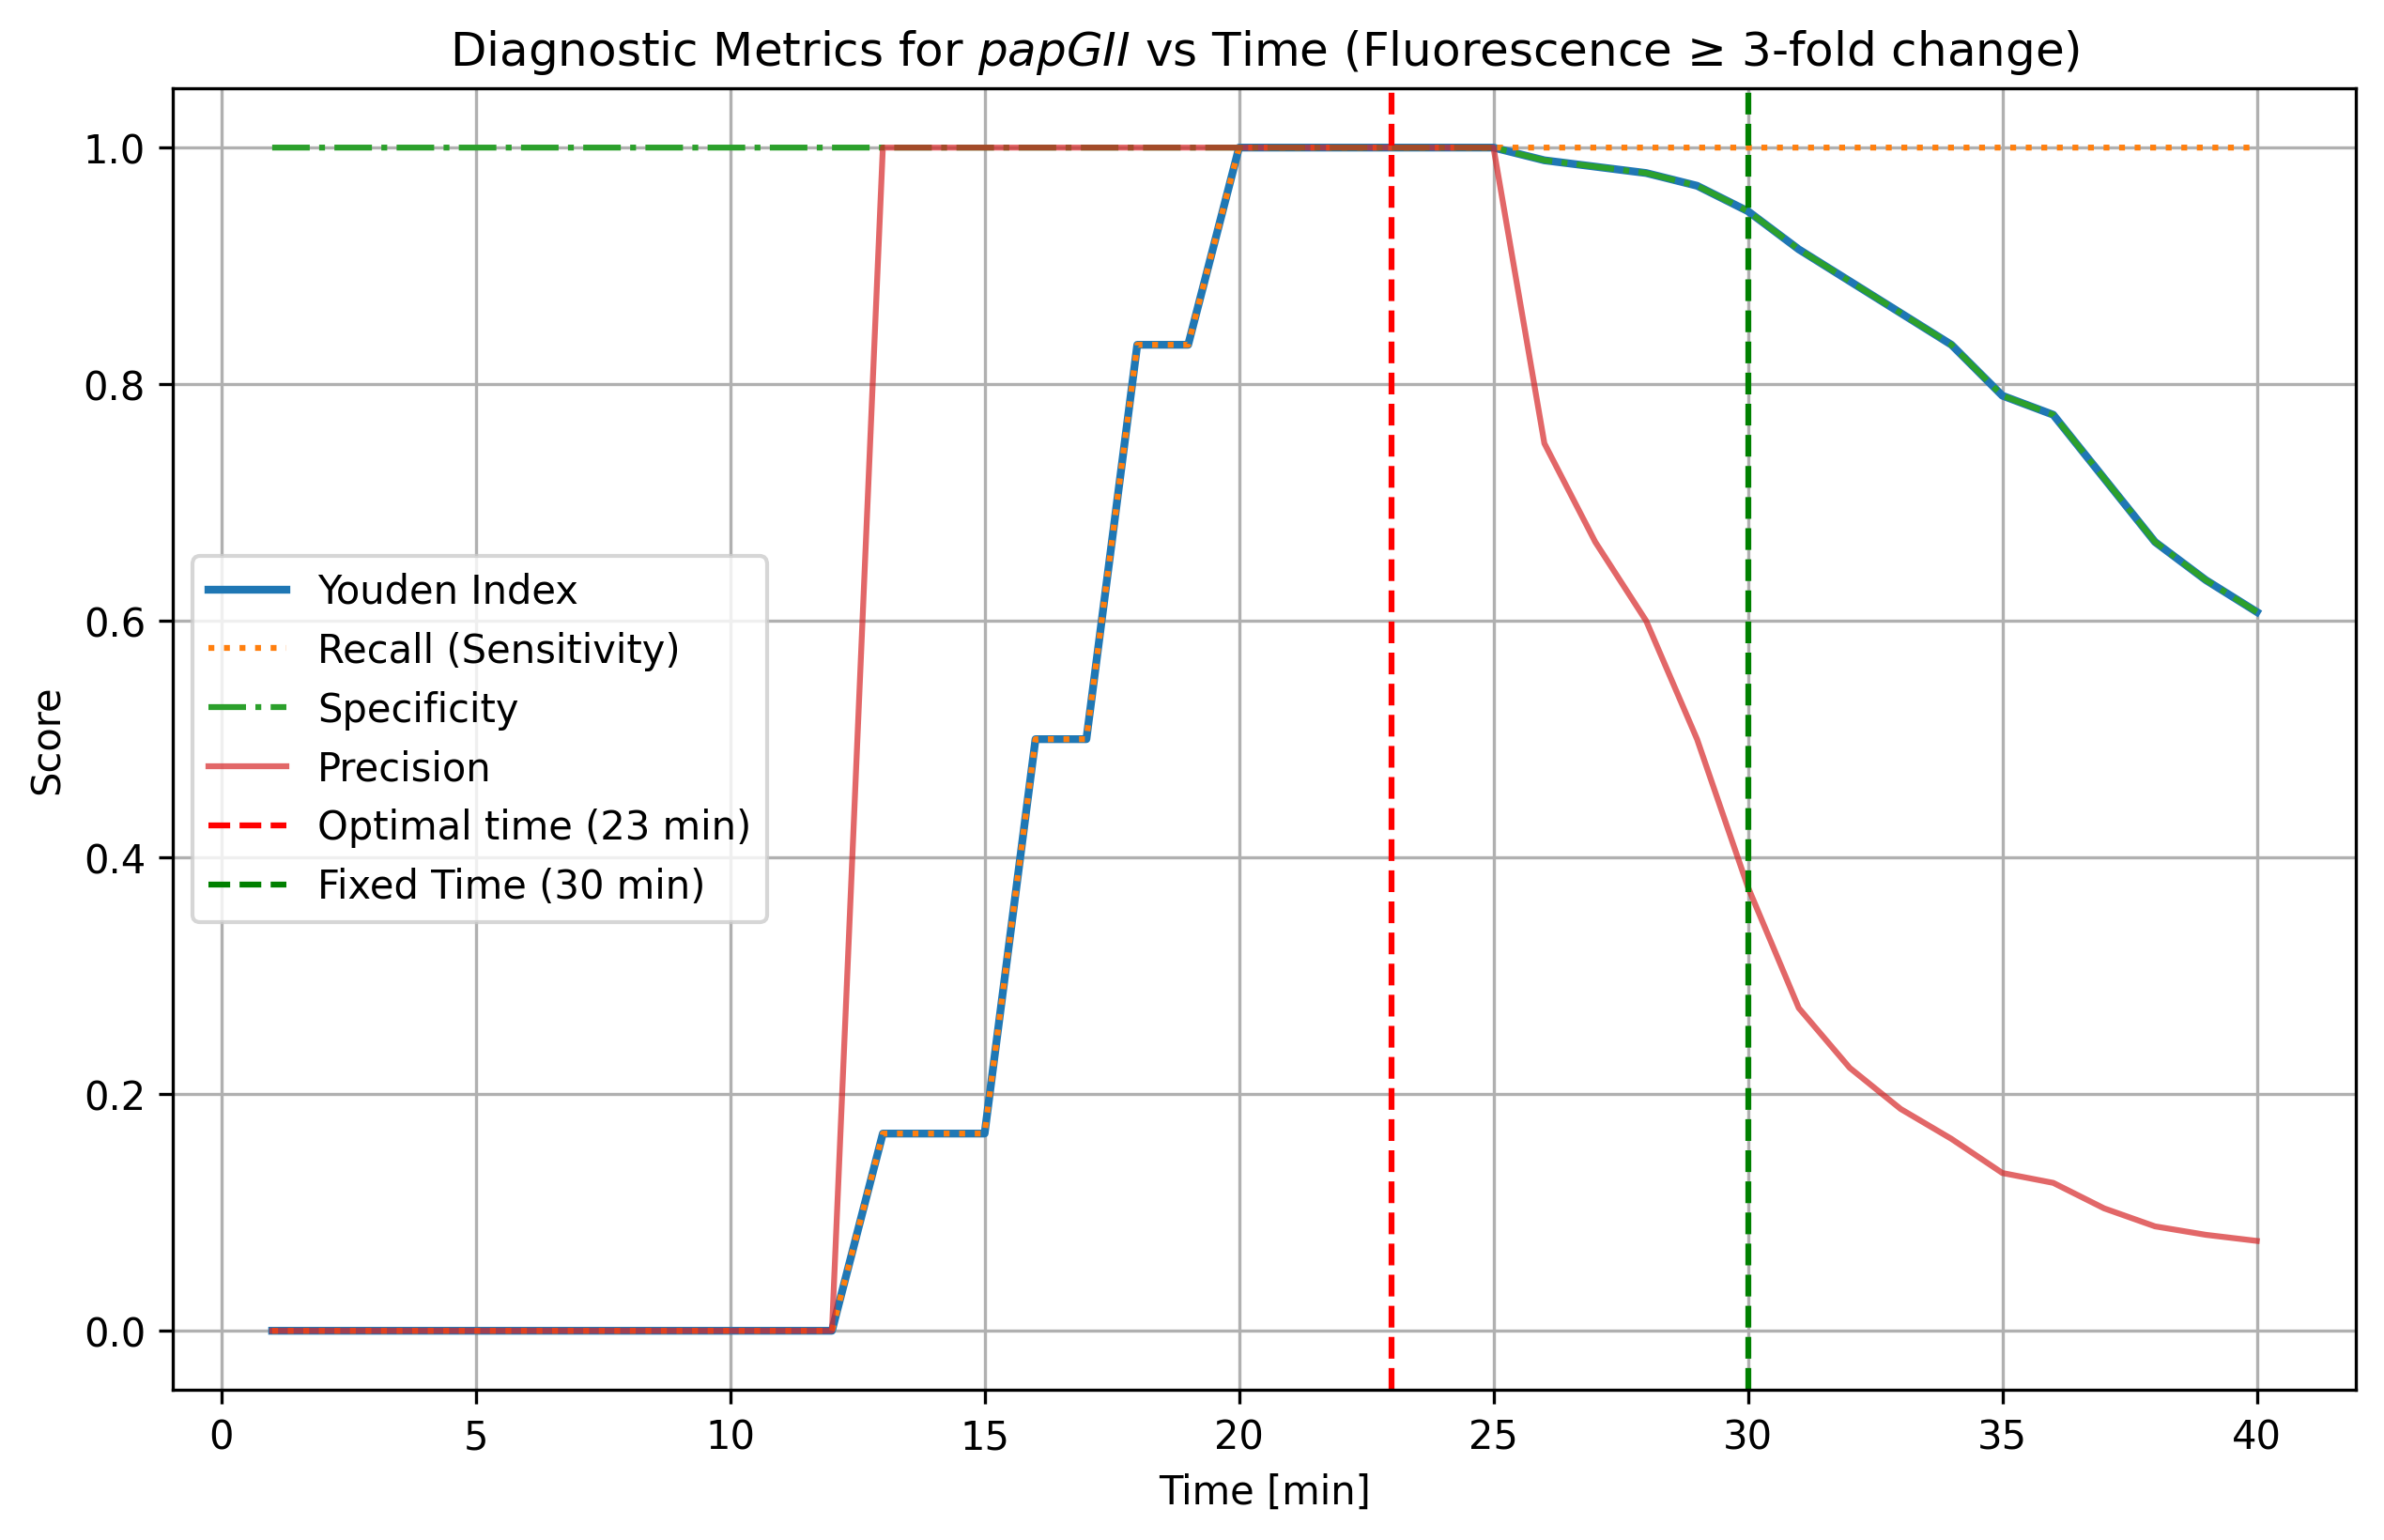

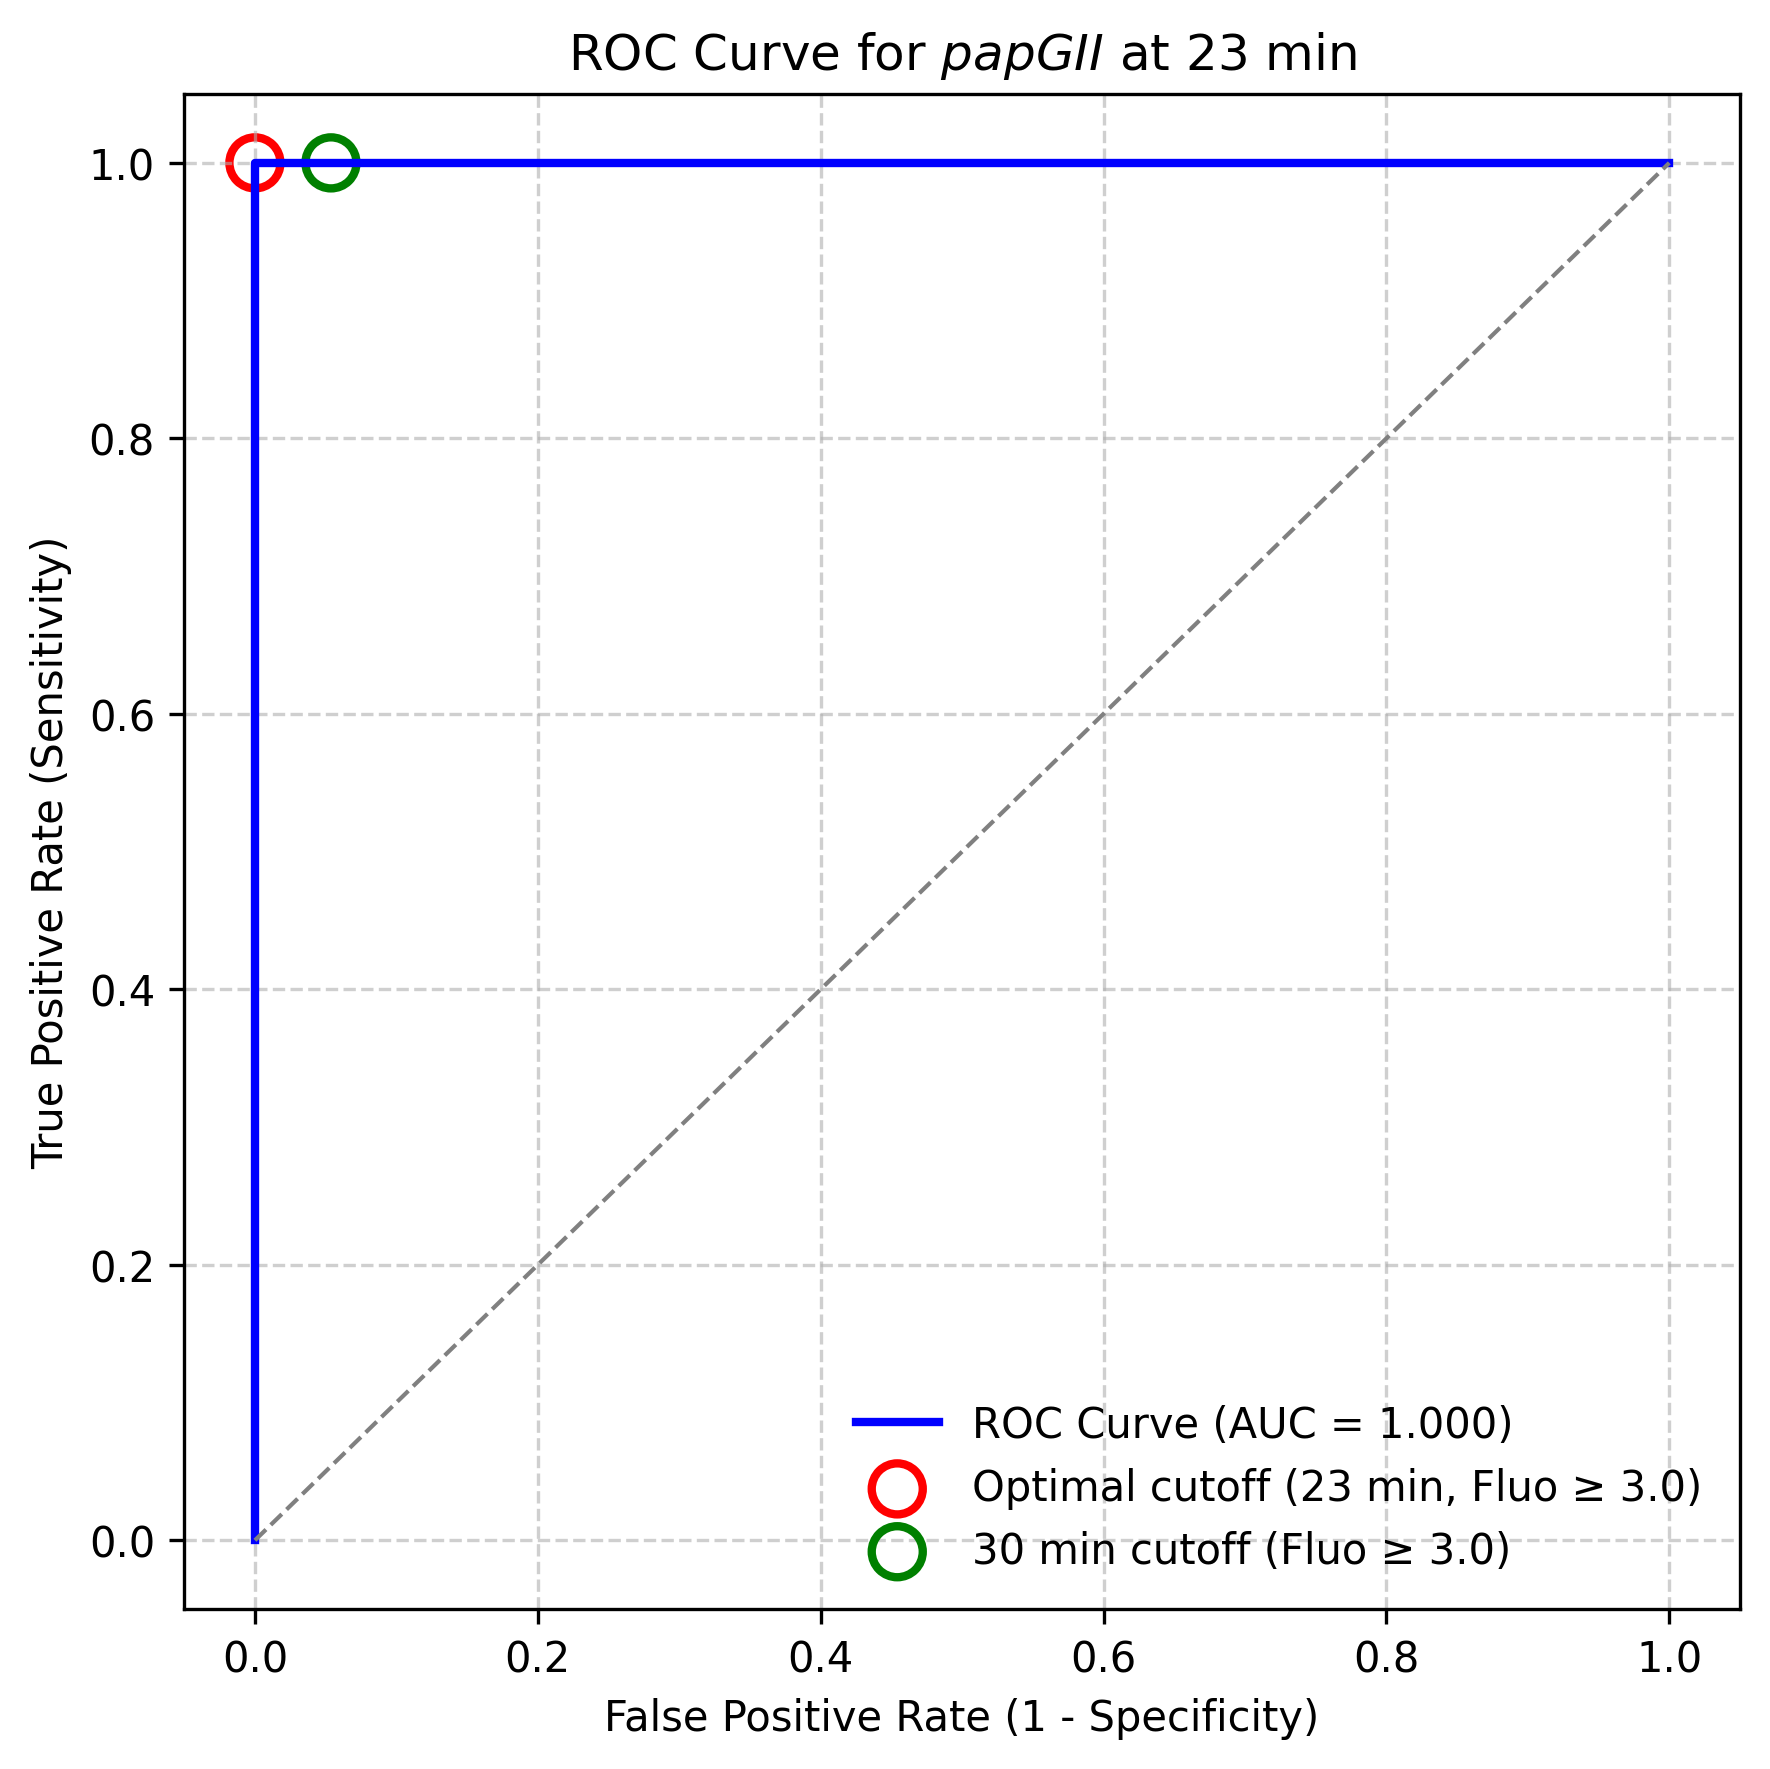

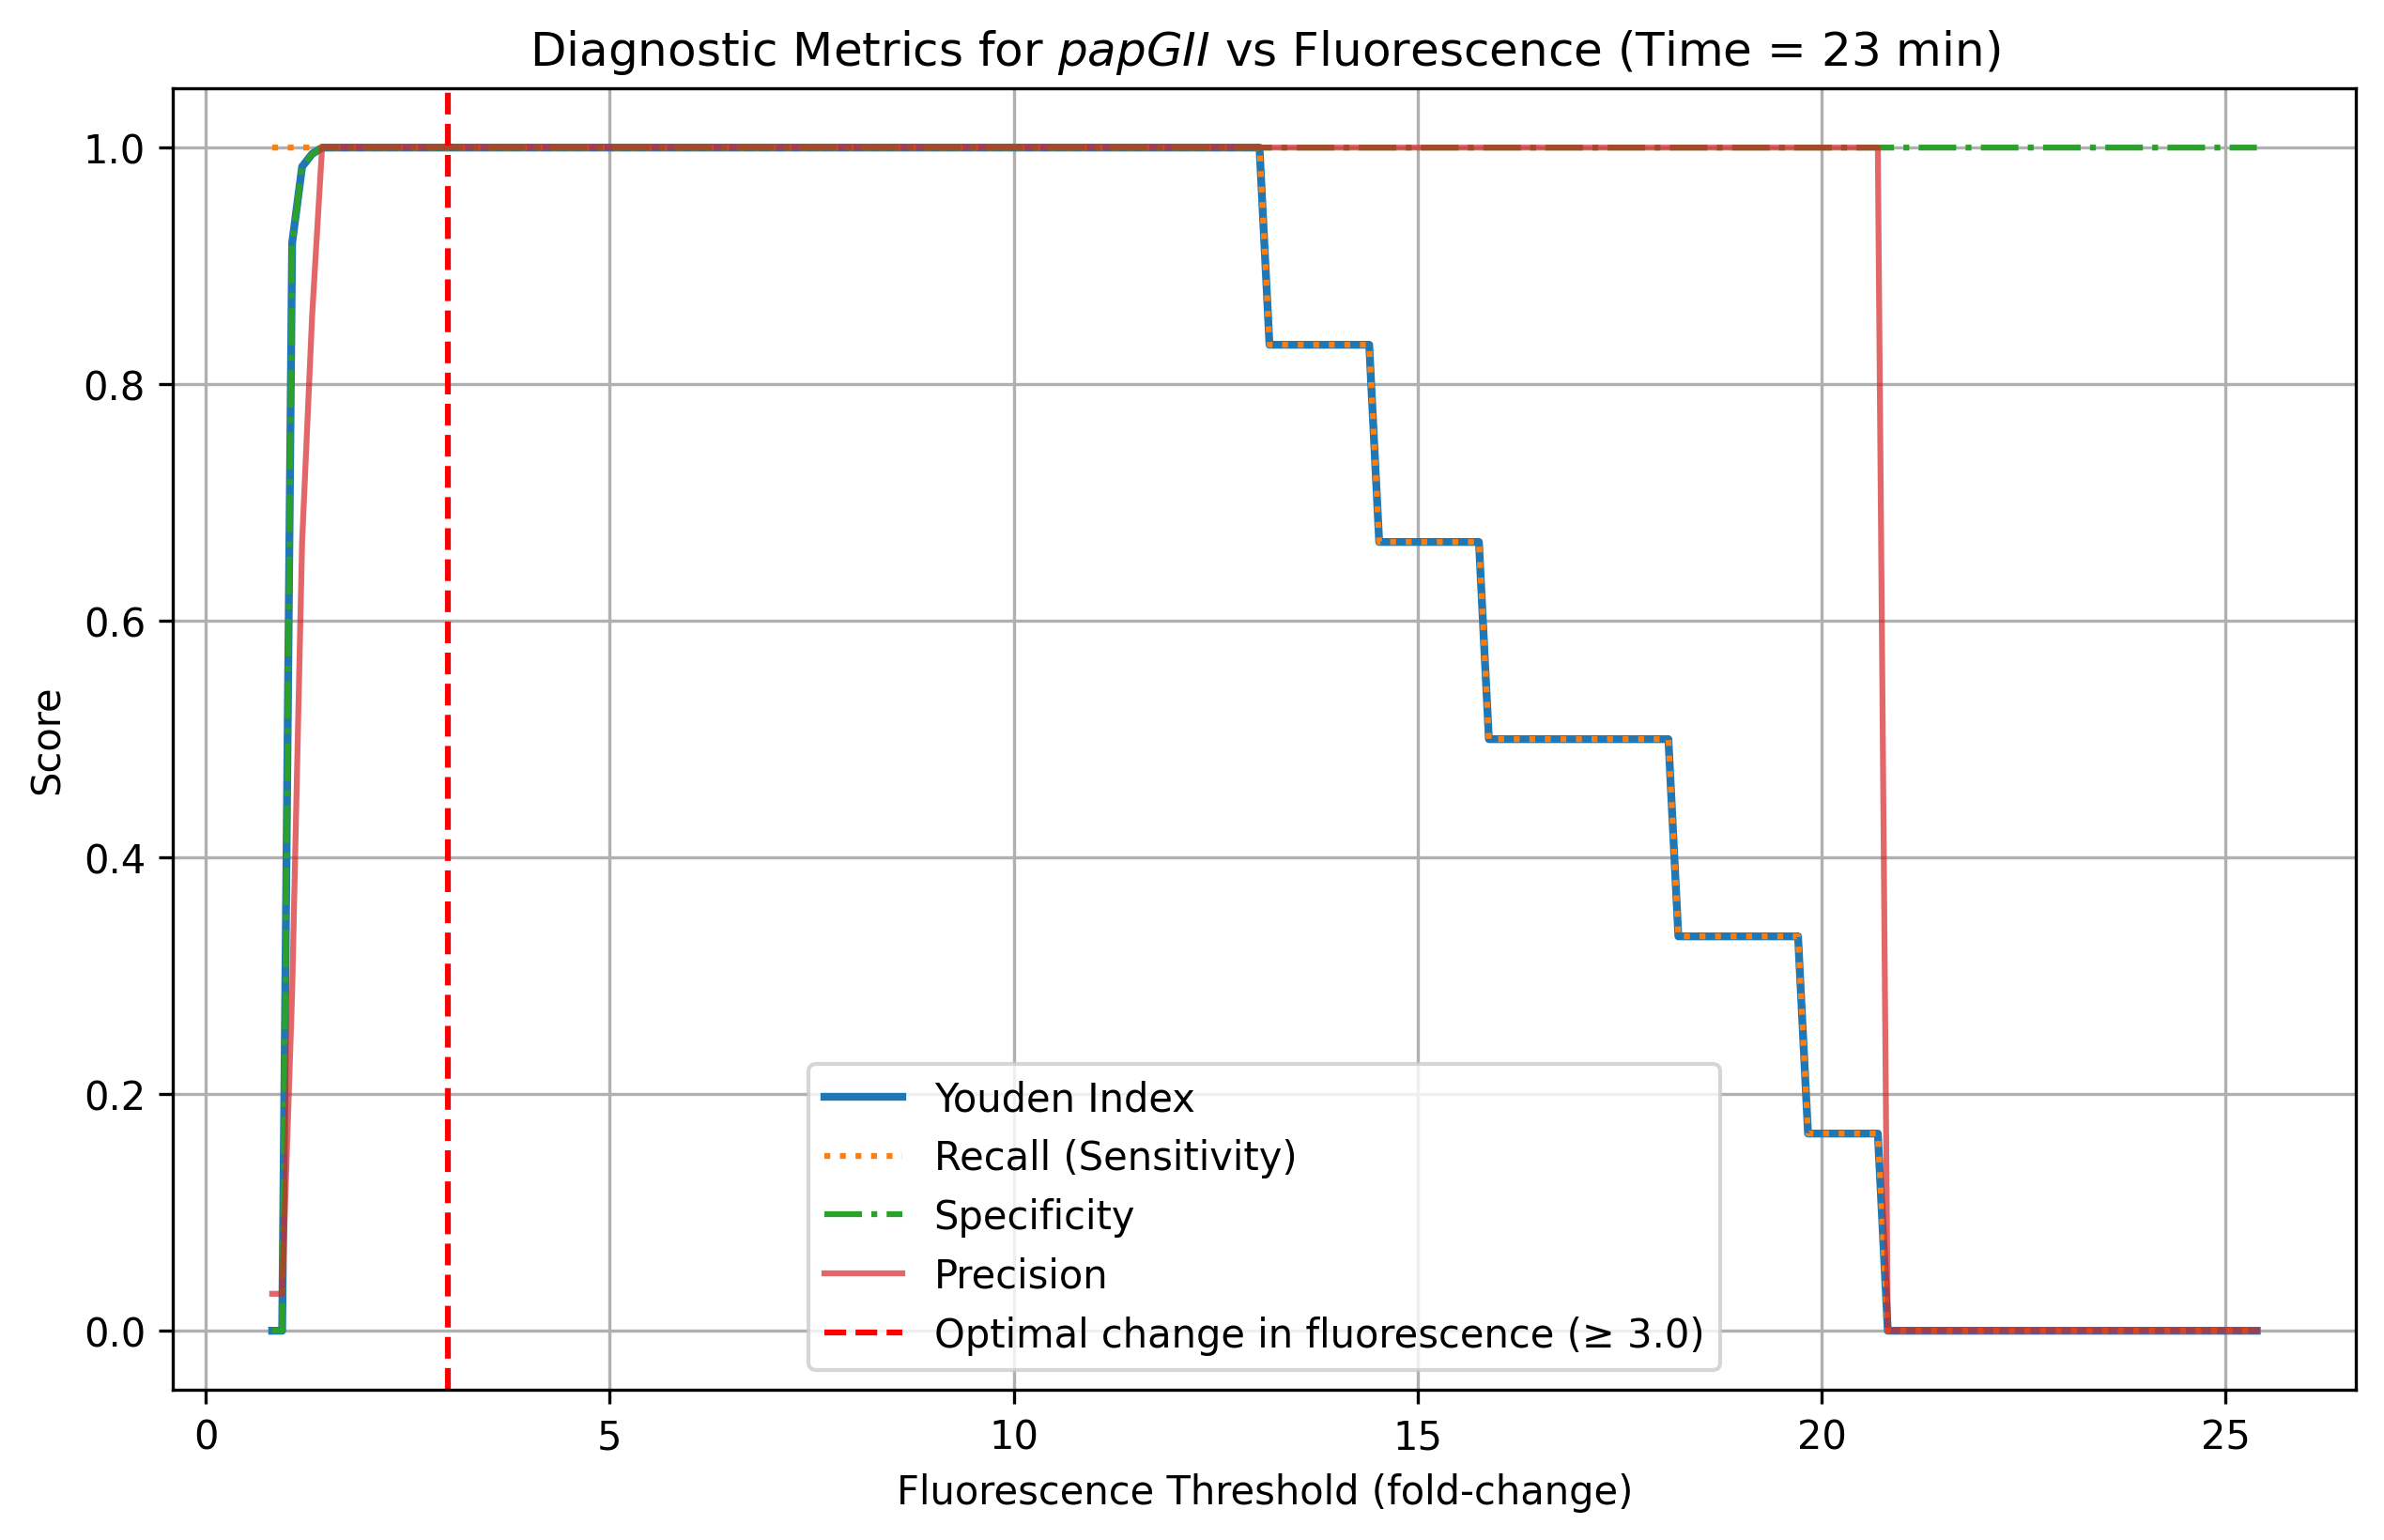

Metrics at cycle = 30, fluorescence = 3.0
Youden Index     = 0.946
Sensitivity      = 1.000
Specificity      = 0.946
Precision        = 0.375
Accuracy         = 0.948
F1-score         = 0.545
TP=6, TN=176, FP=10, FN=0


In [ ]:
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import roc_curve, auc
from pathlib import Path

# set global DPI for all figures
mpl.rcParams['figure.dpi'] = 300

# -----------------------
# Load the data
# -----------------------
DATA_DIR = Path("../data")

# load RAW fluorescence file (not pre-normalized)
fluorescence = pd.read_csv(DATA_DIR / "all_measurements_papg.csv")
culture = pd.read_csv(DATA_DIR / "papg_results.csv")

# Ensure sample names match
culture['sample'] = culture['sample'].astype(str).str.strip()
fluorescence.columns = fluorescence.columns.astype(str).str.strip()

# Reshape fluorescence data to long format
fluorescence_long = fluorescence.melt(
    id_vars=["Cycle"], 
    var_name="sample", 
    value_name="fluorescence"
)

# normalize within code (fold-change relative to Cycle = 1)
baseline = (
    fluorescence_long[fluorescence_long["Cycle"] == 1][["sample", "fluorescence"]]
    .rename(columns={"fluorescence": "baseline"})
)
fluorescence_long = fluorescence_long.merge(baseline, on="sample", how="left")
fluorescence_long["fluorescence"] = fluorescence_long["fluorescence"] / fluorescence_long["baseline"]

# Merge with culture results
data = fluorescence_long.merge(culture, on="sample")

# -----------------------
# CONFIG
# -----------------------
cycle_time = 1.0   # minutes per cycle
fixed_fluo = 3.0
fixed_cycle = 23   # for fluorescence sweep
fixed_cycle_2 = 30

# -----------------------
# Helper: compute metrics
# -----------------------
def metrics_fixed(df, cycle_thresh, fluo_thresh):
    subset = df[df["Cycle"] <= cycle_thresh]
    agg = subset.groupby("sample")["fluorescence"].max().reset_index()
    agg = agg.merge(culture, on="sample")

    agg["pred"] = (agg["fluorescence"] >= fluo_thresh).astype(int)

    tp = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 1))
    tn = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 0))
    fp = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 1))
    fn = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 0))

    sensitivity = tp / (tp + fn) if (tp+fn) > 0 else 0.0   # recall
    specificity = tn / (tn + fp) if (tn+fp) > 0 else 0.0
    precision   = tp / (tp + fp) if (tp+fp) > 0 else 0.0
    accuracy    = (tp + tn) / (tp + tn + fp + fn) if (tp+tn+fp+fn) > 0 else 0.0
    f1          = (2 * tp) / (2 * tp + fp + fn) if (2*tp + fp + fn) > 0 else 0.0
    youden      = sensitivity + specificity - 1

    return youden, sensitivity, specificity, precision, accuracy, f1, tp, tn, fp, fn

# -----------------------
# Sweep cycles at fixed fluorescence
# -----------------------
cycles = np.sort(fluorescence["Cycle"].unique())
results_time = []

for cyc in cycles:
    y, sens, spec, prec, acc, f1, tp, tn, fp, fn = metrics_fixed(data, cyc, fixed_fluo)
    results_time.append((cyc*cycle_time, y, sens, spec, prec, acc, f1, tp, tn, fp, fn))

results_time_df = pd.DataFrame(
    results_time,
    columns=["time_min", "youden", "sensitivity", "specificity", "precision", "accuracy", "f1_score", "TP", "TN", "FP", "FN"]
)

# Best by Youden
best_time = results_time_df.sort_values("youden", ascending=False).iloc[0]["time_min"]

# -----------------------
# Plot metrics vs time (Precision instead of Balanced Accuracy)
# -----------------------
plt.figure(figsize=(10,6))
plt.plot(results_time_df["time_min"], results_time_df["youden"], label="Youden Index", linewidth=2)
plt.plot(results_time_df["time_min"], results_time_df["sensitivity"], label="Recall (Sensitivity)", linestyle=":")
plt.plot(results_time_df["time_min"], results_time_df["specificity"], label="Specificity", linestyle="-.")
plt.plot(results_time_df["time_min"], results_time_df["precision"], label="Precision", linestyle="-", alpha=0.7)

plt.axvline(fixed_cycle, color="red", linestyle="--", label=f"Optimal time ({fixed_cycle} min)")
plt.axvline(fixed_cycle_2, color="green", linestyle="--", label=f"Fixed Time ({fixed_cycle_2} min)")

plt.xlabel("Time [min]")
plt.ylabel("Score")
plt.title("Diagnostic Metrics for $\\it{papGII}$ vs Time (Fluorescence ≥ 3-fold change)")
plt.legend()
plt.grid(True)
plt.show()

# -----------------------
# ROC curve + AUC at best time
# -----------------------
subset = data[data["Cycle"] <= best_time/cycle_time]
agg = subset.groupby("sample")["fluorescence"].max().reset_index()
agg = agg.merge(culture, on="sample")

y_true = agg["culture_result"].values
y_score = agg["fluorescence"].values

fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color="blue", lw=2, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", color="gray", lw=1)

# mark cutoff point at fixed fluorescence = 3.0
row_best = results_time_df.loc[results_time_df["time_min"] == best_time].iloc[0]
fpr_fixed = 1 - row_best["specificity"]
tpr_fixed = row_best["sensitivity"]

plt.scatter(fpr_fixed, tpr_fixed, s=150, facecolors='none', edgecolors='red', linewidths=2,
            label=f"Optimal cutoff ({fixed_cycle} min, Fluo ≥ {fixed_fluo})")

row_best = results_time_df.loc[results_time_df["time_min"] == fixed_cycle_2].iloc[0]
fpr_fixed = 1 - row_best["specificity"]
tpr_fixed = row_best["sensitivity"]

plt.scatter(fpr_fixed, tpr_fixed, s=150, facecolors='none', edgecolors='green', linewidths=2,
            label=f"30 min cutoff (Fluo ≥ {fixed_fluo})")

plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC Curve for $\\it{papGII}$ at 23 min")
plt.legend(frameon=False)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# -----------------------
# Sweep fluorescence at fixed cycle
# -----------------------
fluos = np.linspace(
    fluorescence_long["fluorescence"].min(),
    fluorescence_long["fluorescence"].max(),
    200
)

results_fluo = []
for fluo in fluos:
    y, sens, spec, prec, acc, f1, tp, tn, fp, fn = metrics_fixed(data, fixed_cycle, fluo)
    results_fluo.append((fluo, y, sens, spec, prec, acc, f1, tp, tn, fp, fn))

results_fluo_df = pd.DataFrame(
    results_fluo,
    columns=["fluorescence_thresh", "youden", "sensitivity", "specificity", "precision", "accuracy", "f1_score", "TP", "TN", "FP", "FN"]
)

# Best by Youden at fixed cycle
best_fluo = results_fluo_df.sort_values("youden", ascending=False).iloc[0]["fluorescence_thresh"]

# -----------------------
# Plot metrics vs fluorescence (Precision instead of Balanced Accuracy)
# -----------------------
plt.figure(figsize=(10,6))
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["youden"], label="Youden Index", linewidth=2)
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["sensitivity"], label="Recall (Sensitivity)", linestyle=":")
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["specificity"], label="Specificity", linestyle="-.")
plt.plot(results_fluo_df["fluorescence_thresh"], results_fluo_df["precision"], label="Precision", linestyle="-", alpha=0.7)

plt.axvline(fixed_fluo, color="red", linestyle="--", label="Optimal change in fluorescence (≥ 3.0)")

plt.xlabel("Fluorescence Threshold (fold-change)")
plt.ylabel("Score")
plt.title("Diagnostic Metrics for $\\it{papGII}$ vs Fluorescence (Time = 23 min)")
plt.legend()
plt.grid(True)
plt.show()

# -----------------------
# Metrics at cycle 30, fluorescence = 3.0
# -----------------------
cycle_30 = 30
fluo_3 = 3.0

y, sens, spec, prec, acc, f1, tp, tn, fp, fn = metrics_fixed(data, cycle_30, fluo_3)

print(f"Metrics at cycle = {cycle_30}, fluorescence = {fluo_3:.1f}")
print(f"Youden Index     = {y:.3f}")
print(f"Sensitivity      = {sens:.3f}")
print(f"Specificity      = {spec:.3f}")
print(f"Precision        = {prec:.3f}")
print(f"Accuracy         = {acc:.3f}")
print(f"F1-score         = {f1:.3f}")
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}")


### *uidA* error analysis at a fixed decision rule: false positives/negatives and confusion matrix

This cell performs **case-level error analysis** for the *uidA* assay by identifying false positive (FP) and false negative (FN) samples at a **fixed cycle cutoff and fluorescence threshold**, and by visualizing the resulting confusion matrix.

#### Input files
- Raw fluorescence matrix (wide format): `../data/all_measurements_uida.csv`  
  - `Cycle` column plus one column per sample (sample IDs must match the reference file)
- Culture reference labels: `../data/culture_results.csv`  
  - required columns: `sample`, `culture_result` (`1` = culture positive, `0` = culture negative)

#### Preprocessing
1. **Wide → long reshape**  
   The fluorescence matrix is melted to long format with columns: `Cycle`, `sample`, `fluorescence`.

2. **Fold-change normalization (within code)**  
   Fluorescence is normalized per sample to fold-change relative to **Cycle = 1**:
   \[
   \text{fold-change}_{i,c} = \frac{F_{i,c}}{F_{i,1}}
   \]
   Normalized values replace the `fluorescence` column for all downstream calculations.

3. **Merge with reference labels**  
   The long fluorescence table is merged with the culture labels on `sample`.

4. **Exclusion of NTC**
   The no-template control (`sample == "NTC"`) is removed prior to classification and error analysis.

---

## Fixed decision rule (cycle cutoff + fluorescence threshold)

Parameters used in this cell:
- cycle cutoff: `cycle_thresh = 30`
- fluorescence threshold: `fluorescence_thresh = 3` (fold-change)

For each sample, the score is computed as the **maximum fold-change** up to the cycle cutoff:
\[
S_i(30) = \max_{c \le 30}(\text{fold-change}_{i,c})
\]

Prediction:
- **positive** if \(S_i(30) \ge 3\)
- **negative** otherwise

---

## Metrics and sample-level error extraction

The function `metrics()` computes:
- TP, TN, FP, FN counts
- sensitivity, specificity, precision, recall
- Youden index: \( \text{sensitivity} + \text{specificity} - 1 \)

In addition, it returns the aggregated per-sample table (`agg`) containing:
- the per-sample maximum fold-change up to the cutoff
- ground-truth label (`culture_result`)
- binary prediction (`pred`)

Using this table, the notebook extracts and prints:
- **False positives (FP):** `culture_result = 0` and `pred = 1`
- **False negatives (FN):** `culture_result = 1` and `pred = 0`

These FP and FN sample lists are also saved as CSV files:
- `FP_samples_cycle_30_fluo_3.csv`
- `FN_samples_cycle_30_fluo_3.csv`

---

## Confusion matrix visualization

A custom function (`plot_confusion_blue`) generates a compact 2×2 confusion matrix styled as a blue heatmap. The matrix is arranged as:

|                | Predicted positive | Predicted negative |
|---             |---                 |---                 |
| **True positive**  | TP                | FN                |
| **True negative**  | FP                | TN                |

Figure annotations:
- x-axis: *E. coli* LAMP (predicted)
- y-axis: *E. coli* culture (reference)

The figure is saved as:
- `confusion_matrix_pastel_compact_cycle_30_fluo_3.png`

All plots are rendered at high resolution (`figure.dpi = 300`) for publication use.


False Positive samples (Cycle 30, Fluorescence 3):
    sample  fluorescence  culture_result  pred
5      103      9.656689               0     1
13     110     13.453624               0     1
21     118      7.217943               0     1
29     125      8.467856               0     1
105     21      6.313756               0     1
126     40      5.662912               0     1
138     51      5.394764               0     1
158      7     21.329962               0     1

False Negative samples (Cycle 30, Fluorescence 3):
   sample  fluorescence  culture_result  pred
9     107      1.191247               1     0
34     13      1.087714               1     0
62    155      1.099791               1     0
63    156      1.384642               1     0
82    173      1.208625               1     0


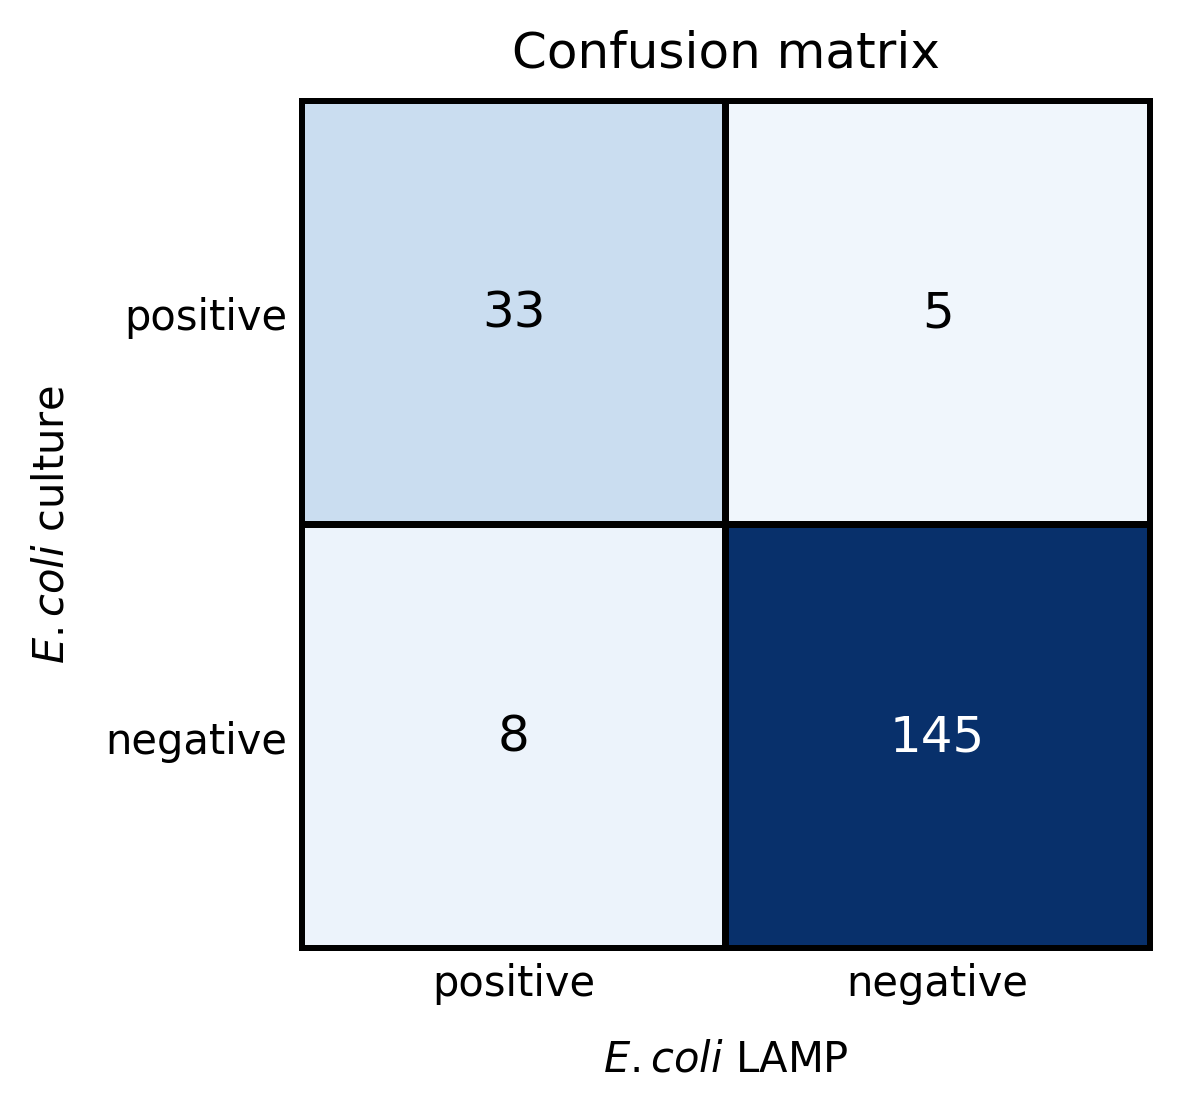

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from pathlib import Path

# Set global DPI for all figures
mpl.rcParams['figure.dpi'] = 300

# -----------------------
# Load the data (relative paths)
# -----------------------
DATA_DIR = Path("../data")  # notebook in repo/notebook/, data in repo/data/

# load RAW fluorescence matrix (not pre-normalized)
fluorescence = pd.read_csv(DATA_DIR / "all_measurements_uida.csv")
culture = pd.read_csv(DATA_DIR / "culture_results.csv")

# Ensure sample names match
culture['sample'] = culture['sample'].astype(str).str.strip()
fluorescence.columns = fluorescence.columns.astype(str).str.strip()

# Reshape fluorescence data to long format
fluorescence_long = fluorescence.melt(
    id_vars=["Cycle"],
    var_name="sample",
    value_name="fluorescence"
)

# normalize within code (fold-change relative to Cycle = 1)
baseline = (
    fluorescence_long[fluorescence_long["Cycle"] == 1][["sample", "fluorescence"]]
    .rename(columns={"fluorescence": "baseline"})
)
fluorescence_long = fluorescence_long.merge(baseline, on="sample", how="left")
fluorescence_long["fluorescence"] = fluorescence_long["fluorescence"] / fluorescence_long["baseline"]

# Merge with culture results
data = fluorescence_long.merge(culture, on="sample")

# -----------------------
# Remove the "NTC" sample
# -----------------------
data = data[data['sample'] != 'NTC']

# -----------------------
# Function to compute metrics
# -----------------------
def metrics(df, cycle_thresh, fluo_thresh):
    subset = df[df["Cycle"] <= cycle_thresh]

    agg = subset.groupby("sample")["fluorescence"].max().reset_index()
    agg = agg.merge(culture, on="sample")

    agg["pred"] = (agg["fluorescence"] >= fluo_thresh).astype(int)

    tp = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 1))
    tn = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 0))
    fp = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 1))
    fn = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 0))

    sensitivity = tp / (tp + fn) if (tp+fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn+fp) > 0 else 0
    precision = tp / (tp + fp) if (tp+fp) > 0 else 0
    recall = sensitivity
    youden = sensitivity + specificity - 1

    return youden, sensitivity, specificity, precision, recall, tp, tn, fp, fn, agg

# -----------------------
# Find FP and FN for specific conditions (Cycle 30 and Fluorescence Threshold 3)
# -----------------------

# Set Cycle and Fluorescence Threshold
cycle_thresh = 30
fluorescence_thresh = 3

# Get the metrics and corresponding sample data
youden, sens, spec, prec, rec, tp, tn, fp, fn, agg_data = metrics(data, cycle_thresh, fluorescence_thresh)

# Extract FP and FN samples
fp_samples = agg_data[(agg_data["culture_result"] == 0) & (agg_data["pred"] == 1)]
fn_samples = agg_data[(agg_data["culture_result"] == 1) & (agg_data["pred"] == 0)]

# Display the results
print(f"False Positive samples (Cycle {cycle_thresh}, Fluorescence {fluorescence_thresh}):")
print(fp_samples[["sample", "fluorescence", "culture_result", "pred"]])

print(f"\nFalse Negative samples (Cycle {cycle_thresh}, Fluorescence {fluorescence_thresh}):")
print(fn_samples[["sample", "fluorescence", "culture_result", "pred"]])

# Optional: You can also save these FP and FN samples to CSV
#fp_samples.to_csv(f"FP_samples_cycle_{cycle_thresh}_fluo_{fluorescence_thresh}.csv", index=False)
#fn_samples.to_csv(f"FN_samples_cycle_{cycle_thresh}_fluo_{fluorescence_thresh}.csv", index=False)

def plot_confusion_blue(tp, tn, fp, fn, savepath=None):
    """
    2x2 confusion matrix styled like the classic blue heatmap.
    - Title on top: 'Confusion matrix'
    - x-axis (bottom): italic uidA LAMP with 'positive'/'negative'
    - y-axis (left): italic E. coli culture with 'positive'/'negative'
    - Outer border and inner lines have identical visible thickness and align perfectly.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.collections import LineCollection
    from matplotlib.patches import Rectangle

    counts = np.array([[tp, fn],
                       [fp, tn]], dtype=int)
    vmax = counts.max()

    fig, ax = plt.subplots(figsize=(3.9, 3.6))

    # Heatmap
    ax.imshow(
        counts, cmap="Blues", vmin=0, vmax=vmax,
        extent=(0, 2, 2, 0), origin="upper",
        interpolation="none", aspect="equal", zorder=0
    )

    # Title and axes
    ax.set_title("Confusion matrix", pad=8)
    ax.set_xlabel(r"$\it{E. coli}$ LAMP", labelpad=8)       # x on bottom
    ax.set_ylabel(r"$\it{E. coli}$ culture", labelpad=8)
    ax.set_xticks([0.5, 1.5], labels=["positive", "negative"])
    ax.set_yticks([0.5, 1.5], labels=["positive", "negative"])
    ax.tick_params(axis='both', which='both', length=0)

    # ---- Borders & gridlines (aligned, equal thickness) ----
    lw = 1.4

    # Outer border as a single rectangle; draw unclipped so full width is visible
    border = Rectangle(
        (0, 0), 2, 2, fill=False, linewidth=lw,
        edgecolor="black", antialiased=False, joinstyle="miter", zorder=3
    )
    border.set_clip_on(False)   # prevents half-clipping -> same apparent width
    ax.add_patch(border)

    # Inner cross lines; butt caps (no overhang), clipped to axes for perfect join
    segs = [[(0, 1), (2, 1)],   # horizontal middle
            [(1, 0), (1, 2)]]   # vertical middle
    lc = LineCollection(
        segs, colors="black", linewidths=lw,
        antialiased=False, capstyle="butt", joinstyle="miter", zorder=3
    )
    lc.set_clip_on(True)
    lc.set_snap(False)
    ax.add_collection(lc)

    # Remove default spines
    for s in ax.spines.values():
        s.set_visible(False)

    # Numbers (white on dark cells, black on light cells)
    thresh = vmax * 0.5 if vmax > 0 else 0
    for i in range(2):
        for j in range(2):
            val = counts[i, j]
            color = "white" if val >= thresh else "black"
            ax.text(j + 0.5, i + 0.5, f"{val}",
                    ha="center", va="center", fontsize=12, color=color, zorder=4)

    # Exact limits so lines meet the border precisely
    ax.set_xlim(0, 2)
    ax.set_ylim(2, 0)

    plt.tight_layout(pad=0.35)
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()

# Example call
plot_confusion_blue(
    tp=tp, tn=tn, fp=fp, fn=fn,
    savepath=None
)



### Corresponding analysis for *papGII* error analysis at a fixed decision rule: false positives/negatives and confusion matrix

This cell performs **case-level error analysis** for the *uidA* assay by identifying false positive (FP) and false negative (FN) samples at a **fixed cycle cutoff and fluorescence threshold**, and by visualizing the resulting confusion matrix.

#### Input files
- Raw fluorescence matrix (wide format): `../data/all_measurements_papg.csv`  
  - `Cycle` column plus one column per sample (sample IDs must match the reference file)
- Culture reference labels: `../data/papg_results.csv`  
  - required columns: `sample`, `papg_result` (`1` = papGII WGS positive, `0` = papGII WGS negative)


False Positive samples (Cycle 23, Fluorescence 3):
Empty DataFrame
Columns: [sample, fluorescence, culture_result, pred]
Index: []

False Negative samples (Cycle 23, Fluorescence 3):
Empty DataFrame
Columns: [sample, fluorescence, culture_result, pred]
Index: []


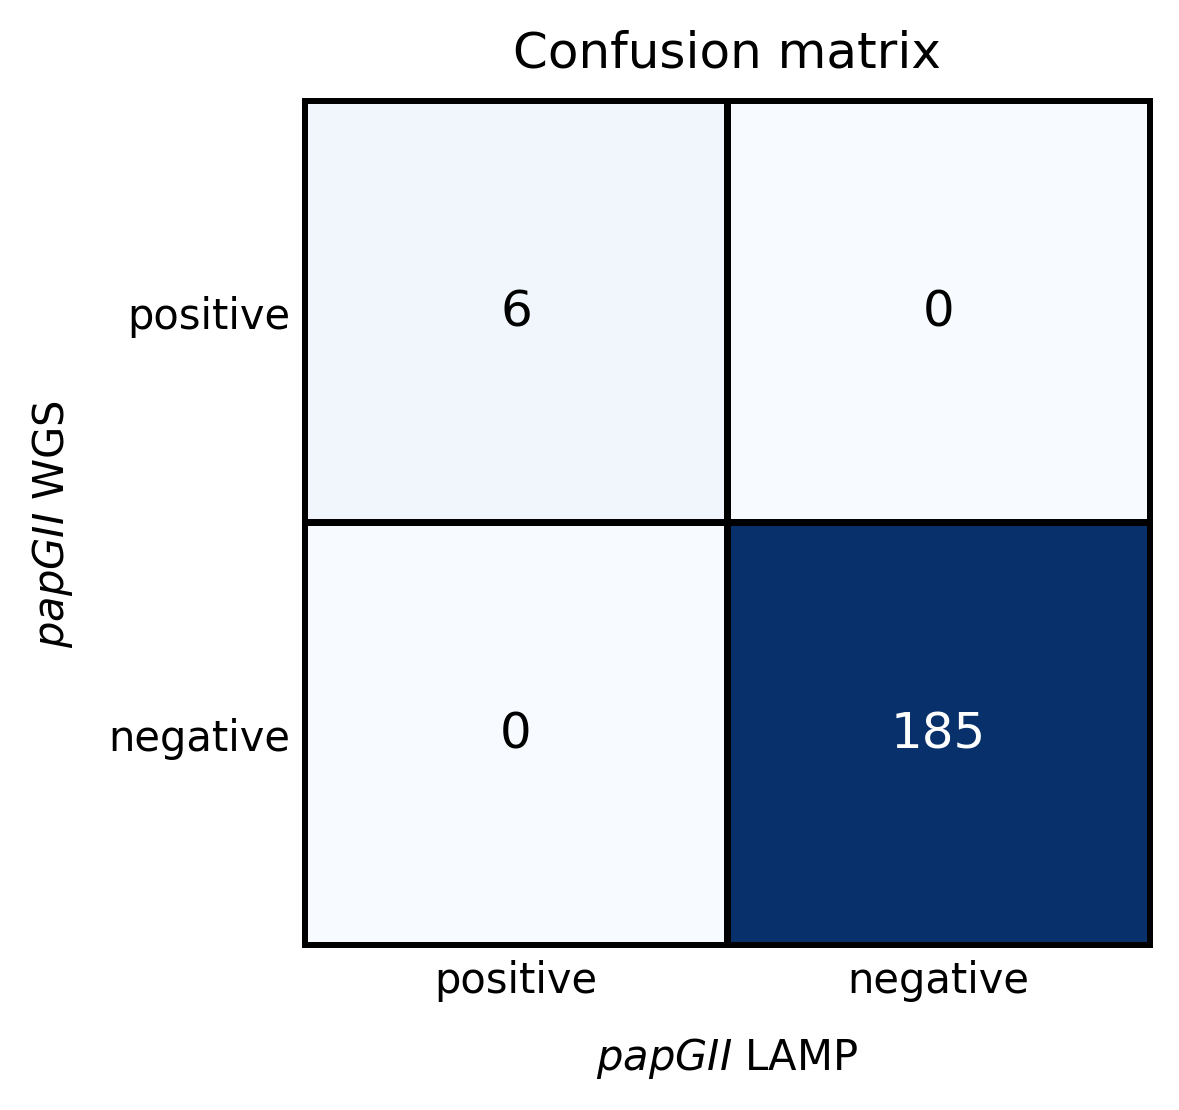

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from pathlib import Path

# Set global DPI for all figures
mpl.rcParams['figure.dpi'] = 300

# -----------------------
# Load the data
# -----------------------
DATA_DIR = Path("../data")  # notebook in repo/notebook/, data in repo/data/

# load RAW fluorescence file (not pre-normalized)
fluorescence = pd.read_csv(DATA_DIR / "all_measurements_papg.csv")
culture = pd.read_csv(DATA_DIR / "papg_results.csv")

# Ensure sample names match
culture['sample'] = culture['sample'].astype(str).str.strip()
fluorescence.columns = fluorescence.columns.astype(str).str.strip()

# Reshape fluorescence data to long format
fluorescence_long = fluorescence.melt(
    id_vars=["Cycle"], 
    var_name="sample", 
    value_name="fluorescence"
)

# normalize within code (fold-change relative to Cycle = 1)
baseline = (
    fluorescence_long[fluorescence_long["Cycle"] == 1][["sample", "fluorescence"]]
    .rename(columns={"fluorescence": "baseline"})
)
fluorescence_long = fluorescence_long.merge(baseline, on="sample", how="left")
fluorescence_long["fluorescence"] = fluorescence_long["fluorescence"] / fluorescence_long["baseline"]

# Merge with culture results
data = fluorescence_long.merge(culture, on="sample")

# -----------------------
# Remove the "NTC" sample
# -----------------------
data = data[data['sample'] != 'NTC']

# -----------------------
# Function to compute metrics
# -----------------------
def metrics(df, cycle_thresh, fluo_thresh):
    subset = df[df["Cycle"] <= cycle_thresh]
    
    agg = subset.groupby("sample")["fluorescence"].max().reset_index()
    agg = agg.merge(culture, on="sample")

    agg["pred"] = (agg["fluorescence"] >= fluo_thresh).astype(int)

    tp = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 1))
    tn = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 0))
    fp = np.sum((agg["culture_result"] == 0) & (agg["pred"] == 1))
    fn = np.sum((agg["culture_result"] == 1) & (agg["pred"] == 0))

    sensitivity = tp / (tp + fn) if (tp+fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn+fp) > 0 else 0
    precision = tp / (tp + fp) if (tp+fp) > 0 else 0
    recall = sensitivity
    youden = sensitivity + specificity - 1
    
    return youden, sensitivity, specificity, precision, recall, tp, tn, fp, fn, agg

# -----------------------
# Find FP and FN for specific conditions (Cycle 30 and Fluorescence Threshold 3)
# -----------------------

# Set Cycle and Fluorescence Threshold
cycle_thresh = 23
fluorescence_thresh = 3

# Get the metrics and corresponding sample data
youden, sens, spec, prec, rec, tp, tn, fp, fn, agg_data = metrics(data, cycle_thresh, fluorescence_thresh)

# Extract FP and FN samples
fp_samples = agg_data[(agg_data["culture_result"] == 0) & (agg_data["pred"] == 1)]
fn_samples = agg_data[(agg_data["culture_result"] == 1) & (agg_data["pred"] == 0)]

# Display the results
print(f"False Positive samples (Cycle {cycle_thresh}, Fluorescence {fluorescence_thresh}):")
print(fp_samples[["sample", "fluorescence", "culture_result", "pred"]])

print(f"\nFalse Negative samples (Cycle {cycle_thresh}, Fluorescence {fluorescence_thresh}):")
print(fn_samples[["sample", "fluorescence", "culture_result", "pred"]])

# Optional: You can also save these FP and FN samples to CSV
#fp_samples.to_csv(f"FP_samples_cycle_{cycle_thresh}_fluo_{fluorescence_thresh}.csv", index=False)
#fn_samples.to_csv(f"FN_samples_cycle_{cycle_thresh}_fluo_{fluorescence_thresh}.csv", index=False)

def plot_confusion_blue(tp, tn, fp, fn, savepath=None):
    """
    2x2 confusion matrix styled like the classic blue heatmap.
    - Title on top: 'Confusion matrix'
    - x-axis (bottom): italic uidA LAMP with 'positive'/'negative'
    - y-axis (left): italic E. coli culture with 'positive'/'negative'
    - Outer border and inner lines have identical visible thickness and align perfectly.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.collections import LineCollection
    from matplotlib.patches import Rectangle

    counts = np.array([[tp, fn],
                       [fp, tn]], dtype=int)
    vmax = counts.max()

    fig, ax = plt.subplots(figsize=(3.9, 3.6))

    # Heatmap
    ax.imshow(
        counts, cmap="Blues", vmin=0, vmax=vmax,
        extent=(0, 2, 2, 0), origin="upper",
        interpolation="none", aspect="equal", zorder=0
    )

    # Title and axes
    ax.set_title("Confusion matrix", pad=8)
    ax.set_xlabel(r"$\it{papGII}$ LAMP", labelpad=8)       # x on bottom
    ax.set_ylabel(r"$\it{papGII}$ WGS", labelpad=8)
    ax.set_xticks([0.5, 1.5], labels=["positive", "negative"])
    ax.set_yticks([0.5, 1.5], labels=["positive", "negative"])
    ax.tick_params(axis='both', which='both', length=0)

    # ---- Borders & gridlines (aligned, equal thickness) ----
    lw = 1.4

    # Outer border as a single rectangle; draw unclipped so full width is visible
    border = Rectangle(
        (0, 0), 2, 2, fill=False, linewidth=lw,
        edgecolor="black", antialiased=False, joinstyle="miter", zorder=3
    )
    border.set_clip_on(False)   # prevents half-clipping -> same apparent width
    ax.add_patch(border)

    # Inner cross lines; butt caps (no overhang), clipped to axes for perfect join
    segs = [[(0, 1), (2, 1)],   # horizontal middle
            [(1, 0), (1, 2)]]   # vertical middle
    lc = LineCollection(
        segs, colors="black", linewidths=lw,
        antialiased=False, capstyle="butt", joinstyle="miter", zorder=3
    )
    lc.set_clip_on(True)
    lc.set_snap(False)
    ax.add_collection(lc)

    # Remove default spines
    for s in ax.spines.values():
        s.set_visible(False)

    # Numbers (white on dark cells, black on light cells)
    thresh = vmax * 0.5 if vmax > 0 else 0
    for i in range(2):
        for j in range(2):
            val = counts[i, j]
            color = "white" if val >= thresh else "black"
            ax.text(j + 0.5, i + 0.5, f"{val}",
                    ha="center", va="center", fontsize=12, color=color, zorder=4)

    # Exact limits so lines meet the border precisely
    ax.set_xlim(0, 2)
    ax.set_ylim(2, 0)

    plt.tight_layout(pad=0.35)
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()

# Example call
plot_confusion_blue(
    tp=tp, tn=tn, fp=fp, fn=fn,
    savepath=None
)
